# FLAJ S.A.S. · Clasificación de emociones en tweets de clientes de Dell
## Proyecto final · Procesamiento de Lenguaje Natural

Somos FLAJ S.A.S, una empresa especializada en analítica de datos avanzada y desarrollo de soluciones de Inteligencia Artificial. Ayudamos a las organizaciones a transformar sus datos en activos estratégicos mediante la implementación de modelos de Machine Learning a la medida, optimizando procesos y potenciando la toma de decisiones basada en evidencia.

Actualmente lideramos un proyecto de consultoría para Dell. El objetivo es dotar a la compañía de una herramienta capaz de **clasificar automáticamente la emoción de los tweets que la mencionan** en una de **8 categorías**, para priorizar la atención de los mensajes de **ira (`anger`) y disgusto (`disgust`)**.

**Cómo está organizado este cuaderno**

| Sección | Contenido | Requisito |
|---|---|---|
| 0 | Configuración y carga | — |
| 1 | Formulación del problema | 4.1 |
| 2 | Datos: origen, licencia, diccionario, etiquetas y auditoría | 4.2 |
| 3 | Limpieza y preparación del texto (flujo único) | 4.2 |
| 4 | Partición sin fuga y data card | 4.2 |
| 5 | Baseline: TF-IDF + regresión logística | 4.3 |
| 6 | Redes recurrentes: SimpleRNN, LSTM, GRU y BiLSTM | 4.3 |
| 7 | Transformer: BERT (`bert-base-uncased`) | 4.3 |
| 8 | Evaluación final en prueba (una sola vez), abstención y segmentos | 4.4 |
| 9 | Análisis de errores | 4.4 |
| 10 | Robustez, contrafactuales y entradas fuera de dominio | 4.4 |
| 11 | Eficiencia y costo | 4.4 |
| 12 | Gobierno y operación | 4.5 |
| 13 | Conclusiones y recomendación | — |

# 0. Configuración y carga

Se fijan la semilla, las rutas y una carpeta `artefactos/` donde se guardan los modelos y los registros. `MODO_RAPIDO` solo sirve para probar que el cuaderno corre de principio a fin en pocos minutos (usa una submuestra y menos épocas). **Todos los resultados de este cuaderno se obtuvieron con `MODO_RAPIDO = False`.**

In [1]:
import os, re, html, time, json, hashlib, platform, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_colwidth', 120)

SEMILLA = 42
np.random.seed(SEMILLA)
RUTA_DATOS = 'sentiment-emotion-labelled_Dell_tweets.csv'
DIR_ART = 'artefactos'
os.makedirs(DIR_ART, exist_ok=True)
MODO_RAPIDO = os.environ.get('DELL_MODO_RAPIDO', '0') == '1'   # False en la ejecución oficial
T_INICIO_CUADERNO = time.perf_counter()

df = pd.read_csv(RUTA_DATOS)
HASH_DATOS = hashlib.sha256(open(RUTA_DATOS, 'rb').read()).hexdigest()
if MODO_RAPIDO:
    df = df.sample(3000, random_state=SEMILLA).sort_index()
print(f'Modo rápido: {MODO_RAPIDO}')
print(f'Filas: {df.shape[0]} | Columnas: {df.shape[1]}')
print(f'Huella SHA-256 del archivo (trazabilidad): {HASH_DATOS[:16]}...')

Modo rápido: False
Filas: 24970 | Columnas: 9
Huella SHA-256 del archivo (trazabilidad): 5fbdbc48e06662e7...


# 1. Formulación del problema

## 1.1 Usuario y decisión que apoya el sistema

- **Usuario:** el equipo de atención al cliente en redes sociales de Dell (*social care*).
- **Decisión que apoya:** **qué tweets atender o escalar primero.** Un tweet con ira o disgusto es un cliente molesto que puede escalar públicamente su queja; el sistema lo marca para que una persona lo atienda antes.
- **Qué no decide el sistema:** no responde al cliente ni toma acciones sobre su cuenta. Solo ordena y etiqueta; la respuesta siempre la da una persona.

## 1.2 Situación actual: volumen, tiempo y costo

Hoy la lectura y clasificación de las menciones es manual. El volumen sale de los datos; el tiempo y el costo por tweet son **supuestos** acordados con el equipo del proyecto.

In [2]:
# ---- SUPUESTOS DE NEGOCIO (editables; no son cifras entregadas por Dell) ----
SUP_MIN_POR_TWEET  = 1.0        # minutos que tarda una persona en leer y clasificar un tweet
SUP_COSTO_HORA_COP = 100_000    # costo de una hora de analista, en pesos colombianos

fechas = pd.to_datetime(df['Datetime'])
dias = (fechas.max() - fechas.min()).days + 1
tweets_dia = len(df) / dias
horas_mes = tweets_dia * 30 * SUP_MIN_POR_TWEET / 60
costo_mes = horas_mes * SUP_COSTO_HORA_COP

situacion = pd.DataFrame({
    'Indicador': ['Periodo de los datos', 'Tweets en el periodo', 'Tweets por día (promedio)', 'Tweets por mes',
                  'Minutos por tweet (supuesto)', 'Horas de analista por mes', 'Costo por mes (COP)', 'Costo por año (COP)'],
    'Valor': [f'{fechas.min():%Y-%m-%d} a {fechas.max():%Y-%m-%d} ({dias} días)', f'{len(df):,}', f'{tweets_dia:,.0f}',
              f'{tweets_dia * 30:,.0f}', f'{SUP_MIN_POR_TWEET:g}', f'{horas_mes:,.1f}', f'{costo_mes:,.0f}', f'{costo_mes * 12:,.0f}'],
})
display(situacion.set_index('Indicador'))

,Valor
Indicador,
Periodo de los datos,2022-01-01 a 2022-09-30 (273 días)
Tweets en el periodo,"24,970"
Tweets por día (promedio),91
Tweets por mes,"2,744"
Minutos por tweet (supuesto),1
Horas de analista por mes,45.7
Costo por mes (COP),"4,573,260"
Costo por año (COP),"54,879,121"


**Lectura.** Con el volumen del conjunto de datos (menciones públicas a @Dell en Twitter), clasificar todo a mano exige unas decenas de horas de analista al mes. El volumen real de Dell en todos sus canales es seguramente mayor, así que el costo calculado es un piso, no un techo. Además del costo, el problema es el **tiempo de respuesta**: un tweet molesto que se lee horas después ya pudo escalar.

## 1.3 Entrada, salida, unidad de análisis y frecuencia

| Elemento | Definición |
|---|---|
| **Entrada** | Texto de un tweet que menciona a Dell (en inglés), con su fecha |
| **Salida** | Una de 8 emociones (`anger`, `anticipation`, `disgust`, `fear`, `joy`, `optimism`, `sadness`, `surprise`), su confianza y una marca de **"revisión humana"** cuando la confianza es baja |
| **Unidad de análisis** | Un tweet (no la conversación ni el usuario) |
| **Frecuencia** | Continua: cada tweet nuevo se clasifica al llegar (o en lotes cada pocos minutos) |

## 1.4 Hipótesis de valor y KPI

- **Hipótesis de valor:** si el modelo clasifica automáticamente los tweets en los que tiene confianza suficiente y envía el resto a una persona, Dell **reduce las horas de lectura manual** y **atiende antes los tweets de ira y disgusto**, sin bajar la calidad de lo que se clasifica.
- **KPI principal:** horas de analista ahorradas por mes = tweets por mes × cobertura automática × minutos por tweet ÷ 60 (sección 11).
- **KPI de calidad:** F1 clave (promedio del F1 de `anger` y `disgust`) y exactitud de lo que el modelo decide solo.
- **KPI operativo:** porcentaje de tweets enviados a revisión humana y latencia p95 por tweet.

## 1.5 Clase y error crítico. Prerregistro

- **Clases críticas:** `anger` (ira) y `disgust` (disgusto). Son los clientes con más riesgo de abandonar o de escalar públicamente.
- **Error crítico:** el **falso negativo** de una clase clave, es decir, un tweet de ira o disgusto que el sistema clasifica como otra emoción y por eso no se prioriza. Por eso se miran el **recall** de `anger` y `disgust` además del F1.
- **Métrica de decisión:** el **F1 clave**, promedio del F1 de `anger` y del F1 de `disgust` (desempate: F1 macro).

El **prerregistro** fija los criterios **antes de ver resultados**, para no ajustar la regla a lo que salga. La hipótesis del Transformer se escribió antes de entrenar BERT.

In [3]:
# Prerregistro: lo que decidimos ANTES de ver resultados
CLASES_CLAVE    = ['anger', 'disgust']   # las emociones que más le importan a Dell
MEJORA_MINIMA   = 0.02                   # un modelo avanzado debe superar al baseline en al menos 0,02 de F1 clave
LATENCIA_MAX_MS = 100                    # latencia p95 por tweet (valor de ejemplo del libro de la Sesión 3, no un requisito de Dell)
EPOCAS_MAX      = 1 if MODO_RAPIDO else 10   # tope de épocas de las redes recurrentes
EPOCAS_BERT     = 1 if MODO_RAPIDO else 3    # tope de épocas de BERT (rango habitual: 2 a 5)

prerregistro = pd.DataFrame({
    'Elemento': ['Hipótesis 1 (redes)', 'Hipótesis 2 (Transformer)', 'Métrica de decisión', 'Clases críticas', 'Error crítico',
                 'Latencia', 'Presupuesto'],
    'Definición': [
        f'Una red recurrente supera al mejor TF-IDF en el F1 clave en al menos {MEJORA_MINIMA}',
        f'BERT ajustado (fine-tuning) supera al mejor TF-IDF en el F1 clave en al menos {MEJORA_MINIMA}',
        'F1 clave = promedio del F1 de anger y del F1 de disgust (desempate: F1 macro)',
        'anger (ira) y disgust (disgusto)',
        'Falso negativo de anger o disgust (no se prioriza a un cliente molesto)',
        f'p95 por tweet menor o igual a {LATENCIA_MAX_MS} ms',
        f'Redes: hasta {EPOCAS_MAX} épocas, 3 tamaños de embedding, 5 pliegues. BERT: hasta {EPOCAS_BERT} épocas, 1 pliegue. Solo CPU'],
})
display(prerregistro.set_index('Elemento'))

,Definición
Elemento,
Hipótesis 1 (redes),Una red recurrente supera al mejor TF-IDF en el F1 clave en al menos 0.02
Hipótesis 2 (Transformer),BERT ajustado (fine-tuning) supera al mejor TF-IDF en el F1 clave en al menos 0.02
Métrica de decisión,F1 clave = promedio del F1 de anger y del F1 de disgust (desempate: F1 macro)
Clases críticas,anger (ira) y disgust (disgusto)
Error crítico,Falso negativo de anger o disgust (no se prioriza a un cliente molesto)
Latencia,p95 por tweet menor o igual a 100 ms
Presupuesto,"Redes: hasta 10 épocas, 3 tamaños de embedding, 5 pliegues. BERT: hasta 3 épocas, 1 pliegue. Solo CPU"


**Qué significa cada valor**
- **Mejora mínima (0,02).** Una diferencia pequeña puede ser suerte: en validación, el F1 clave de las redes variaba entre pliegues unas 0,026 a 0,036 (desviación) y el del baseline 0,007. Un modelo más lento, pesado y difícil de explicar debe ganar con claridad, no empatar.
- **Latencia p95 (100 ms).** El 95 % de los tweets se clasifica en ese tiempo o menos. 
- **Épocas.** Una época es una pasada completa por el entrenamiento. Hay parada temprana, así que el tope funciona solo como límite de tiempo.

# 2. Datos

## 2.1 Origen, periodo, permisos y licencia

| Aspecto | Detalle |
|---|---|
| **Origen** | Kaggle: [*Sentiment & Emotions Labelled Tweets*](https://www.kaggle.com/datasets/ankitkumar2635/sentiment-and-emotions-of-tweets), archivo `sentiment-emotion-labelled_Dell_tweets.csv` (versión 1, publicada el 15-06-2023) |
| **Contenido** | Menciones públicas a @Dell en Twitter, unas 25.000, con fecha, usuario, ID del tweet, sentimiento y emoción |
| **Periodo** | 1 de enero a 30 de septiembre de 2022 (tres primeros trimestres) |
| **Cómo se recolectó** | Con la librería `snscrape`, que extrae tweets públicos **sin usar la API oficial** de Twitter |
| **Cómo se etiquetó** | Las emociones y sentimientos los asignó **un modelo de 🤗 Transformers**, no personas (*etiquetas plata*, ver 2.3) |
| **Licencia** | *Community Data License Agreement – Permissive 1.0* (CDLA-Permissive-1.0): permite usar, modificar y compartir los datos, también con fines comerciales, conservando el aviso de licencia |
| **Permisos y límites** | La licencia cubre la compilación publicada en Kaggle. Los textos son de usuarios de Twitter (hoy X): un uso productivo en Dell debería obtener los datos por la API oficial y respetar sus términos. Para este proyecto académico se usan como datos de **prueba de concepto** |
| **Huella del archivo** | SHA-256 calculado en la sección 0 (permite verificar que se usa exactamente el mismo archivo) |

## 2.2 Diccionario de datos

**Qué y por qué.** Describimos cada columna y decidimos su uso. Las columnas `sentiment`, `sentiment_score` y `emotion_score` las produjo el mismo etiquetador que puso la emoción: usarlas como entrada sería **fuga de información** (el modelo "vería la respuesta").

In [4]:
diccionario = pd.DataFrame([
    ['Unnamed: 0',      'entero',  'Índice de la fila en el archivo original',                       'No se usa (identificador)'],
    ['Datetime',        'fecha',   'Fecha y hora de publicación (UTC)',                               'Auditoría temporal, segmentos y drift; no entra al modelo'],
    ['Tweet Id',        'entero',  'Identificador único del tweet en Twitter',                         'No se usa (identificador)'],
    ['Text',            'texto',   'Texto original del tweet',                                         'Fuente de los textos que usan los modelos'],
    ['Username',        'texto',   'Usuario que publicó el tweet (dato personal)',                    'Solo para quitar duplicados y auditar; no entra al modelo'],
    ['sentiment',       'categoría','Sentimiento asignado por un modelo: positive, negative, neutral', 'No se usa: es otra salida del etiquetador (fuga)'],
    ['sentiment_score', 'decimal', 'Confianza del etiquetador en el sentimiento (0 a 1)',             'No se usa (fuga)'],
    ['emotion',         'categoría','Emoción asignada por un modelo',                                  'VARIABLE OBJETIVO (y)'],
    ['emotion_score',   'decimal', 'Confianza del etiquetador en la emoción (0 a 1)',                 'No se usa para entrenar (fuga); sirve para auditar ruido'],
], columns=['Columna', 'Tipo', 'Descripción', 'Uso en el proyecto'])
display(diccionario.set_index('Columna'))
print('Columnas creadas en la limpieza (sección 3): Texto BERT, Texto limpio, Texto base, Texto lematizado')

,Tipo,Descripción,Uso en el proyecto
Columna,,,
Unnamed: 0,entero,Índice de la fila en el archivo original,No se usa (identificador)
Datetime,fecha,Fecha y hora de publicación (UTC),"Auditoría temporal, segmentos y drift; no entra al modelo"
Tweet Id,entero,Identificador único del tweet en Twitter,No se usa (identificador)
Text,texto,Texto original del tweet,Fuente de los textos que usan los modelos
Username,texto,Usuario que publicó el tweet (dato personal),Solo para quitar duplicados y auditar; no entra al modelo
sentiment,categoría,"Sentimiento asignado por un modelo: positive, negative, neutral",No se usa: es otra salida del etiquetador (fuga)
sentiment_score,decimal,Confianza del etiquetador en el sentimiento (0 a 1),No se usa (fuga)
emotion,categoría,Emoción asignada por un modelo,VARIABLE OBJETIVO (y)
emotion_score,decimal,Confianza del etiquetador en la emoción (0 a 1),No se usa para entrenar (fuga); sirve para auditar ruido


Columnas creadas en la limpieza (sección 3): Texto BERT, Texto limpio, Texto base, Texto lematizado


## 2.3 Esquema de etiquetas

- El etiquetador podía asignar 11 emociones (joy, love, optimism, pessimism, trust, surprise, anticipation, sadness, anger, disgust, fear), pero **en estos datos solo aparecen 8**: no hay `love`, `pessimism` ni `trust`.
- Es una clasificación **multiclase con una sola etiqueta** por tweet.
- Las etiquetas son **plata** (*silver labels*): las puso otro modelo, no una persona. Nuestros modelos aprenden a imitar a ese etiquetador, con sus errores. Se revisa su confianza (`emotion_score`) para estimar cuánto ruido hay.

In [5]:
dist = pd.DataFrame({'Conteo': df['emotion'].value_counts(), 'Proporción (%)': (df['emotion'].value_counts(normalize=True) * 100).round(2)})
dist['Clave'] = ['sí' if e in CLASES_CLAVE else '' for e in dist.index]
display(dist)

print('Confianza del etiquetador (emotion_score) por emoción:')
conf_etq = df.groupby('emotion')['emotion_score'].describe(percentiles=[.25, .5])[['mean', '25%', '50%']]
conf_etq['% con score < 0,5'] = df.groupby('emotion')['emotion_score'].apply(lambda s: (s < 0.5).mean() * 100)
display(conf_etq.round(3))
print(f"Tweets con emotion_score < 0,5 en toda la base: {(df['emotion_score'] < 0.5).mean():.1%}")

,Conteo,Proporción (%),Clave
emotion,,,
anger,7520,30.12,sí
joy,6326,25.33,
anticipation,5171,20.71,
disgust,3000,12.01,sí
sadness,1328,5.32,
optimism,1225,4.91,
fear,366,1.47,
surprise,34,0.14,


Confianza del etiquetador (emotion_score) por emoción:


,mean,25%,50%,"% con score < 0,5"
emotion,,,,
anger,0.941,0.943,0.970,0.718
anticipation,0.608,0.475,0.629,28.157
disgust,0.738,0.597,0.808,16.100
fear,0.832,0.792,0.905,7.104
joy,0.888,0.851,0.947,3.446
optimism,0.835,0.785,0.863,2.367
sadness,0.790,0.688,0.887,11.973
surprise,0.679,0.602,0.701,5.882


Tweets con emotion_score < 0,5 en toda la base: 9.7%


**Lectura.** `anger`, `joy` y `anticipation` suman cerca del 75 % de los tweets, mientras que `fear` y `surprise` no llegan al 2 %: hay un **desbalance fuerte**. La columna `% con score < 0,5` indica en qué emociones el propio etiquetador dudaba más; esas etiquetas son las más ruidosas y ponen un techo al desempeño de cualquier modelo.

## 2.4 Auditoría de los datos (sin modificar nada)

Primero se **mide** y después se **decide**. En esta sección ningún dato se cambia: solo se registran hallazgos. Las correcciones se hacen todas juntas, en orden, en la sección 3.

In [6]:
print('Información general')
df.info()
print('\nValores nulos por columna:')
print(df.isnull().sum().to_string())
vacios_orig = df['Text'].fillna('').str.strip().eq('').sum()
solo_ruido = df['Text'].fillna('').map(lambda s: len(s.split()) > 0 and all(w.startswith(('@', '#', 'http')) for w in s.split()))
print(f'\nTextos vacíos o solo espacios: {vacios_orig}')
print(f'Tweets compuestos solo por menciones, hashtags o enlaces: {solo_ruido.sum()}')

Información general
<class 'pandas.DataFrame'>
RangeIndex: 24970 entries, 0 to 24969
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       24970 non-null  int64  
 1   Datetime         24970 non-null  str    
 2   Tweet Id         24970 non-null  int64  
 3   Text             24970 non-null  str    
 4   Username         24970 non-null  str    
 5   sentiment        24970 non-null  str    
 6   sentiment_score  24970 non-null  float64
 7   emotion          24970 non-null  str    
 8   emotion_score    24970 non-null  float64
dtypes: float64(2), int64(2), str(5)
memory usage: 1.7 MB

Valores nulos por columna:
Unnamed: 0         0
Datetime           0
Tweet Id           0
Text               0
Username           0
sentiment          0
sentiment_score    0
emotion            0
emotion_score      0



Textos vacíos o solo espacios: 0
Tweets compuestos solo por menciones, hashtags o enlaces: 1


**Por qué no basta con `isnull()`.** Solo detecta celdas vacías (`NaN`). No ve textos `""`, textos que son solo menciones o enlaces (que quedarán vacíos al limpiar), ni duplicados. Por eso se revisa cada caso por separado.

### 2.4.1 Duplicados

In [7]:
aud_dup = pd.DataFrame({
    'Tipo de duplicado': ['Exacto (todas las columnas)', 'Mismo texto (cualquier usuario)', 'Mismo texto y mismo usuario'],
    'Filas repetidas': [df.duplicated().sum(), df['Text'].duplicated().sum(), df.duplicated(subset=['Text', 'Username']).sum()],
})
display(aud_dup.set_index('Tipo de duplicado'))
print('Ejemplos de textos repetidos por el mismo usuario:')
display(df[df.duplicated(subset=['Text', 'Username'], keep=False)].sort_values(['Username', 'Text'])[['Username', 'Text']].head(6))

,Filas repetidas
Tipo de duplicado,
Exacto (todas las columnas),0
Mismo texto (cualquier usuario),331
Mismo texto y mismo usuario,268


Ejemplos de textos repetidos por el mismo usuario:


,Username,Text
6541,BBarcelonaCons,"💦❄️\n🆆🅰🆃🅴🆁 Vs. 🅸🅼🅼🅴🆁🆂🅸🅾🅽\nEnderle Group President @Enderle contrasts leading water-cooling efforts for #datacenters,..."
7107,BBarcelonaCons,"💦❄️\n🆆🅰🆃🅴🆁 Vs. 🅸🅼🅼🅴🆁🆂🅸🅾🅽\nEnderle Group President @Enderle contrasts leading water-cooling efforts for #datacenters,..."
22546,CDWCorp,Are you ready to get to a better peace of mind? @Dell and CDW experts can guide you through this new #data era and p...
24028,CDWCorp,Are you ready to get to a better peace of mind? @Dell and CDW experts can guide you through this new #data era and p...
22860,CDWCorp,How do you realize your #digitaltransformation goals? With @Dell and CDW! Learn how to take advantage of a modern #s...
24877,CDWCorp,How do you realize your #digitaltransformation goals? With @Dell and CDW! Learn how to take advantage of a modern #s...


- **Mismo texto y mismo usuario:** son publicaciones repetidas (plantillas, cupones, quejas copiadas). Si se dejan, el modelo vería el mismo ejemplo varias veces y, si caen en entrenamiento y prueba a la vez, la nota se inflaría. **Se quitarán** (paso 1 de la sección 3).
- **Mismo texto con usuarios distintos** (`thanks`, `happy friday`): son personas diferentes que escriben lo mismo. Se conservan, pero la partición los mantendrá juntos (sección 4).

### 2.4.2 Longitud de los textos

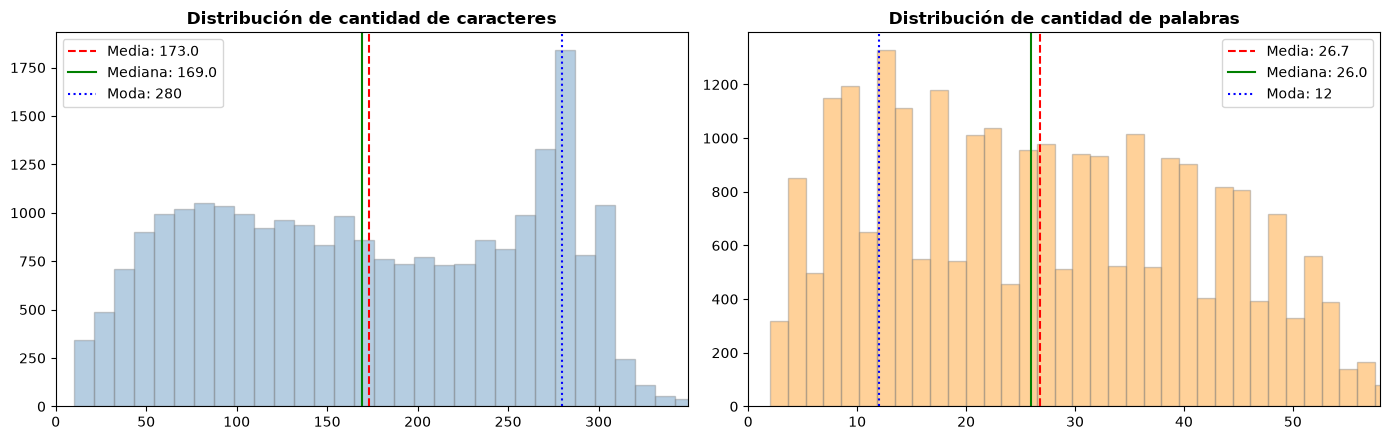

Cantidad de caracteres: rango 10-929 | RIC 95-257 | asimetría 0.08
Cantidad de palabras: rango 2-100 | RIC 14-38 | asimetría 0.23


In [8]:
df['Cantidad de caracteres'] = df['Text'].str.len()
df['Cantidad de palabras'] = df['Text'].fillna('').str.split().str.len()

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
for eje, col, color in zip(ejes, ['Cantidad de caracteres', 'Cantidad de palabras'], ['steelblue', 'darkorange']):
    s = df[col]
    eje.hist(s, bins='auto', alpha=0.4, color=color, edgecolor='gray')
    eje.axvline(s.mean(), color='red', linestyle='--', label=f'Media: {s.mean():.1f}')
    eje.axvline(s.median(), color='green', linestyle='-', label=f'Mediana: {s.median():.1f}')
    eje.axvline(s.mode()[0], color='blue', linestyle=':', label=f'Moda: {s.mode()[0]:.0f}')
    eje.set_xlim(0, s.quantile(0.995)); eje.set_title(f'Distribución de {col.lower()}', fontweight='bold'); eje.legend()
plt.tight_layout(); plt.show()

for col in ['Cantidad de caracteres', 'Cantidad de palabras']:
    s = df[col]
    print(f'{col}: rango {s.min()}-{s.max()} | RIC {s.quantile(.25):.0f}-{s.quantile(.75):.0f} | asimetría {s.skew():.2f}')

**Lectura.** La mayoría de los tweets tiene entre 95 y 257 caracteres y entre 14 y 38 palabras. La moda de caracteres está cerca de 280, el límite de Twitter. Son textos **cortos**, lo que importa para elegir la longitud máxima de las redes y de BERT.

### 2.4.3 Usuarios, canal y periodo

Usuarios distintos: 14,773 para 24,970 tweets
El top 10 de usuarios aporta el 5.0% de los tweets; los 60 usuarios con 20 o más tweets, el 10.8%


,tweets
Username,
johnphillips34,334
jkline120,174
JordanJamesEtem,117
mrlarryridley,111
AiThority,104


Ejemplo del usuario más activo (johnphillips34):


647    #facebookdown @TheRock @steveaustinBSR  @WWEUniverse  @JohnCena #psndown @Microsoft @playstation @starwars @Dell @Co...
675    #facebookdown @TheRock @steveaustinBSR  @WWEUniverse  @JohnCena #psndown @Microsoft @playstation @starwars @Dell @Co...
677    #facebookdown @TheRock @steveaustinBSR  @WWEUniverse  @JohnCena #psndown @Microsoft @playstation @starwars @Dell @Co...
Name: Text, dtype: str


Canal: todos los registros provienen de Twitter (una sola fuente). No hay columna de canal.


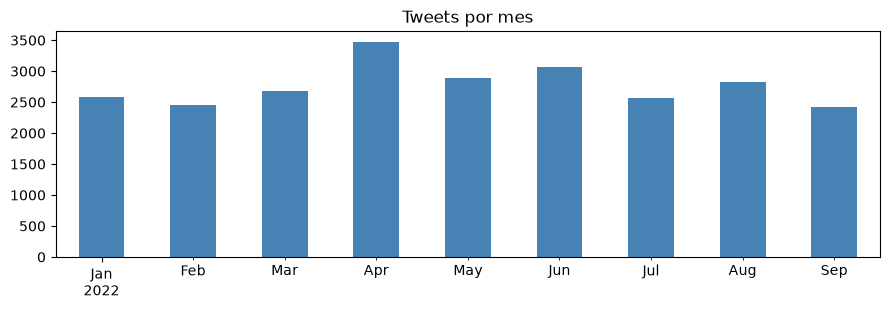

In [9]:
por_usuario = df['Username'].value_counts()
print(f'Usuarios distintos: {por_usuario.size:,} para {len(df):,} tweets')
print(f'El top 10 de usuarios aporta el {por_usuario.head(10).sum() / len(df):.1%} de los tweets; '
      f'los {(por_usuario >= 20).sum()} usuarios con 20 o más tweets, el {por_usuario[por_usuario >= 20].sum() / len(df):.1%}')
display(por_usuario.head(5).rename('tweets').to_frame())
if 'johnphillips34' in por_usuario.index:
    print('Ejemplo del usuario más activo (johnphillips34):')
    display(df.loc[df['Username'] == 'johnphillips34', 'Text'].head(3))

print('\nCanal: todos los registros provienen de Twitter (una sola fuente). No hay columna de canal.')
por_mes = fechas.loc[df.index].dt.to_period('M').value_counts().sort_index()
ax = por_mes.plot(kind='bar', figsize=(9, 3.2), color='steelblue', title='Tweets por mes')
ax.set_xlabel(''); plt.tight_layout(); plt.show()

**Lectura.**
- **Usuarios:** la concentración es baja; ningún usuario domina la base. El más activo (`johnphillips34`) es una persona que menciona a muchas marcas a la vez (`@TheRock @WWEUniverse @Dell...`), no un bot, así que **no se excluye a nadie**.
- **Canal:** solo hay Twitter. El modelo **no se puede aplicar sin validar** a correos, chats o llamadas, donde el lenguaje es distinto (ver data card).
- **Periodo:** los tweets se reparten en nueve meses; esta serie servirá para el análisis de drift (sección 12).

### 2.4.4 Codificación, HTML, retuits y datos personales (PII)

In [10]:
aud_texto = pd.DataFrame({
    'Revisión': ['Mojibake (letras dañadas, p. ej. Ã©)', 'Entidades HTML (&amp; &lt; &gt; &quot;)', 'Retuits (empiezan con RT)',
                 'Menciones a usuarios (@usuario)', 'Enlaces (URL)', 'Hashtags', 'Posibles correos electrónicos',
                 'Posibles teléfonos (secuencias largas de dígitos)'],
    'Tweets': [df['Text'].str.contains(r'Ã.|â€', na=False).sum(),
               df['Text'].str.contains(r'&amp;|&lt;|&gt;|&quot;', na=False).sum(),
               df['Text'].str.match(r'^RT\b', na=False).sum(),
               df['Text'].str.contains(r'@\w+', na=False).sum(),
               df['Text'].str.contains(r'https?://|www\.', na=False).sum(),
               df['Text'].str.contains(r'#\w+', na=False).sum(),
               df['Text'].str.contains(r'[\w.+-]+@[\w-]+\.[a-z]{2,}', na=False, flags=re.I).sum(),
               df['Text'].str.contains(r'\+?\d[\d\s().-]{8,}\d', na=False).sum()],
})
aud_texto['% de la base'] = (aud_texto['Tweets'] / len(df) * 100).round(2)
display(aud_texto.set_index('Revisión'))

,Tweets,% de la base
Revisión,,
"Mojibake (letras dañadas, p. ej. Ã©)",0,0.00
Entidades HTML (&amp; &lt; &gt; &quot;),1397,5.59
Retuits (empiezan con RT),33,0.13
Menciones a usuarios (@usuario),24970,100.00
Enlaces (URL),7973,31.93
Hashtags,6236,24.97
Posibles correos electrónicos,33,0.13
Posibles teléfonos (secuencias largas de dígitos),214,0.86


**Lectura y decisión (se aplica en la sección 3).**
- **HTML:** hay más de mil tweets con entidades como `&amp;`. Si se limpia sin decodificarlas, `&amp;` se convierte en la palabra **`amp`**, que no significa nada y se cuela en el vocabulario. **Se decodifican primero** con `html.unescape`.
- **PII (datos personales):** casi todos los tweets mencionan a usuarios y la columna `Username` identifica personas. Hay pocos correos y teléfonos. Siguiendo el principio de **minimización**, las menciones se eliminan (texto limpio) o se reemplazan por el marcador `@user` (texto para BERT), y `Username` nunca entra al modelo.
- **Retuits:** son pocos y se tratan como casi-duplicados al agrupar la partición.

### 2.4.5 Resumen de la auditoría

| Revisión | Hallazgo | Decisión (sección 3) |
|---|---|---|
| Nulos y vacíos | No hay nulos ni textos vacíos; 1 tweet es solo menciones/hashtags/enlaces | Revisar si queda vacío tras limpiar |
| Duplicados | Cientos de textos repetidos por el mismo usuario | Quitar duplicados de texto + usuario, antes y después de normalizar |
| Longitud | Textos cortos (mediana de unas 21 palabras) | No es necesario truncar en las redes; BERT usa una longitud basada en percentiles |
| Usuarios | Concentración baja | No se excluye a nadie |
| Canal | Solo Twitter | Se documenta como limitación |
| HTML | Más de mil tweets con entidades HTML | Decodificar **antes** de limpiar |
| PII | Menciones y usuarios en casi todos los tweets | Eliminar o enmascarar menciones; `Username` fuera del modelo |
| Etiquetas | Etiquetas plata con desbalance fuerte | Métrica centrada en anger y disgust; `class_weight` evaluado con validación |

# 3. Limpieza y preparación del texto

Esta sección reúne **toda** la limpieza en un solo flujo. El orden no es arbitrario: cada paso prepara el siguiente.

| Paso | Qué se hace | Por qué en este orden |
|---|---|---|
| 1 | Quitar duplicados de **texto original + usuario** | Primero se eliminan las copias exactas, para no limpiar dos veces lo mismo |
| 2 | **Decodificar HTML** (`&amp;` → `&`) | Debe ir antes de cualquier limpieza; si no, `&amp;` se vuelve la palabra `amp` |
| 3 | Crear el **texto para BERT** (limpieza mínima) | BERT trae su propio tokenizador y aprovecha mayúsculas, puntuación y contexto; por eso solo se enmascaran menciones y enlaces |
| 4 | Crear el **texto limpio** (normalización completa) | Para TF-IDF y redes: minúsculas, sin menciones, enlaces ni puntuación, espacios estandarizados |
| 5 | Quitar duplicados de **texto limpio + usuario** | La normalización vuelve idénticos tweets que antes solo diferían en una mención, un enlace o una mayúscula |
| 6 | Crear el **texto base** (sin números) | Detecta casi-duplicados (plantillas que solo cambian una cifra); se usará para agrupar la partición |
| 7 | **Lematizar** el texto limpio | Lleva cada palabra a su forma de diccionario (`broken` → `break`) para uno de los baselines |
| 8 | **Verificar** el resultado | Vacíos, textos muy cortos, extremos, vocabulario y residuos (`amp`, `rt`, `https`) |

En cada paso se anota cuántas filas había antes y después (bitácora al final).

In [11]:
bitacora = []
def anotar(paso, antes, despues, decision):
    bitacora.append({'Paso': paso, 'Filas antes': antes, 'Filas después': despues, 'Cambio': despues - antes, 'Decisión': decision})

## Paso 1. Duplicados de texto original + usuario

In [12]:
antes = len(df)
df_clean = df.drop_duplicates(subset=['Text', 'Username'], keep='first').copy()
anotar('1. Duplicados (texto original + usuario)', antes, len(df_clean), 'Se conserva la primera aparición')
print(f'Filas: {antes} -> {len(df_clean)} ({len(df_clean) - antes})')

Filas: 24970 -> 24702 (-268)


## Paso 2. Decodificar entidades HTML

In [13]:
df_clean['Text decodificado'] = df_clean['Text'].map(html.unescape)
cambiados = (df_clean['Text decodificado'] != df_clean['Text']).sum()
anotar('2. Decodificar HTML', len(df_clean), len(df_clean), f'{cambiados} tweets corregidos (&amp; -> &)')
print(f'Tweets con alguna entidad HTML decodificada: {cambiados}')
ej = df_clean.loc[df_clean['Text decodificado'] != df_clean['Text']].iloc[0]
print('Antes  :', ej['Text'][:160]); print('Después:', ej['Text decodificado'][:160])

Tweets con alguna entidad HTML decodificada: 1382
Antes  : What's your biggest data management challenge?     • Cloud complexity?   • Lengthy tech refresh cycles?   • Capital budget constraints?      Solve your challeng
Después: What's your biggest data management challenge?     • Cloud complexity?   • Lengthy tech refresh cycles?   • Capital budget constraints?      Solve your challeng


## Paso 3. Texto para BERT (limpieza mínima)

BERT no necesita (ni le conviene) la limpieza fuerte que usan TF-IDF y las redes:
- Su tokenizador **divide en subpalabras** las palabras raras o mal escritas, así que no hace falta normalizarlas.
- La **puntuación** (`!!!`, `?`) y el **contexto completo** llevan señal emocional que un Transformer sí puede usar.
- `bert-base-uncased` pasa todo a minúsculas internamente.

Por eso solo se hace lo necesario por **privacidad y ruido**: los correos se reemplazan por `[email]`, las menciones por `@user` (el modelo sabe que hubo una mención, pero no a quién) y los enlaces por `http`. También se estandarizan los espacios. Los correos van primero porque contienen una `@` que, si no, se confundiría con una mención.

In [14]:
def texto_para_bert(texto):
    texto = re.sub(r'[\w.+-]+@[\w-]+\.[A-Za-z]{2,}\S*', '[email]', texto)   # correos -> marcador (antes que las menciones)
    texto = re.sub(r'@[A-Za-z0-9_]+', '@user', texto)            # menciones -> marcador (minimización de PII)
    texto = re.sub(r'https?://\S+|www\.\S+', 'http', texto)        # enlaces -> marcador
    return re.sub(r'\s+', ' ', texto).strip()

df_clean['Texto BERT'] = df_clean['Text decodificado'].map(texto_para_bert)
anotar('3. Texto para BERT', len(df_clean), len(df_clean), 'Menciones -> @user, enlaces -> http')
display(df_clean[['Text', 'Texto BERT']].head(3))

,Text,Texto BERT
0,@Logitech @apple @Google @Microsoft @Dell @Lenovo #WhatIf QWERTY were modified for programmers so things like bracke...,"@user @user @user @user @user @user #WhatIf QWERTY were modified for programmers so things like brackets, parens, qu..."
1,@MK_habit_addict @official_stier @MortalKombat @newzealand She's getting a new @Dell #laptop when the one she has on...,@user @user @user @user She's getting a new @user #laptop when the one she has one only 2-3 years old. (More than tr...
2,"As @CRN celebrates its 40th anniversary, Bob Faletra and @stevenjburke spoke with me about the milestones, companies...","As @user celebrates its 40th anniversary, Bob Faletra and @user spoke with me about the milestones, companies and pe..."


## Paso 4. Texto limpio (normalización completa para TF-IDF y redes)

- **Minúsculas:** `Dell` y `dell` deben ser la misma palabra.
- **Sin menciones (`@usuario`) ni enlaces:** son ruido para contar palabras y además son datos personales.
- **Sin puntuación ni caracteres especiales:** TF-IDF y el vocabulario de las redes trabajan con palabras.
- **Espacios estandarizados:** sin tabulaciones ni saltos de línea repetidos.

In [15]:
def limpiar_texto(texto):
    if not isinstance(texto, str):
        return ''
    texto = texto.lower()                                          # minúsculas
    texto = re.sub(r'@[A-Za-z0-9_]+', '', texto)                   # menciones
    texto = re.sub(r'https?://\S+|www\.\S+', '', texto)            # enlaces
    texto = re.sub(r'[^\w\s]', '', texto)                          # puntuación y símbolos
    return re.sub(r'\s+', ' ', texto).strip()                      # espacios

df_clean['Texto limpio'] = df_clean['Text decodificado'].map(limpiar_texto)
anotar('4. Texto limpio', len(df_clean), len(df_clean), 'Minúsculas, sin menciones, enlaces ni puntuación')
display(df_clean[['Text', 'Texto limpio']].head(3))

,Text,Texto limpio
0,@Logitech @apple @Google @Microsoft @Dell @Lenovo #WhatIf QWERTY were modified for programmers so things like bracke...,whatif qwerty were modified for programmers so things like brackets parens quotes operators etc moved to the middle ...
1,@MK_habit_addict @official_stier @MortalKombat @newzealand She's getting a new @Dell #laptop when the one she has on...,shes getting a new laptop when the one she has one only 23 years old more than triple the price though much higher u...
2,"As @CRN celebrates its 40th anniversary, Bob Faletra and @stevenjburke spoke with me about the milestones, companies...",as celebrates its 40th anniversary bob faletra and spoke with me about the milestones companies and personalities th...


## Paso 5. Duplicados después de normalizar (texto limpio + usuario)

In [16]:
mask = df_clean.duplicated(subset=['Texto limpio', 'Username'], keep=False)
print('Ejemplos que solo se vuelven idénticos al normalizar:')
display(df_clean[mask].sort_values(['Username', 'Texto limpio'])[['Username', 'Text']].head(6))
antes = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=['Texto limpio', 'Username'], keep='first').copy()
anotar('5. Duplicados (texto limpio + usuario)', antes, len(df_clean), 'Se conserva la primera aparición')
print(f'Filas: {antes} -> {len(df_clean)} ({len(df_clean) - antes})')

Ejemplos que solo se vuelven idénticos al normalizar:


,Username,Text
12526,451Alliance,"What does Krish Iyer, strategy lead for autonomous vehicles and smart manufacturing in the office of the CTO at @Del..."
12780,451Alliance,"What does Krish Iyer, strategy lead for autonomous vehicles and smart manufacturing in the office of the CTO at @Del..."
14018,451Alliance,"What does Krish Iyer, strategy lead for autonomous vehicles and smart manufacturing in the office of the CTO at @Del..."
15878,451Alliance,"What does Krish Iyer, strategy lead for autonomous vehicles and smart manufacturing in the office of the CTO at @Del..."
7659,A10Networks,"A10's Brian Tolloty, VP of North America sales, met with Dan Rumley, OEM Americas business development at @Dell, to ..."
7897,A10Networks,"A10's Brian Tolloty, VP of North America sales, met with Dan Rumley, OEM Americas business development at @Dell, to ..."


Filas: 24702 -> 24119 (-583)


**Lectura.** Muchos duplicados no se veían en el texto original porque diferían en una mención, un enlace acortado distinto o una mayúscula (por ejemplo, los cupones de `CouponKozSG`). Se quitan para que no haya fuga de información.

## Paso 6. Texto base y casi-duplicados

El **texto base** es el texto limpio **sin números**. Dos tweets con el mismo texto base son prácticamente el mismo mensaje (plantillas que solo cambian una cifra). No entra a ningún modelo: sirve para **agrupar la partición** (sección 4), de modo que un casi-duplicado nunca quede en entrenamiento y en prueba a la vez. También permite ver textos repetidos con **etiquetas distintas**, señal de ruido en las etiquetas.

In [17]:
df_clean['Texto base'] = (df_clean['Texto limpio'].str.replace(r'\d+', '', regex=True)
                          .str.replace(r'\s+', ' ', regex=True).str.strip())
print(f"Textos limpios repetidos (usuarios distintos): {df_clean['Texto limpio'].duplicated().sum()}")
print(f"Casi-duplicados (mismo texto base):            {df_clean['Texto base'].duplicated().sum()}")

n_emociones = df_clean.groupby('Texto base')['emotion'].nunique()
repetidos = df_clean['Texto base'].value_counts()
repetidos = repetidos[repetidos > 1].index
contradictorios = n_emociones.loc[repetidos][n_emociones.loc[repetidos] > 1].index
print(f'Textos base repetidos: {len(repetidos)} | con más de una emoción distinta: {len(contradictorios)}')
display(df_clean[df_clean['Texto base'].isin(contradictorios[:4])].sort_values('Texto base')[['Texto base', 'emotion']].head(10))
anotar('6. Texto base', len(df_clean), len(df_clean), f'{len(contradictorios)} textos repetidos con etiquetas contradictorias')

Textos limpios repetidos (usuarios distintos): 964
Casi-duplicados (mismo texto base):            1029
Textos base repetidos: 370 | con más de una emoción distinta: 65


,Texto base,emotion
1171,agreed,joy
20816,agreed,anticipation
11346,agreed,anticipation
19005,agreed,joy
18877,agreed,anticipation
23054,agreed,joy
16924,agreed,anticipation
15613,agreed,anticipation
288,dude,anticipation
19558,dude,disgust


**Lectura.** Hay textos idénticos (`agreed`, `dude`) que el etiquetador marcó con emociones distintas. Ningún modelo puede acertar en todos esos casos: es un **techo** para el desempeño y una evidencia de que las etiquetas plata tienen ruido.

## Paso 7. Lematización

La lematización lleva cada palabra a su forma de diccionario (`broken` → `break`, `laptops` → `laptop`) y junta formas distintas de la misma palabra. Se usa el lematizador de spaCy en inglés en modo *lookup* (consulta una tabla, con `spacy-lookups-data`), porque el modelo `en_core_web_sm` no se pudo descargar en esta máquina. Es menos fino (no mira el contexto), pero **no aprende de los datos**, así que no genera fuga y se puede aplicar a todos los tweets de una vez.

In [18]:
import spacy
nlp_lemas = spacy.blank('en')
nlp_lemas.add_pipe('lemmatizer', config={'mode': 'lookup'})
nlp_lemas.initialize()

def lematizar_uno(texto):
    return ' '.join(tok.lemma_.lower() for tok in nlp_lemas(texto) if not tok.is_space)

df_clean['Texto lematizado'] = [' '.join(tok.lemma_.lower() for tok in doc if not tok.is_space)
                                for doc in nlp_lemas.pipe(df_clean['Texto limpio'], batch_size=1000)]
anotar('7. Lematización', len(df_clean), len(df_clean), 'spaCy en modo lookup')
display(df_clean[['Texto limpio', 'Texto lematizado']].head(4))

,Texto limpio,Texto lematizado
0,whatif qwerty were modified for programmers so things like brackets parens quotes operators etc moved to the middle ...,whatif qwerty be modify for programmer so thing like bracket parens quote operator etc move to the middle near gh sp...
1,shes getting a new laptop when the one she has one only 23 years old more than triple the price though much higher u...,she s get a new laptop when the one she have one only 23 year old much than triple the price though much high utility
2,as celebrates its 40th anniversary bob faletra and spoke with me about the milestones companies and personalities th...,a celebrate its 40th anniversary bob faletra and speak with me about the milestone company and personality that help...
3,your customer service is horrible especially agent syedfaisal who has made this experience of purchasing a new compu...,your customer service be horrible especially agent syedfaisal who have make this experience of purchase a new comput...


## Paso 8. Verificación final

In [19]:
vacios = df_clean['Texto limpio'].str.len() == 0
n_pal = df_clean['Texto limpio'].str.split().str.len()
muy_cortos = n_pal <= 2
print(f'Vacíos tras limpieza: {vacios.sum()} | Con 2 palabras o menos: {muy_cortos.sum()} ({muy_cortos.mean():.1%})')
print('Emociones de los textos muy cortos frente al total (proporción):')
display(pd.DataFrame({'muy cortos': df_clean.loc[muy_cortos, 'emotion'].value_counts(normalize=True),
                      'total': df_clean['emotion'].value_counts(normalize=True)}).round(3))
print('Más largos :'); print(df_clean.loc[n_pal.nlargest(3).index, 'Texto limpio'].str[:150].to_string())
print('Más cortos :'); print(df_clean.loc[n_pal.nsmallest(4).index, 'Texto limpio'].to_string())

palabras = Counter(' '.join(df_clean['Texto limpio']).split())
lemas = Counter(' '.join(df_clean['Texto lematizado']).split())
print(f'\nVocabulario: {len(palabras):,} palabras únicas ({len(lemas):,} lemas) | '
      f'aparecen una sola vez: {sum(c == 1 for c in palabras.values()) / len(palabras):.0%}')
print('Residuos:', {w: palabras.get(w, 0) for w in ['amp', 'rt', 'https', 'co']})
print('20 palabras más frecuentes:', palabras.most_common(20))

df_m = df_clean[~vacios].copy()
anotar('8. Verificación (quitar vacíos)', len(df_clean), len(df_m), 'Base final para modelar')

Vacíos tras limpieza: 0 | Con 2 palabras o menos: 1130 (4.7%)
Emociones de los textos muy cortos frente al total (proporción):


,muy cortos,total
emotion,,
anger,0.070,0.306
anticipation,0.246,0.204
disgust,0.150,0.123
fear,0.012,0.015
joy,0.441,0.250
optimism,0.005,0.047
sadness,0.075,0.054
surprise,0.002,0.001


Más largos :
5304     uh huh uh huh uh huh uh huh uh huh uh huh uh huh uh huh uh huh uh huh uh huh uh huh uh huh uh huh uh huh uh huh uh h...
20355    did you get it yet did you get it yet im like no not yet haha then he was like well ive sent it two times now im lik...
12915    wn a drivr losses hisher life bcz of technical fault in d car d car company does nt only solves d car issue bt also ...
Más cortos :
8            beautiful
107    congratulations
288               dude
343         overpriced



Vocabulario: 29,499 palabras únicas (24,702 lemas) | aparecen una sola vez: 56%
Residuos: {'amp': 1, 'rt': 68, 'https': 2, 'co': 13}
20 palabras más frecuentes: [('the', 17042), ('to', 15029), ('and', 12065), ('a', 11917), ('i', 10714), ('is', 7822), ('for', 7199), ('of', 7049), ('you', 6475), ('it', 6140), ('in', 5959), ('my', 5665), ('with', 5290), ('dell', 5275), ('on', 5177), ('this', 4755), ('laptop', 4132), ('that', 4080), ('have', 3686), ('not', 3611)]


**Decisiones de la verificación.**
- **Textos muy cortos** (`thanks`, `overpriced`): se **conservan**, porque sí expresan una emoción. Tienen más `joy` que el promedio.
- **Extremos de longitud:** los más largos son repeticiones (`uh huh uh huh…`), no errores de carga. Se mantienen.
- **Vocabulario:** más de la mitad de las palabras aparecen una sola vez; por eso las redes limitan su vocabulario a las 20.000 más frecuentes. La palabra `amp` prácticamente desapareció gracias al paso 2. Quedan residuos menores (`rt`, `co`) que no justifican otra regla.

### Un tweet a través de todo el flujo

In [20]:
cand = df_m[df_m['Text'].str.contains('my @HP has been doing this', case=False, na=False)]
ej = cand.iloc[0] if len(cand) else df_m[df_m['Text'].str.contains('@', na=False) & df_m['Text'].str.contains(r'\d', na=False)].iloc[0]
display(pd.DataFrame({'Versión': ['Original', 'Texto BERT', 'Texto limpio', 'Texto lematizado', 'Texto base'],
                      'Uso': ['—', 'BERT', 'TF-IDF palabras/caracteres y redes', 'TF-IDF de lemas', 'Solo para agrupar la partición'],
                      'Texto': [ej['Text'], ej['Texto BERT'], ej['Texto limpio'], ej['Texto lematizado'], ej['Texto base']]}).set_index('Versión'))
print('Emoción:', ej['emotion'])

,Uso,Texto
Versión,,
Original,—,My @HP has been doing this for 3 days so now I own a @Dell. https://t.co/ulHJu4rDEx
Texto BERT,BERT,My @user has been doing this for 3 days so now I own a @user. http
Texto limpio,TF-IDF palabras/caracteres y redes,my has been doing this for 3 days so now i own a
Texto lematizado,TF-IDF de lemas,my have be do this for 3 day so now i own a
Texto base,Solo para agrupar la partición,my has been doing this for days so now i own a


Emoción: disgust


### Bitácora de la limpieza

,Filas antes,Filas después,Cambio,Decisión
Paso,,,,
1. Duplicados (texto original + usuario),24970,24702,-268,Se conserva la primera aparición
2. Decodificar HTML,24702,24702,0,1382 tweets corregidos (&amp; -> &)
3. Texto para BERT,24702,24702,0,"Menciones -> @user, enlaces -> http"
4. Texto limpio,24702,24702,0,"Minúsculas, sin menciones, enlaces ni puntuación"
5. Duplicados (texto limpio + usuario),24702,24119,-583,Se conserva la primera aparición
6. Texto base,24119,24119,0,65 textos repetidos con etiquetas contradictorias
7. Lematización,24119,24119,0,spaCy en modo lookup
8. Verificación (quitar vacíos),24119,24119,0,Base final para modelar


De 24970 tweets originales quedan 24119 para modelar (96.6%).


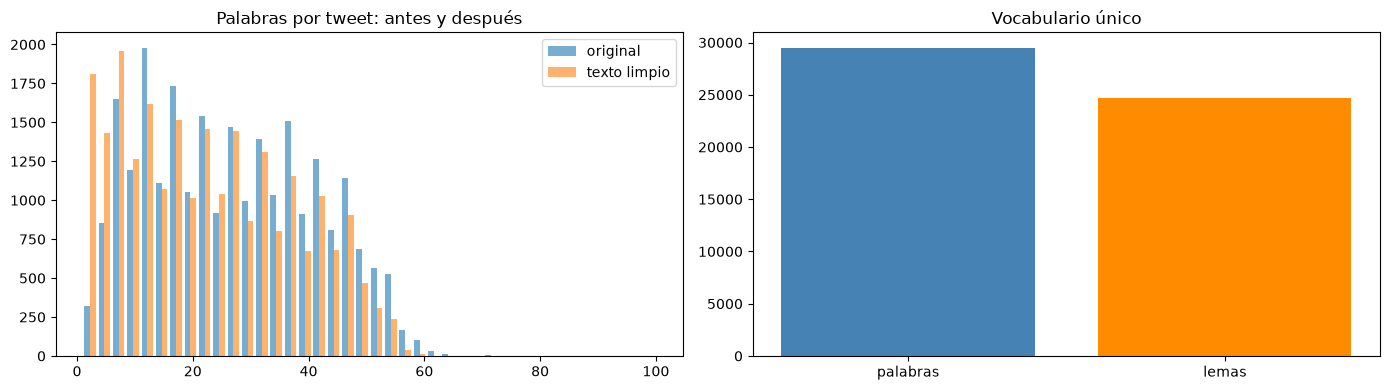

In [21]:
display(pd.DataFrame(bitacora).set_index('Paso'))
print(f'De {len(df)} tweets originales quedan {len(df_m)} para modelar ({len(df_m) / len(df):.1%}).')

df_m['Cantidad de palabras limpio'] = df_m['Texto limpio'].str.split().str.len()
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
ejes[0].hist([df['Cantidad de palabras'], df_m['Cantidad de palabras limpio']], bins=40, label=['original', 'texto limpio'], alpha=0.6)
ejes[0].set_title('Palabras por tweet: antes y después'); ejes[0].legend()
ejes[1].bar(['palabras', 'lemas'], [len(palabras), len(lemas)], color=['steelblue', 'darkorange'])
ejes[1].set_title('Vocabulario único'); plt.tight_layout(); plt.show()

# 4. Partición sin fuga: entrenamiento, validación y prueba

- **Entrenamiento (80 %)**: lo que los modelos usan para aprender.
- **Validación (5 pliegues dentro del entrenamiento)**: para comparar modelos y elegir hiperparámetros. En cada pliegue, 4/5 se usan para aprender y 1/5 para validar.
- **Prueba (20 %)**: sellada; se abre **una sola vez, al final** (sección 8).

**Por qué agrupar.** Aun sin duplicados del mismo usuario, hay textos idénticos escritos por usuarios distintos (`thanks`, `happy friday`). Si un mismo texto cae en entrenamiento y en prueba, el modelo no predice: recuerda, y la nota sale inflada. `StratifiedGroupKFold` mantiene juntos todos los tweets con el mismo **texto base** y conserva la proporción de cada emoción.

**¿Por qué no otra partición?**

| Alternativa | Cuándo conviene | Por qué no es la principal aquí |
|---|---|---|
| Aleatoria simple | Textos independientes | Dejaría casi-duplicados a ambos lados (fuga) |
| **Agrupada por texto base** (elegida) | Hay textos repetidos y plantillas | Evita la fuga más grave y conserva la estratificación |
| Temporal (entrenar con meses antiguos y probar con los recientes) | Para medir el efecto del paso del tiempo | Solo hay 9 meses y la distribución de emociones es estable; se usa como chequeo de drift (sección 12) |
| Por usuario | Si el modelo pudiera memorizar el estilo de un autor | La concentración por usuario es baja; se mide abajo cuánto se cruzan los autores |

In [22]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder

N_PLIEGUES = 5
df_m = df_m.reset_index(drop=False).rename(columns={'index': 'fila_original'})

sgkf_prueba = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_tr, idx_te = next(sgkf_prueba.split(df_m, df_m['emotion'], groups=df_m['Texto base']))
df_tr, df_te = df_m.iloc[idx_tr], df_m.iloc[idx_te]

sgkf_val = StratifiedGroupKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=SEMILLA)
folds = list(sgkf_val.split(df_tr, df_tr['emotion'], groups=df_tr['Texto base']))

le = LabelEncoder().fit(sorted(df_m['emotion'].unique()))
CLASES = list(le.classes_)

comunes = set(df_tr['Texto limpio']) & set(df_te['Texto limpio'])
comunes_base = set(df_tr['Texto base']) & set(df_te['Texto base'])
print(f'Entrenamiento: {len(df_tr)} | Prueba: {len(df_te)} | Textos en común: {len(comunes)} | Textos base en común: {len(comunes_base)}')
assert len(comunes) == 0 and len(comunes_base) == 0
filas = []
for k, (a, v) in enumerate(folds, start=1):
    ck = set(df_tr['Texto base'].iloc[a]) & set(df_tr['Texto base'].iloc[v])
    assert len(ck) == 0
    filas.append({'pliegue': k, 'entrena': len(a), 'valida': len(v), 'textos base en común': len(ck)})
display(pd.DataFrame(filas).set_index('pliegue'))

prop = pd.DataFrame({'total': df_m['emotion'].value_counts(normalize=True),
                     'entrenamiento': df_tr['emotion'].value_counts(normalize=True),
                     'prueba': df_te['emotion'].value_counts(normalize=True)})
for k, (a, v) in enumerate(folds, start=1):
    prop[f'val {k}'] = df_tr['emotion'].iloc[v].value_counts(normalize=True)
display(prop.round(3))

aut_comunes = set(df_tr['Username']) & set(df_te['Username'])
print(f"Autores de prueba que también aparecen en entrenamiento: {len(aut_comunes)} de {df_te['Username'].nunique()} "
      f"({df_te['Username'].isin(aut_comunes).mean():.1%} de los tweets de prueba)")

Entrenamiento: 19295 | Prueba: 4824 | Textos en común: 0 | Textos base en común: 0


,entrena,valida,textos base en común
pliegue,,,
1,15436,3859,0
2,15436,3859,0
3,15435,3860,0
4,15437,3858,0
5,15436,3859,0


,total,entrenamiento,prueba,val 1,val 2,val 3,val 4,val 5
emotion,,,,,,,,
anger,0.306,0.306,0.306,0.306,0.306,0.306,0.306,0.306
joy,0.250,0.250,0.250,0.250,0.250,0.249,0.250,0.250
anticipation,0.204,0.204,0.204,0.204,0.204,0.204,0.204,0.204
disgust,0.123,0.123,0.123,0.123,0.123,0.123,0.123,0.123
sadness,0.054,0.054,0.054,0.054,0.054,0.054,0.054,0.054
optimism,0.047,0.047,0.047,0.047,0.047,0.047,0.047,0.047
fear,0.015,0.015,0.015,0.015,0.015,0.015,0.015,0.015
surprise,0.001,0.001,0.001,0.002,0.002,0.002,0.001,0.001


Autores de prueba que también aparecen en entrenamiento: 1535 de 3884 (49.6% de los tweets de prueba)


**Lectura.**
- **No hay fuga de textos:** ningún texto, ni siquiera como casi-duplicado, aparece en dos conjuntos. Los `assert` lo garantizan.
- **La estratificación funcionó:** cada emoción conserva casi la misma proporción en todos los conjuntos, así que las métricas de los pliegues son comparables.
- **Autores compartidos:** una parte de los tweets de prueba es de autores que también están en entrenamiento (sobre todo usuarios frecuentes). Como el modelo no recibe el usuario y los textos no se repiten, el riesgo de que memorice a un autor es bajo; se deja documentado como limitación.
- **Cuidado con `surprise`:** muy pocos tweets en prueba; su F1 no permite conclusiones.

## 4.1 Data card

In [23]:
data_card = pd.DataFrame({
    'Campo': ['Nombre', 'Población', 'Cobertura temporal', 'Idioma', 'Canal', 'Tamaño', 'Partición', 'Etiquetas', 'Distribución de clases',
              'Limitaciones', 'Usos previstos', 'Usos NO previstos', 'Datos personales', 'Licencia'],
    'Descripción': [
        'Dell tweets con emociones (Kaggle, versión 1)',
        'Usuarios de Twitter que mencionaron públicamente a @Dell; no representa a todos los clientes de Dell',
        f'{fechas.min():%Y-%m-%d} a {fechas.max():%Y-%m-%d}',
        'Inglés (mayoritariamente); textos en otros idiomas no fueron filtrados',
        'Solo Twitter',
        f'{len(df):,} tweets originales; {len(df_m):,} tras la limpieza',
        f'Entrenamiento {len(df_tr):,} / prueba {len(df_te):,}, agrupada por texto base y estratificada por emoción (semilla {SEMILLA})',
        '8 emociones asignadas por un modelo de Transformers (etiquetas plata), no por personas',
        ', '.join(f'{e} {p:.1%}' for e, p in df_m['emotion'].value_counts(normalize=True).items()),
        'Etiquetas ruidosas; clases minoritarias (fear, surprise) con muy pocos ejemplos; sin datos demográficos; un solo canal; 2022 (lenguaje y productos cambian)',
        'Priorizar la atención de tweets con ira o disgusto, con revisión humana de los casos dudosos',
        'Decidir sobre clientes individuales (crédito, garantías, sanciones); evaluar empleados; otros idiomas o canales sin validar; inferir rasgos personales',
        'Usuarios y menciones en el texto: se eliminan o enmascaran; Username solo se usa para quitar duplicados',
        'CDLA-Permissive-1.0 (compilación); los tweets están sujetos a los términos de X/Twitter'],
})
display(data_card.set_index('Campo'))

,Descripción
Campo,
Nombre,"Dell tweets con emociones (Kaggle, versión 1)"
Población,Usuarios de Twitter que mencionaron públicamente a @Dell; no representa a todos los clientes de Dell
Cobertura temporal,2022-01-01 a 2022-09-30
Idioma,Inglés (mayoritariamente); textos en otros idiomas no fueron filtrados
Canal,Solo Twitter
Tamaño,"24,970 tweets originales; 24,119 tras la limpieza"
Partición,"Entrenamiento 19,295 / prueba 4,824, agrupada por texto base y estratificada por emoción (semilla 42)"
Etiquetas,"8 emociones asignadas por un modelo de Transformers (etiquetas plata), no por personas"
Distribución de clases,"anger 30.6%, joy 25.0%, anticipation 20.4%, disgust 12.3%, sadness 5.4%, optimism 4.7%, fear 1.5%, surprise 0.1%"


# 5. Modelo base: TF-IDF + regresión logística (baseline)

**Qué es un baseline.** Es el modelo sencillo contra el que se comparan los demás. Si una red o un Transformer, más lentos y difíciles de explicar, no le ganan con claridad, no vale la pena usarlos.

**Tres formas de convertir el texto en números (todas con TF-IDF):**

| Representación | Qué mide | Para qué sirve |
|---|---|---|
| Palabras (1 y 2 palabras seguidas) | Qué palabras y pares de palabras aparecen y qué tan especiales son | Capta frases como `not working` o `customer service` |
| Caracteres (pedazos de 3 a 5 letras) | Qué fragmentos de palabras aparecen | Tolera errores de ortografía y alargamientos (`soooo bad`) |
| Lemas (1 y 2 palabras seguidas) | La forma de diccionario de cada palabra | Junta formas distintas de la misma palabra |

**Sobre `class_weight='balanced'`.** Hace que equivocarse en una emoción poco frecuente cueste más. No es obvio que ayude a las dos clases clave (`anger` es la más frecuente), así que se **prueba con y sin pesos** y se decide con los pliegues de validación.

**Qué se calcula en cada pliegue.** El vocabulario y los pesos IDF se aprenden solo con los 4/5 de entrenamiento del pliegue y se aplican al 1/5 de validación.

In [24]:
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, recall_score, log_loss, classification_report, ConfusionMatrixDisplay,
                             confusion_matrix, precision_recall_fscore_support)

def calcular_metricas(y_real, y_pred, prob=None):
    """Métricas de una predicción. prob = matriz de probabilidades (columnas en el orden de CLASES)."""
    f1 = f1_score(y_real, y_pred, labels=CLASES_CLAVE, average=None, zero_division=0)
    rc = recall_score(y_real, y_pred, labels=CLASES_CLAVE, average=None, zero_division=0)
    m = {'f1_clave': f1.mean(), 'f1_macro': f1_score(y_real, y_pred, average='macro', zero_division=0),
         'f1_anger': f1[0], 'f1_disgust': f1[1], 'recall_anger': rc[0], 'recall_disgust': rc[1],
         'exactitud': float(np.mean(np.asarray(y_real) == np.asarray(y_pred)))}
    if prob is not None:
        m['log_loss'] = log_loss(y_real, prob, labels=CLASES)
    return m

representaciones = {
    'palabras 1-2':   (TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), 'Texto limpio'),
    'caracteres 3-5': (TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True), 'Texto limpio'),
    'lemas 1-2':      (TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), 'Texto lematizado'),
}
pesos_clase = {'sin pesos': None, 'balanced': 'balanced'}

filas = []
for nombre_rep, (vec0, col) in representaciones.items():
    for k, (a, v) in enumerate(folds, start=1):
        vec = clone(vec0)
        Fa = vec.fit_transform(df_tr[col].iloc[a])
        Fv = vec.transform(df_tr[col].iloc[v])
        for nombre_peso, cw in pesos_clase.items():
            t = time.perf_counter()
            lr = LogisticRegression(max_iter=1000, class_weight=cw).fit(Fa, df_tr['emotion'].iloc[a])
            seg = time.perf_counter() - t
            m = calcular_metricas(df_tr['emotion'].iloc[v], lr.predict(Fv), lr.predict_proba(Fv))
            m.update(representacion=nombre_rep, pesos=nombre_peso, pliegue=k, parametros=lr.coef_.size + lr.intercept_.size, segundos=seg)
            filas.append(m)
    print(f'listo: {nombre_rep}')

res_base = pd.DataFrame(filas)
cols_metricas = ['f1_clave', 'f1_macro', 'f1_anger', 'f1_disgust', 'recall_anger', 'recall_disgust', 'log_loss', 'parametros', 'segundos']
resumen_base = res_base.groupby(['representacion', 'pesos'], sort=False)[cols_metricas].mean()
resumen_base['f1_clave_desv'] = res_base.groupby(['representacion', 'pesos'], sort=False)['f1_clave'].std()
display(resumen_base.sort_values(['f1_clave', 'f1_macro'], ascending=False).round(3))

listo: palabras 1-2


listo: caracteres 3-5


listo: lemas 1-2


,,f1_clave,f1_macro,f1_anger,f1_disgust,recall_anger,recall_disgust,log_loss,parametros,segundos,f1_clave_desv
representacion,pesos,,,,,,,,,,
lemas 1-2,balanced,0.567,0.454,0.757,0.377,0.736,0.400,1.209,323059.2,5.257,0.007
caracteres 3-5,balanced,0.562,0.455,0.759,0.365,0.703,0.392,1.161,436187.2,216.135,0.007
palabras 1-2,balanced,0.559,0.438,0.750,0.368,0.735,0.387,1.239,352259.2,6.795,0.005
caracteres 3-5,sin pesos,0.549,0.405,0.780,0.317,0.867,0.253,1.027,436187.2,14.598,0.020
lemas 1-2,sin pesos,0.507,0.352,0.750,0.263,0.885,0.192,1.080,323059.2,6.557,0.015
palabras 1-2,sin pesos,0.489,0.344,0.742,0.236,0.886,0.165,1.103,352259.2,7.653,0.019


**Qué hacemos ahora.** Elegimos el mejor baseline con la regla del prerregistro (mayor F1 clave promedio en validación; desempate F1 macro) y medimos cuánto cambia cada representación al usar `class_weight='balanced'`. **Por qué:** la decisión de usar pesos se toma con evidencia y se hereda a las redes y a BERT, para que la comparación sea justa.

In [25]:
mejor_rep, mejor_peso = resumen_base.sort_values(['f1_clave', 'f1_macro'], ascending=False).index[0]
USAR_PESOS = (mejor_peso == 'balanced')   # la misma decisión se usa en las redes y en BERT
print(f'Baseline elegido: TF-IDF de {mejor_rep} + regresión logística ({mejor_peso})')
print(f'F1 clave en validación: {resumen_base.loc[(mejor_rep, mejor_peso), "f1_clave"]:.3f}')
efecto = (resumen_base.xs('balanced', level='pesos')[['f1_clave', 'f1_macro', 'f1_anger', 'f1_disgust']]
          - resumen_base.xs('sin pesos', level='pesos')[['f1_clave', 'f1_macro', 'f1_anger', 'f1_disgust']])
print('\nCambio al usar class_weight=balanced (positivo = mejora):')
display(efecto.round(3))

Baseline elegido: TF-IDF de lemas 1-2 + regresión logística (balanced)
F1 clave en validación: 0.567

Cambio al usar class_weight=balanced (positivo = mejora):


,f1_clave,f1_macro,f1_anger,f1_disgust
representacion,,,,
palabras 1-2,0.070,0.094,0.007,0.132
caracteres 3-5,0.013,0.050,-0.021,0.047
lemas 1-2,0.061,0.102,0.007,0.114


**Cómo leer el resultado del baseline**
- **Los tres TF-IDF con pesos quedan prácticamente empatados**: se diferencian en menos de 0,01 de F1 clave, del orden de una desviación entre pliegues. Gana el de mayor F1 clave por la regla fijada de antemano, no por una razón de fondo.
- **`class_weight='balanced'` sí ayuda, sobre todo a `disgust`**: sin pesos, el modelo apuesta casi siempre por `anger` (la clase más grande) y deja pasar `disgust`. Con pesos, el recall de `disgust` sube mucho a cambio de algo de recall en `anger`. Como el F1 clave pesa igual a las dos clases, el balance mejora el resultado. Por eso se mantiene `balanced` también en las redes y en BERT.

### 5.1 Matriz de confusión del baseline (predicciones fuera de pliegue)

Cada tweet de entrenamiento lo predice un modelo entrenado con los otros 4 pliegues, que nunca lo vio. Así se evalúan todos los tweets de entrenamiento **sin tocar la prueba**. Filas = emoción real, columnas = predicha; la versión normalizada por fila muestra el *recall* en la diagonal.

Tweets evaluados: 19295 | Exactitud: 59.6%


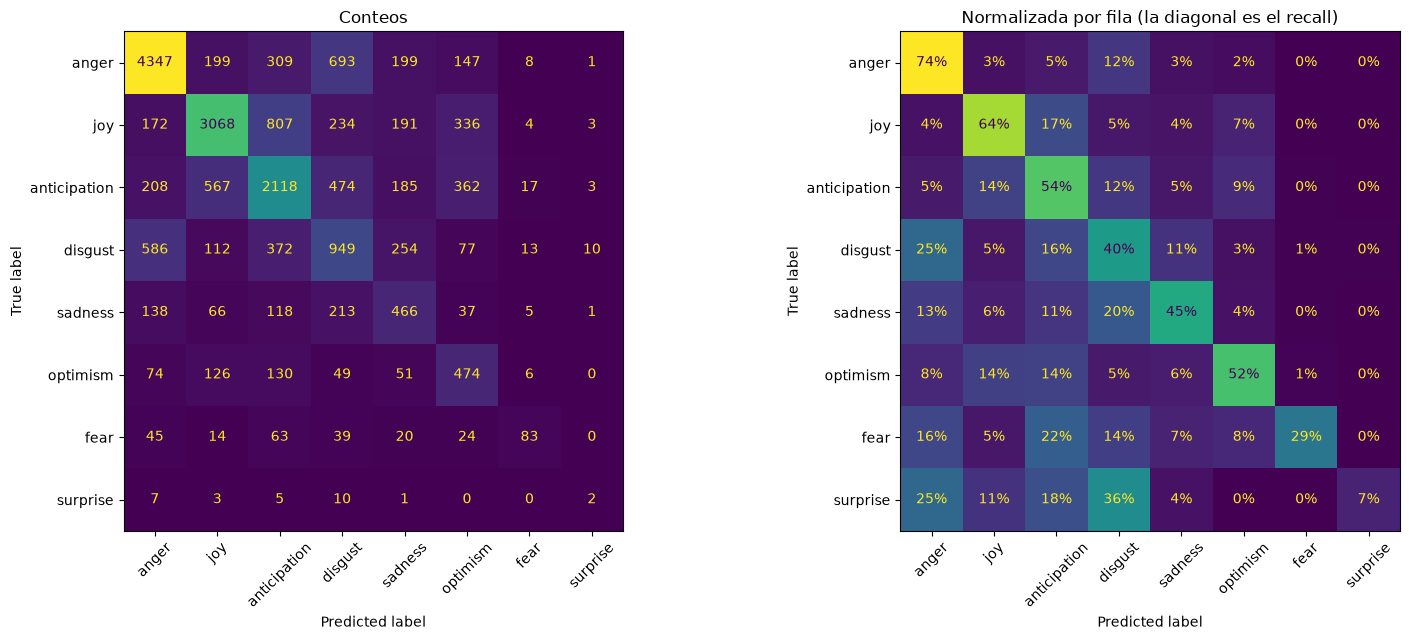

,tweets,precision,recall,f1,se confunde sobre todo con,% de sus tweets que van allí,clave
surprise,28,0.100,0.071,0.083,disgust,0.357,
disgust,2373,0.357,0.400,0.377,anger,0.247,sí
sadness,1044,0.341,0.446,0.387,disgust,0.204,
fear,288,0.610,0.288,0.392,anticipation,0.219,
optimism,910,0.325,0.521,0.401,anticipation,0.143,
anticipation,3934,0.540,0.538,0.539,joy,0.144,
joy,4815,0.738,0.637,0.684,anticipation,0.168,
anger,5903,0.779,0.736,0.757,disgust,0.117,sí


In [26]:
vec0, col = representaciones[mejor_rep]
y_real = df_tr['emotion'].values
prob_oof = np.zeros((len(df_tr), len(CLASES)))
for k, (a, v) in enumerate(folds):
    vec = clone(vec0)
    Fa = vec.fit_transform(df_tr[col].iloc[a])
    lr = LogisticRegression(max_iter=1000, class_weight=pesos_clase[mejor_peso]).fit(Fa, df_tr['emotion'].iloc[a])
    assert list(lr.classes_) == CLASES
    prob_oof[v] = lr.predict_proba(vec.transform(df_tr[col].iloc[v]))
pred_oof = np.array(CLASES)[prob_oof.argmax(axis=1)]
ORDEN = df_tr['emotion'].value_counts().index.tolist()
print(f'Tweets evaluados: {len(y_real)} | Exactitud: {(pred_oof == y_real).mean():.1%}')

fig, ejes = plt.subplots(1, 2, figsize=(16, 6.5))
ConfusionMatrixDisplay.from_predictions(y_real, pred_oof, labels=ORDEN, xticks_rotation=45, colorbar=False, ax=ejes[0])
ejes[0].set_title('Conteos')
ConfusionMatrixDisplay.from_predictions(y_real, pred_oof, labels=ORDEN, normalize='true', values_format='.0%',
                                        xticks_rotation=45, colorbar=False, ax=ejes[1])
ejes[1].set_title('Normalizada por fila (la diagonal es el recall)')
plt.tight_layout(); plt.show()

p, r, f, n = precision_recall_fscore_support(y_real, pred_oof, labels=ORDEN, zero_division=0)
ranking = pd.DataFrame({'tweets': n, 'precision': p, 'recall': r, 'f1': f}, index=ORDEN)
cm = pd.DataFrame(confusion_matrix(y_real, pred_oof, labels=ORDEN), index=ORDEN, columns=ORDEN)
fuera = cm.to_numpy().copy(); np.fill_diagonal(fuera, 0); fuera = pd.DataFrame(fuera, index=ORDEN, columns=ORDEN)
ranking['se confunde sobre todo con'] = fuera.idxmax(axis=1)
ranking['% de sus tweets que van allí'] = fuera.max(axis=1) / cm.sum(axis=1)
ranking['clave'] = ['sí' if e in CLASES_CLAVE else '' for e in ranking.index]
display(ranking.sort_values('f1').round(3))

**Cómo leer la matriz y el ranking**
- **`anger` es la mejor clasificada**, seguida de `joy` y `anticipation`.
- **`disgust` es la clase clave que peor se clasifica y se confunde sobre todo con `anger`**: son dos emociones negativas parecidas y, además, las etiquetas son ruidosas. Es la frontera más difícil para el negocio.
- **`fear` y `optimism` fallan de maneras opuestas**: `fear` tiene precisión alta y recall bajo (cuando dice fear acierta, pero deja pasar la mayoría); `optimism` se marca de más.
- `surprise` tiene muy pocos tweets y su F1 no es concluyente.

### 5.2 Umbral y abstención: ¿cuándo el modelo debe decir "no sé"?

La regresión logística entrega una **probabilidad para cada una de las 8 emociones**; la mayor es la *confianza*.

| Idea | Qué hace | Para qué sirve en Dell |
|---|---|---|
| **Abstención** | Si la confianza es menor que un umbral, el tweet pasa a una persona | Que lo automático sea más confiable, sabiendo qué fracción decide el modelo (**cobertura**) |
| **Umbral por clase** | Se dispara la alerta de `anger` o `disgust` si su probabilidad supera un valor, aunque no sea la más alta | Detectar más tweets clave a cambio de más falsas alarmas |

Primero se comprueba que la confianza sirve (a mayor confianza, más aciertos). Todo se calcula con probabilidades de validación; la prueba solo aplicará los umbrales elegidos aquí.

In [27]:
pred_p = pred_oof
conf = prob_oof.max(axis=1)
tramos = pd.cut(conf, [0, .3, .4, .5, .6, .7, .8, 1.0])
calibracion = (pd.DataFrame({'confianza': conf, 'acierto': pred_p == y_real, 'tramo': tramos})
               .groupby('tramo', observed=True)
               .agg(tweets=('acierto', 'size'), exactitud=('acierto', 'mean'), confianza_promedio=('confianza', 'mean')))
display(calibracion.round(3))

,tweets,exactitud,confianza_promedio
tramo,,,
"(0.0, 0.3]",5250,0.349,0.255
"(0.3, 0.4]",5716,0.511,0.346
"(0.4, 0.5]",3296,0.684,0.444
"(0.5, 0.6]",1974,0.814,0.546
"(0.6, 0.7]",1201,0.901,0.646
"(0.7, 0.8]",914,0.975,0.747
"(0.8, 1.0]",944,0.978,0.877


**Lectura.** A mayor confianza, más aciertos y sin saltos raros: la confianza **sí sirve para ordenar** qué tweets son más confiables. El modelo es "tímido" (acierta más de lo que dice), así que la confianza funciona como ranking, no como porcentaje exacto de acierto.

**Qué hacemos ahora.** Probamos umbrales de confianza de 0,20 a 0,80 y, para cada uno, medimos la cobertura (qué fracción decide el modelo solo), la exactitud de lo que decide y cuántos tweets clave pasan a una persona. Elegimos el umbral **más bajo** que logra el objetivo de exactitud. **Por qué el más bajo:** así se automatiza la mayor cantidad posible de tweets cumpliendo la calidad pedida.

,umbral,cobertura,exactitud_automaticos,f1_clave_automaticos,anger_disgust_a_revision
0,0.20,0.990,0.599,0.569,0.010
1,0.25,0.889,0.633,0.592,0.104
2,0.30,0.728,0.689,0.628,0.246
3,0.35,0.563,0.752,0.663,0.396
4,0.40,0.432,0.811,0.687,0.518
5,0.45,0.329,0.860,0.696,0.610
6,0.50,0.261,0.894,0.695,0.681
7,0.55,0.203,0.928,0.685,0.742
8,0.60,0.159,0.947,0.666,0.794
9,0.65,0.123,0.963,0.582,0.836


Umbral de abstención elegido: 0.35 -> el modelo decide el 56% de los tweets con 75% de exactitud; el resto (44%) va a revisión humana.


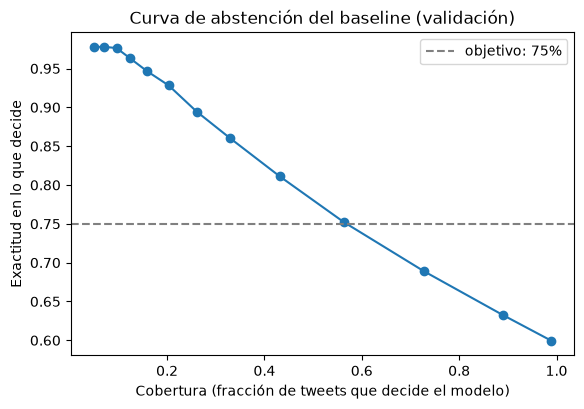

In [28]:
OBJETIVO_EXACTITUD = 0.75    # parámetro de negocio: lo que el modelo clasifique solo debe acertar al menos el 75 %
es_clave = np.isin(y_real, CLASES_CLAVE)

def curva_abstencion(y, pred, confianza, umbrales=np.arange(0.20, 0.96, 0.05)):
    filas = []
    clave = np.isin(y, CLASES_CLAVE)
    for u in umbrales:
        auto = confianza >= u
        f1c = f1_score(y[auto], pred[auto], labels=CLASES_CLAVE, average=None, zero_division=0).mean() if auto.any() else np.nan
        filas.append({'umbral': round(float(u), 2), 'cobertura': auto.mean(),
                      'exactitud_automaticos': (pred[auto] == y[auto]).mean() if auto.any() else np.nan,
                      'f1_clave_automaticos': f1c,
                      'anger_disgust_a_revision': (~auto & clave).sum() / max(clave.sum(), 1)})
    return pd.DataFrame(filas)

def elegir_umbral(curva, objetivo=OBJETIVO_EXACTITUD):
    cumplen = curva[curva.exactitud_automaticos >= objetivo]
    return float(cumplen.umbral.min()) if len(cumplen) else None

curva = curva_abstencion(y_real, pred_p, conf, np.arange(0.20, 0.85, 0.05))
display(curva.round(3))
UMBRAL_ABST = elegir_umbral(curva)
if UMBRAL_ABST is None:
    UMBRAL_ABST = 0.0
    print('Ningún umbral logra el objetivo: no se aplica abstención.')
else:
    fila = curva[curva.umbral == round(UMBRAL_ABST, 2)].iloc[0]
    print(f'Umbral de abstención elegido: {UMBRAL_ABST:.2f} -> el modelo decide el {fila.cobertura:.0%} de los tweets con '
          f'{fila.exactitud_automaticos:.0%} de exactitud; el resto ({1 - fila.cobertura:.0%}) va a revisión humana.')
plt.figure(figsize=(6.5, 4.2))
plt.plot(curva.cobertura, curva.exactitud_automaticos, marker='o')
plt.axhline(OBJETIVO_EXACTITUD, color='gray', linestyle='--', label=f'objetivo: {OBJETIVO_EXACTITUD:.0%}')
plt.xlabel('Cobertura (fracción de tweets que decide el modelo)'); plt.ylabel('Exactitud en lo que decide')
plt.title('Curva de abstención del baseline (validación)'); plt.legend(); plt.show()

**Cómo leer la curva de abstención**
- **Es un intercambio, no una mejora gratis.** Subir el umbral hace más confiable lo automático, pero cada punto de exactitud se paga con tweets que pasan a una persona.
- **La abstención no detecta más `anger` ni `disgust`**: hace que lo que el modelo clasifica solo sea más correcto. Una parte de los tweets clave queda en revisión humana, que es donde se atienden.
- **El 75 % es una referencia, no un óptimo.** Se fijó como exactitud mínima de lo que el modelo clasifica solo: mejora la exactitud de cerca de 60 % a 75 %, pero el valor definitivo depende del costo de un error y de la capacidad de revisión de Dell. Se cambia con `OBJETIVO_EXACTITUD`.

**Qué hacemos ahora: umbral por clase.** Para `anger` y `disgust` probamos umbrales de 0,15 a 0,50: si la probabilidad de esa emoción supera el umbral, se dispara la alerta aunque no sea la emoción más probable. Elegimos el umbral que maximiza el F1 de cada clase y comparamos las tres políticas. **Por qué:** es la forma más barata de detectar más tweets clave sin cambiar de modelo.

In [29]:
def aplicar_umbrales(prob, umbrales):
    """Emoción más probable, salvo que anger o disgust superen su umbral: entonces gana la más probable de las que lo superan."""
    base = prob.argmax(axis=1)
    puntaje = np.full(prob.shape, -1.0)
    for clase, th in umbrales.items():
        j = CLASES.index(clase)
        puntaje[:, j] = np.where(prob[:, j] >= th, prob[:, j], -1.0)
    hay_alerta = puntaje.max(axis=1) >= 0
    return np.array(CLASES)[np.where(hay_alerta, puntaje.argmax(axis=1), base)]

umbrales_prueba = [None] + [round(x, 2) for x in np.arange(0.15, 0.55, 0.05)]
filas = []
for th in umbrales_prueba:
    fila = {'umbral': 'más probable' if th is None else th}
    for clase in CLASES_CLAVE:
        pr = pred_p if th is None else aplicar_umbrales(prob_oof, {clase: th})
        prf = precision_recall_fscore_support(y_real, pr, labels=[clase], zero_division=0)
        fila[f'{clase} precisión'], fila[f'{clase} recall'], fila[f'{clase} F1'] = prf[0][0], prf[1][0], prf[2][0]
    filas.append(fila)
tabla_umbral = pd.DataFrame(filas).set_index('umbral')
display(tabla_umbral.round(3))
UMBRALES = {clase: float(tabla_umbral.iloc[1:][f'{clase} F1'].astype(float).idxmax()) for clase in CLASES_CLAVE}
print('Umbrales elegidos (máximo F1 de cada clase):', UMBRALES)

def resumen_politica(nombre, y, pred, decide=None):
    decide = np.ones(len(y), dtype=bool) if decide is None else decide
    clave = np.isin(y, CLASES_CLAVE)
    pr = precision_recall_fscore_support(y[decide], pred[decide], labels=CLASES_CLAVE, zero_division=0)
    return {'política': nombre, 'cobertura': decide.mean(), 'exactitud': (pred[decide] == y[decide]).mean(),
            'F1 clave': pr[2].mean(), 'recall anger': pr[1][0], 'recall disgust': pr[1][1],
            'precisión anger': pr[0][0], 'precisión disgust': pr[0][1],
            'anger/disgust a revisión': (~decide & clave).sum() / clave.sum()}

politicas_val = pd.DataFrame([
    resumen_politica('1. Emoción más probable', y_real, pred_p),
    resumen_politica('2. Umbral por clase (anger y disgust)', y_real, aplicar_umbrales(prob_oof, UMBRALES)),
    resumen_politica(f'3. Abstención (umbral {UMBRAL_ABST:.2f})', y_real, pred_p, conf >= UMBRAL_ABST),
]).set_index('política')
display(politicas_val.round(3))

,anger precisión,anger recall,anger F1,disgust precisión,disgust recall,disgust F1
umbral,,,,,,
más probable,0.779,0.736,0.757,0.357,0.400,0.377
0.15,0.618,0.909,0.736,0.235,0.818,0.365
0.2,0.711,0.839,0.769,0.289,0.624,0.395
0.25,0.759,0.786,0.772,0.328,0.485,0.392
0.3,0.775,0.753,0.764,0.346,0.423,0.380
0.35,0.780,0.740,0.759,0.354,0.403,0.377
0.4,0.779,0.736,0.757,0.357,0.401,0.377
0.45,0.779,0.736,0.757,0.357,0.400,0.377
0.5,0.779,0.736,0.757,0.357,0.400,0.377


Umbrales elegidos (máximo F1 de cada clase): {'anger': 0.25, 'disgust': 0.2}


,cobertura,exactitud,F1 clave,recall anger,recall disgust,precisión anger,precisión disgust,anger/disgust a revisión
política,,,,,,,,
1. Emoción más probable,1.000,0.596,0.567,0.736,0.400,0.779,0.357,0.000
2. Umbral por clase (anger y disgust),1.000,0.588,0.576,0.742,0.511,0.775,0.321,0.000
3. Abstención (umbral 0.35),0.563,0.752,0.663,0.880,0.455,0.870,0.448,0.396


**Comparación de las tres políticas en validación**
- **Umbral por clase:** sube el recall de `disgust` y el F1 clave a cambio de algo de precisión; todos los tweets se siguen clasificando solos.
- **Abstención:** da el F1 clave más alto, pero solo sobre los tweets que el modelo decide; el resto lo resuelve una persona, así que no es comparable directamente con las otras filas.
- Las dos ideas son complementarias (una mejora qué se detecta y la otra qué tan confiable es lo automático).

# 6. Redes recurrentes: SimpleRNN, LSTM, GRU y BiLSTM

**Qué cambia frente al baseline.** TF-IDF cuenta qué palabras aparecen; una red recurrente **lee el tweet palabra por palabra en orden** y guarda una memoria de lo leído. Eso le permite captar la negación (`not working`) o el contraste (`great, but the screen died`).

| Paso | Qué se hace | Dónde |
|---|---|---|
| a | Aprender el vocabulario solo con entrenamiento | 6.1 |
| b | Convertir palabras en índices | 6.1 |
| c | Elegir la longitud máxima con percentiles | 6.1 (se decide **no truncar**) |
| d | Padding y truncamiento | 6.1 |
| e | Embeddings de 32, 64 o 128 números por palabra | 6.2 y 6.4 |
| f | Procesar la secuencia con RNN, LSTM, GRU o BiLSTM | 6.2 |
| g | Obtener logits y aplicar softmax | 6.2 y 6.3 |
| h | Entrenar con entropía cruzada | 6.2 y 6.3 |
| i | Elegir el modelo con la validación | 6.5 |
| j | Usar la prueba una sola vez, al final | Sección 8 |

## 6.1 Vocabulario, longitud, padding e índices (pasos a a d)

- **Vocabulario:** se aprende **solo con el entrenamiento de cada pliegue** y se limita a las 20.000 palabras más frecuentes; las demás se vuelven `[UNK]`.
- **Índices:** 0 = relleno (`PAD`), 1 = `[UNK]`.
- **Longitud:** los tweets son cortos, así que **no se trunca el entrenamiento**: se rellena con ceros hasta el tweet más largo del entrenamiento y el `masking` hace que la red ignore los ceros.

In [30]:
import tensorflow as tf
tf.get_logger().setLevel('ERROR')

lon_tr = df_tr['Texto limpio'].str.split().str.len()
print(lon_tr.describe(percentiles=[.5, .9, .95, .99]).round(1).to_string())
SEQ_LEN = int(lon_tr.max())
MAX_TOKENS = 20000
print(f'\nLongitud de las secuencias: {SEQ_LEN} | ¿Hay tweets de prueba más largos? {df_te["Texto limpio"].str.split().str.len().max() > SEQ_LEN}')

def preparar_secuencias(textos_entrenamiento, *otros_textos):
    """(a) aprende el vocabulario SOLO con textos_entrenamiento; (b)(d) convierte todos a índices con padding."""
    capa = tf.keras.layers.TextVectorization(max_tokens=MAX_TOKENS, standardize=None, split='whitespace',
                                             output_mode='int', output_sequence_length=SEQ_LEN)
    capa.adapt(tf.data.Dataset.from_tensor_slices(textos_entrenamiento.values).batch(512))
    return capa, [capa(t.values).numpy() for t in (textos_entrenamiento, *otros_textos)]

a, v = folds[0]
capa_ej, (Sa_ej, Sv_ej) = preparar_secuencias(df_tr['Texto limpio'].iloc[a], df_tr['Texto limpio'].iloc[v])
oov = (Sv_ej == 1).sum() / (Sv_ej != 0).sum()
print(f'Vocabulario aprendido: {len(capa_ej.get_vocabulary())} | Tasa OOV en validación: {oov:.1%}')
texto_ej = df_tr['Texto limpio'].iloc[v].iloc[0]
print('Texto  :', texto_ej[:150]); print('Índices:', Sv_ej[0][:len(texto_ej.split()) + 4])

count    19295.0
mean        22.8
std         14.5
min          1.0
50%         21.0
90%         44.0
95%         48.0
99%         53.0
max         65.0

Longitud de las secuencias: 65 | ¿Hay tweets de prueba más largos? True


Vocabulario aprendido: 20000 | Tasa OOV en validación: 4.2%
Texto  : what does it take to delight stakeholders with the online experience this whitepaper on technologies apex shows how it transformation paves a path to 
Índices: [  49  147   11  127    3 2624 2306   14    2  369  132   17 1911   15
  200  490  521   40   11  963 2899    5 1650    3    2 2896  257 1805
  171   40    2  123   30 7582  214   32   46   10  360    0    0    0
    0]


## 6.2 La arquitectura (pasos e a h)

1. **Embedding:** cada índice se vuelve un vector de `dim` números que la red aprende.
2. **Capa recurrente:** `SimpleRNN`, `LSTM`, `GRU` o `Bidirectional(LSTM)`, con 64 unidades y `dropout`.
3. **Dropout:** segunda protección contra la memorización.
4. **Capa densa:** ocho **logits**, uno por emoción; softmax los convierte en probabilidades.

**Entropía cruzada** (la misma cantidad que el *log loss*): se calcula sobre los logits (`from_logits=True`). Optimizador Adam (lr = 0,001) con *gradient clipping* (`clipnorm=1.0`).

In [31]:
def construir_modelo(tipo, bidireccional, tam_vocab, dim, unidades=64, dropout=0.3, lr=1e-3):
    entrada = tf.keras.Input((SEQ_LEN,), dtype='int64')
    x = tf.keras.layers.Embedding(tam_vocab, dim, mask_zero=True)(entrada)
    capa_rec = {'rnn': tf.keras.layers.SimpleRNN, 'lstm': tf.keras.layers.LSTM, 'gru': tf.keras.layers.GRU}[tipo]
    rec = capa_rec(unidades, dropout=dropout)
    x = tf.keras.layers.Bidirectional(rec)(x) if bidireccional else rec(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    logits = tf.keras.layers.Dense(len(CLASES))(x)
    m = tf.keras.Model(entrada, logits)
    m.compile(optimizer=tf.keras.optimizers.Adam(lr, clipnorm=1.0),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True))
    return m

ARQUITECTURAS = {'SimpleRNN': ('rnn', False), 'LSTM': ('lstm', False), 'GRU': ('gru', False), 'BiLSTM': ('lstm', True)}
for nombre, (tipo, bi) in ARQUITECTURAS.items():
    print(f'{nombre:10s} parámetros (vocabulario de 5.000, embedding de 64): {construir_modelo(tipo, bi, 5000, 64).count_params():,}')

SimpleRNN  parámetros (vocabulario de 5.000, embedding de 64): 328,776
LSTM       parámetros (vocabulario de 5.000, embedding de 64): 353,544
GRU        parámetros (vocabulario de 5.000, embedding de 64): 345,480


BiLSTM     parámetros (vocabulario de 5.000, embedding de 64): 387,080


## 6.3 Entrenar y evaluar un pliegue

`entrenar_pliegue` hace todo el ciclo: aprende el vocabulario del pliegue, entrena con entropía cruzada (con pesos por clase si en la sección 5 resultó mejor `balanced`), usa **parada temprana** (si la pérdida de validación no mejora en 2 épocas, se detiene y recupera los mejores pesos), aplica softmax y calcula las métricas.

**Por qué la parada temprana.** Al principio cada época mejora de verdad, pero luego la red empieza a memorizar el entrenamiento (sobreajuste): la pérdida de entrenamiento sigue bajando y la de validación deja de bajar. Ese es el momento de parar.

In [32]:
from sklearn.utils.class_weight import compute_class_weight
cache_rnn = {}

def entrenar_pliegue(nombre, dim, k):
    clave = (nombre, dim, k)
    if clave in cache_rnn:
        return cache_rnn[clave]
    a, v = folds[k]
    capa, (Sa, Sv) = preparar_secuencias(df_tr['Texto limpio'].iloc[a], df_tr['Texto limpio'].iloc[v])
    ya, yv = le.transform(df_tr['emotion'].iloc[a]), le.transform(df_tr['emotion'].iloc[v])
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEMILLA)
    tipo, bi = ARQUITECTURAS[nombre]
    modelo = construir_modelo(tipo, bi, len(capa.get_vocabulary()), dim)
    pesos = dict(enumerate(compute_class_weight('balanced', classes=np.arange(len(CLASES)), y=ya))) if USAR_PESOS else None
    t = time.perf_counter()
    h = modelo.fit(Sa, ya, validation_data=(Sv, yv), epochs=EPOCAS_MAX, batch_size=64, class_weight=pesos, verbose=0,
                   callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)])
    seg = time.perf_counter() - t
    prob = tf.nn.softmax(modelo.predict(Sv, verbose=0)).numpy()
    pred = le.inverse_transform(prob.argmax(axis=1))
    res = calcular_metricas(df_tr['emotion'].iloc[v].values, pred, prob)
    res.update(modelo=nombre, dim=dim, pliegue=k + 1, parametros=modelo.count_params(), segundos=seg,
               epocas=len(h.history['loss']), epoca_optima=int(np.argmin(h.history['val_loss'])) + 1)
    print(f'{nombre:10s} dim={dim:3d} pliegue {k + 1}: F1 clave={res["f1_clave"]:.3f} | {seg:4.0f} s | {res["epocas"]} épocas (óptima: {res["epoca_optima"]})', flush=True)
    cache_rnn[clave] = res
    return res

## 6.4 Búsqueda del tamaño del embedding

El tamaño del embedding es un **hiperparámetro**. Se prueban 32, 64 y 128 con las cuatro arquitecturas, **solo en el pliegue 1** (para que el tiempo sea razonable en CPU), y los mejores pasan a la validación cruzada de 5 pliegues.

In [33]:
DIMS = [32] if MODO_RAPIDO else [32, 64, 128]
busqueda = pd.DataFrame([entrenar_pliegue(n, d, 0) for n in ARQUITECTURAS for d in DIMS])
print('\nF1 clave en el pliegue 1 (filas = arquitectura, columnas = tamaño del embedding):')
display(busqueda.pivot(index='modelo', columns='dim', values='f1_clave').loc[list(ARQUITECTURAS)].round(3))
mejor_dim = (busqueda.sort_values(['f1_clave', 'f1_macro'], ascending=False)
                     .groupby('modelo').head(1).set_index('modelo')['dim'].astype(int))
print('Tamaño de embedding elegido:', mejor_dim.loc[list(ARQUITECTURAS)].to_dict())

SimpleRNN  dim= 32 pliegue 1: F1 clave=0.471 |   35 s | 6 épocas (óptima: 4)


SimpleRNN  dim= 64 pliegue 1: F1 clave=0.449 |   42 s | 5 épocas (óptima: 3)


SimpleRNN  dim=128 pliegue 1: F1 clave=0.416 |   42 s | 4 épocas (óptima: 2)


LSTM       dim= 32 pliegue 1: F1 clave=0.545 |  116 s | 8 épocas (óptima: 6)


LSTM       dim= 64 pliegue 1: F1 clave=0.507 |   94 s | 6 épocas (óptima: 4)


LSTM       dim=128 pliegue 1: F1 clave=0.573 |   90 s | 5 épocas (óptima: 3)


... (5 outputs left out)

BiLSTM     dim=128 pliegue 1: F1 clave=0.540 |  144 s | 5 épocas (óptima: 3)



F1 clave en el pliegue 1 (filas = arquitectura, columnas = tamaño del embedding):


dim,32,64,128
modelo,,,
SimpleRNN,0.471,0.449,0.416
LSTM,0.545,0.507,0.573
GRU,0.511,0.507,0.503
BiLSTM,0.541,0.569,0.540


Tamaño de embedding elegido: {'SimpleRNN': 32, 'LSTM': 128, 'GRU': 32, 'BiLSTM': 64}


**Lectura.** Si el mejor tamaño salta de un lado a otro entre arquitecturas, las diferencias son sobre todo ruido del entrenamiento. Por eso la comparación justa es la de 5 pliegues que sigue.

## 6.5 Comparación con validación cruzada de 5 pliegues (paso i)

In [34]:
res_rnn = pd.DataFrame([entrenar_pliegue(n, int(mejor_dim[n]), k) for n in ARQUITECTURAS for k in range(N_PLIEGUES)])
cols = ['f1_clave', 'f1_macro', 'f1_anger', 'f1_disgust', 'recall_anger', 'recall_disgust', 'log_loss', 'parametros', 'segundos']
resumen_rnn = res_rnn.groupby('modelo', sort=False)[cols].mean()
resumen_rnn['f1_clave_desv'] = res_rnn.groupby('modelo', sort=False)['f1_clave'].std()
resumen_rnn.insert(0, 'dim', res_rnn.groupby('modelo', sort=False)['dim'].first())
resumen_rnn['epocas_optimas'] = res_rnn.groupby('modelo', sort=False)['epoca_optima'].median()

fila_base = resumen_base.loc[[(mejor_rep, mejor_peso)]].copy()
fila_base.index = [f'Baseline: TF-IDF {mejor_rep}']
tabla_cv = pd.concat([fila_base, resumen_rnn]).sort_values(['f1_clave', 'f1_macro'], ascending=False)
display(tabla_cv.round(3))
campeon_rnn = resumen_rnn.sort_values(['f1_clave', 'f1_macro'], ascending=False).index[0]
print(f'Mejor red recurrente en validación: {campeon_rnn} (embedding de {int(resumen_rnn.loc[campeon_rnn, "dim"])})')

SimpleRNN  dim= 32 pliegue 2: F1 clave=0.471 |   43 s | 6 épocas (óptima: 4)


SimpleRNN  dim= 32 pliegue 3: F1 clave=0.473 | 1788 s | 7 épocas (óptima: 5)


SimpleRNN  dim= 32 pliegue 4: F1 clave=0.474 |   35 s | 6 épocas (óptima: 4)


SimpleRNN  dim= 32 pliegue 5: F1 clave=0.465 |   33 s | 6 épocas (óptima: 4)


LSTM       dim=128 pliegue 2: F1 clave=0.531 |   75 s | 5 épocas (óptima: 3)


LSTM       dim=128 pliegue 3: F1 clave=0.476 |   91 s | 5 épocas (óptima: 3)


... (8 outputs left out)

BiLSTM     dim= 64 pliegue 4: F1 clave=0.553 |  157 s | 6 épocas (óptima: 4)


BiLSTM     dim= 64 pliegue 5: F1 clave=0.522 |  147 s | 6 épocas (óptima: 4)


,f1_clave,f1_macro,f1_anger,f1_disgust,recall_anger,recall_disgust,log_loss,parametros,segundos,f1_clave_desv,dim,epocas_optimas
Baseline: TF-IDF lemas 1-2,0.567,0.454,0.757,0.377,0.736,0.400,1.209,323059.2,5.257,0.007,NaN,NaN
BiLSTM,0.541,0.395,0.752,0.330,0.725,0.360,1.310,1347080.0,130.938,0.026,64.0,4.0
LSTM,0.533,0.384,0.744,0.322,0.698,0.330,1.310,2609928.0,89.054,0.036,128.0,3.0
GRU,0.513,0.352,0.741,0.285,0.710,0.302,1.379,659336.0,720.564,0.016,32.0,3.0
SimpleRNN,0.471,0.290,0.702,0.240,0.689,0.244,1.510,646728.0,386.833,0.004,32.0,4.0


Mejor red recurrente en validación: BiLSTM (embedding de 64)


**Cómo leer la comparación en validación cruzada**
- **Entre las redes, el orden sigue la teoría:** las que tienen compuertas (BiLSTM, LSTM, GRU) superan a la SimpleRNN, que olvida lo lejano.
- **Las redes no le ganan al baseline en validación:** el baseline tiene mejor o igual F1 clave, es más estable entre pliegues que las redes con compuertas y se entrena muchas veces más rápido.
- **Posible explicación (hipótesis):** los tweets son cortos y las etiquetas ruidosas; con unos 19.000 ejemplos, saber el orden de las palabras aporta poco frente a saber cuáles aparecen, y las redes, que aprenden sus embeddings desde cero, tienen mucha capacidad para memorizar. Un modelo **preentrenado** como BERT ataca justamente esta limitación (sección 7).

# 7. Transformer: BERT (`bert-base-uncased`)

**Qué cambia frente a las redes recurrentes.**
- **Self-attention:** cada token se relaciona directamente con todos los demás en una sola capa (no paso a paso), así que la negación o el contraste lejano quedan a un salto de distancia.
- **Preentrenamiento y transferencia:** BERT ya aprendió el inglés general (Wikipedia y libros) prediciendo palabras ocultas (*Masked Language Modeling*). Nosotros solo lo **ajustamos** (*fine-tuning*) a las 8 emociones. Las redes de la sección 6 aprendían todo desde cero con 19.000 tweets.
- **Representación contextual:** la misma palabra recibe vectores distintos según la oración (`sick laptop!` frente a `I'm sick of this laptop`).

**Por qué `bert-base-uncased`.** Los tweets están en inglés (BETO es para español). Es el BERT de referencia (12 capas, 768 dimensiones, 12 cabezas de atención, unos 110 millones de parámetros) y no distingue mayúsculas. Se descartó `twitter-roberta-base`: aunque está preentrenado con tweets, es de la misma familia del modelo que puso las etiquetas, y el resultado podría ser circular (imitar al etiquetador por parentesco y no por comprender el texto).

**Diseño del experimento (comparación justa).**

| Decisión | Valor | Por qué |
|---|---|---|
| Partición | La misma: pliegue 1 para entrenar y validar, prueba sellada | Misma base de comparación que el baseline y las redes |
| Texto de entrada | `Texto BERT` (limpieza mínima, sección 3) | El tokenizador de BERT aprovecha puntuación y contexto |
| Pérdida | Entropía cruzada **con pesos por clase** si `USAR_PESOS` | La misma decisión que en el baseline y las redes |
| Estrategia | *Fine-tuning* completo (todas las capas + cabeza de clasificación sobre `[CLS]`) | Mayor adaptación al dominio |
| Optimizador | AdamW, lr = 2e-5, *weight decay* 0,01, *warmup* 10 %, scheduler lineal, *clipping* 1,0 | Valores iniciales habituales para BERT (Sesión 4) |
| Lote y épocas | 16 tweets por lote; hasta 3 épocas (`EPOCAS_BERT`); se elige la mejor época por **F1 clave** de validación | Presupuesto de CPU: cerca de 80 minutos por época (unas 4 horas en total en esta corrida) |
| Padding | Dinámico y lotes agrupados por longitud | Reduce cómputo desperdiciado en relleno |
| Validación | Solo el pliegue 1 (no 5) | Cinco pliegues tardarían más de 15 horas en CPU |
| Modelo para prueba | El del pliegue 1 en su mejor época, **sin reentrenar** con todo el entrenamiento | Reentrenar duplicaría el tiempo. BERT queda en **leve desventaja** (aprende con 80 % de los datos que usan los otros modelos en la prueba) |

## 7.1 Tokenizador: subpalabras y longitud máxima

In [35]:
import torch
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
                          TrainingArguments, Trainer, set_seed)
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
torch.set_num_threads(os.cpu_count())

CHECKPOINT = 'bert-base-uncased'
tok = AutoTokenizer.from_pretrained(CHECKPOINT)

ej_txt = df_tr['Texto BERT'].iloc[3]
enc = tok(ej_txt)
print('Texto  :', ej_txt[:160])
print('Tokens :', tok.convert_ids_to_tokens(enc['input_ids'])[:40])

lon_tok = pd.Series([len(x) for x in tok(df_tr['Texto BERT'].tolist())['input_ids']])
print('\nTokens por tweet (incluye [CLS] y [SEP]):')
print(lon_tok.describe(percentiles=[.5, .9, .95, .99]).round(1).to_string())
MAX_LEN = int(min(128, np.ceil(lon_tok.quantile(0.99) / 8) * 8))
print(f'\nLongitud máxima elegida (percentil 99, múltiplo de 8): {MAX_LEN} tokens | tweets truncados: {(lon_tok > MAX_LEN).mean():.2%}')
ids_tr = [i for x in tok(df_tr['Texto BERT'].tolist())['input_ids'] for i in x]
print(f'Tasa de [UNK] (tokens desconocidos): {np.mean(np.array(ids_tr) == tok.unk_token_id):.2%}')
pal = df_tr['Texto BERT'].str.split().str.len()
print(f'Subpalabras por palabra (promedio): {(lon_tok.values - 2).sum() / pal.sum():.2f}')

C:\Users\usuario 1\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Texto  : @user your customer service is horrible especially agent syedfaisal who has made this experience of purchasing a new computer downright awful and I’ll reconside
Tokens : ['[CLS]', '@', 'user', 'your', 'customer', 'service', 'is', 'horrible', 'especially', 'agent', 'syed', '##fa', '##isa', '##l', 'who', 'has', 'made', 'this', 'experience', 'of', 'purchasing', 'a', 'new', 'computer', 'down', '##right', 'awful', 'and', 'i', '’', 'll', 'rec', '##ons', '##ider', 'ever', 'buying', 'a', 'dell', 'in', 'the']



Tokens por tweet (incluye [CLS] y [SEP]):
count    19295.0
mean        40.2
std         19.5
min          5.0
50%         39.0
90%         66.0
95%         71.0
99%         80.0
max        168.0

Longitud máxima elegida (percentil 99, múltiplo de 8): 80 tokens | tweets truncados: 0.99%


Tasa de [UNK] (tokens desconocidos): 0.44%
Subpalabras por palabra (promedio): 1.42


**Lectura.**
- **Subpalabras:** las palabras frecuentes quedan enteras y las raras se parten en piezas con `##` (por ejemplo, nombres de productos). Por eso BERT casi no tiene palabras desconocidas: la tasa de `[UNK]` es mucho menor que la tasa OOV de las redes. Los `[UNK]` que quedan son sobre todo **emojis**, que el vocabulario de `bert-base-uncased` no incluye.
- **Longitud:** un tweet usa más tokens que palabras. El percentil 99 fija `MAX_LEN`, de modo que casi ningún tweet se trunca, y el padding dinámico evita rellenar todos los lotes hasta esa longitud.

## 7.2 Datos para PyTorch y entrenador con pesos por clase

In [36]:
from torch.utils.data import Dataset as TorchDataset

class DatasetTweets(TorchDataset):
    """Tokeniza una vez y entrega cada tweet como diccionario de tensores (input_ids, attention_mask, labels)."""
    def __init__(self, textos, etiquetas=None):
        self.enc = tok(list(textos), truncation=True, max_length=MAX_LEN)
        self.y = None if etiquetas is None else [int(e) for e in etiquetas]
    def __len__(self):
        return len(self.enc['input_ids'])
    def __getitem__(self, i):
        item = {k: self.enc[k][i] for k in self.enc}
        if self.y is not None:
            item['labels'] = self.y[i]
        return item

class TrainerPonderado(Trainer):
    """Trainer de Hugging Face con entropía cruzada ponderada por clase (equivalente a class_weight='balanced')."""
    def __init__(self, *args, pesos_clase=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.pesos_clase = pesos_clase
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        etiquetas = inputs.pop('labels')
        salida = model(**inputs)
        w = None if self.pesos_clase is None else self.pesos_clase.to(salida.logits.device)
        perdida = torch.nn.functional.cross_entropy(salida.logits, etiquetas, weight=w)
        return (perdida, salida) if return_outputs else perdida

def metricas_trainer(eval_pred):
    logits, etiquetas = eval_pred
    prob = torch.softmax(torch.tensor(logits), dim=-1).numpy()
    return calcular_metricas(le.inverse_transform(etiquetas), le.inverse_transform(prob.argmax(axis=1)), prob)

a1, v1 = folds[0]
txt_a, txt_v = df_tr['Texto BERT'].iloc[a1], df_tr['Texto BERT'].iloc[v1]
y_a, y_v = le.transform(df_tr['emotion'].iloc[a1]), le.transform(df_tr['emotion'].iloc[v1])
if MODO_RAPIDO:
    txt_a, y_a, txt_v, y_v = txt_a[:300], y_a[:300], txt_v[:200], y_v[:200]
ds_a, ds_v = DatasetTweets(txt_a, y_a), DatasetTweets(txt_v, y_v)
# Pesos 'balanced': n / (número de clases × tweets de la clase); misma fórmula que class_weight='balanced' de scikit-learn
cuentas = np.bincount(y_a, minlength=len(CLASES))
pesos_bert = torch.tensor(len(y_a) / (len(CLASES) * np.maximum(cuentas, 1)), dtype=torch.float) if USAR_PESOS else None
print(f'Entrenamiento (pliegue 1): {len(ds_a)} | Validación (pliegue 1): {len(ds_v)} | Pesos por clase: {USAR_PESOS}')

Entrenamiento (pliegue 1): 15436 | Validación (pliegue 1): 3859 | Pesos por clase: True


## 7.3 Fine-tuning en el pliegue 1

Se evalúa en validación al final de cada época y se guarda el punto de control; al terminar, el `Trainer` **recupera la época con mayor F1 clave** (`load_best_model_at_end`). Es el equivalente a la parada temprana de las redes.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Loading weights:   6%|▌         | 12/199 [00:00<00:02, 85.95it/s]


Loading weights:  11%|█         | 22/199 [00:00<00:01, 91.60it/s]


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 775.32it/s]

{'loss': '2.119', 'grad_norm': '5.003', 'learning_rate': '6.851e-06', 'epoch': '0.1036'}


{'loss': '1.949', 'grad_norm': '6.162', 'learning_rate': '1.377e-05', 'epoch': '0.2073'}


... (38 outputs left out)

{'train_runtime': '1.437e+04', 'train_samples_per_second': '3.223', 'train_steps_per_second': '0.202', 'train_loss': '0.878', 'epoch': '3'}


Tiempo de entrenamiento: 239.5 min


,eval_loss,eval_f1_clave,eval_f1_macro,eval_f1_anger,eval_f1_disgust,eval_recall_anger,eval_recall_disgust
epoch,,,,,,,
1.0,1.067,0.663,0.581,0.817,0.509,0.768,0.614
2.0,0.952,0.689,0.605,0.848,0.530,0.810,0.553
3.0,1.002,0.700,0.631,0.856,0.543,0.830,0.591


Mejor época por F1 clave de validación: 3


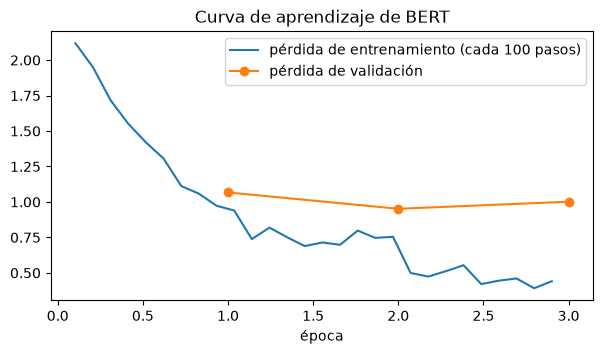

In [37]:
set_seed(SEMILLA)
modelo_bert = AutoModelForSequenceClassification.from_pretrained(
    CHECKPOINT, num_labels=len(CLASES), id2label=dict(enumerate(CLASES)), label2id={c: i for i, c in enumerate(CLASES)})
BATCH_BERT, LR_BERT = 16, 2e-5
pasos_totales = int(np.ceil(len(ds_a) / BATCH_BERT)) * EPOCAS_BERT
DIR_CKPT = os.path.join(DIR_ART, 'bert_checkpoints')
args_bert = TrainingArguments(
    output_dir=DIR_CKPT, learning_rate=LR_BERT, per_device_train_batch_size=BATCH_BERT, per_device_eval_batch_size=64,
    num_train_epochs=EPOCAS_BERT, weight_decay=0.01, warmup_steps=int(0.1 * pasos_totales), lr_scheduler_type='linear',
    max_grad_norm=1.0, eval_strategy='epoch', save_strategy='epoch', load_best_model_at_end=True,
    metric_for_best_model='f1_clave', greater_is_better=True, save_total_limit=1, save_only_model=True,
    train_sampling_strategy='group_by_length', logging_steps=100, seed=SEMILLA, report_to='none', dataloader_pin_memory=False,
    disable_tqdm=True)
entrenador = TrainerPonderado(model=modelo_bert, args=args_bert, train_dataset=ds_a, eval_dataset=ds_v,
                              data_collator=DataCollatorWithPadding(tok), processing_class=tok, compute_metrics=metricas_trainer,
                              pesos_clase=pesos_bert)
t = time.perf_counter()
entrenador.train()
SEG_BERT = time.perf_counter() - t
print(f'Tiempo de entrenamiento: {SEG_BERT / 60:.1f} min')

historial = pd.DataFrame([h for h in entrenador.state.log_history if 'eval_f1_clave' in h])
historial = historial[['epoch', 'eval_loss', 'eval_f1_clave', 'eval_f1_macro', 'eval_f1_anger', 'eval_f1_disgust',
                       'eval_recall_anger', 'eval_recall_disgust']]
display(historial.round(3).set_index('epoch'))
EPOCA_BERT = int(historial.loc[historial['eval_f1_clave'].idxmax(), 'epoch'])
print(f'Mejor época por F1 clave de validación: {EPOCA_BERT}')
perdida_ent = pd.DataFrame([h for h in entrenador.state.log_history if 'loss' in h and 'eval_loss' not in h])
if len(perdida_ent):
    plt.figure(figsize=(7, 3.5))
    plt.plot(perdida_ent['epoch'], perdida_ent['loss'], label='pérdida de entrenamiento (cada 100 pasos)')
    plt.plot(historial['epoch'], historial['eval_loss'], 'o-', label='pérdida de validación')
    plt.xlabel('época'); plt.legend(); plt.title('Curva de aprendizaje de BERT'); plt.show()

**Qué hacemos ahora.** Calculamos las probabilidades de BERT en la validación del pliegue 1 (las usaremos para elegir su umbral de abstención en la sección 8.3), guardamos el modelo y el tokenizador en `artefactos/bert_final` y borramos los puntos de control intermedios (cada uno pesa más de 400 MB). **Por qué ordenar por longitud al predecir:** los lotes con tweets de largo parecido necesitan menos relleno y se procesan más rápido; luego se devuelve el orden original.

In [38]:
def bert_probabilidades(textos, modelo=None, bs=64):
    """Probabilidades de las 8 emociones. Ordena por longitud para reducir el relleno y luego devuelve el orden original."""
    modelo = modelo_bert if modelo is None else modelo
    modelo.eval()
    textos = list(textos)
    orden = np.argsort([len(t) for t in textos])
    salida = np.zeros((len(textos), len(CLASES)))
    with torch.no_grad():
        for i in range(0, len(textos), bs):
            idx = orden[i:i + bs]
            b = tok([textos[j] for j in idx], truncation=True, max_length=MAX_LEN, padding=True, return_tensors='pt')
            salida[idx] = torch.softmax(modelo(**b).logits, dim=-1).numpy()
    return salida

prob_bert_val = bert_probabilidades(txt_v)
y_v_txt = le.inverse_transform(y_v)
pred_bert_val = np.array(CLASES)[prob_bert_val.argmax(axis=1)]
m_bert_val = calcular_metricas(y_v_txt, pred_bert_val, prob_bert_val)
DIR_BERT = os.path.join(DIR_ART, 'bert_final')
entrenador.save_model(DIR_BERT); tok.save_pretrained(DIR_BERT)
import shutil; shutil.rmtree(DIR_CKPT, ignore_errors=True)
print(f'F1 clave de BERT en la validación del pliegue 1: {m_bert_val["f1_clave"]:.3f} | modelo guardado en {DIR_BERT}')


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.91it/s]


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.91it/s]

F1 clave de BERT en la validación del pliegue 1: 0.700 | modelo guardado en artefactos\bert_final


## 7.4 Comparación en el pliegue 1 (mismos tweets de validación para los tres modelos)

El baseline y las redes se validaron en 5 pliegues; BERT solo en el primero. Para comparar con justicia se usan **los resultados de los tres modelos en el pliegue 1** y, como referencia, el promedio de 5 pliegues de los dos primeros.

In [39]:
fila_b1 = res_base[(res_base.representacion == mejor_rep) & (res_base.pesos == mejor_peso) & (res_base.pliegue == 1)].iloc[0]
dim_c = int(resumen_rnn.loc[campeon_rnn, 'dim'])
fila_r1 = cache_rnn[(campeon_rnn, dim_c, 0)]
cols_cmp = ['f1_clave', 'f1_macro', 'f1_anger', 'f1_disgust', 'recall_anger', 'recall_disgust', 'log_loss', 'parametros', 'segundos']
comp_p1 = pd.DataFrame({
    f'Baseline TF-IDF {mejor_rep}': {c: fila_b1[c] for c in cols_cmp},
    f'{campeon_rnn} (embedding {dim_c})': {c: fila_r1[c] for c in cols_cmp},
    f'BERT ({EPOCA_BERT} época(s))': {**{c: m_bert_val[c] for c in cols_cmp if c in m_bert_val},
                                       'parametros': modelo_bert.num_parameters(), 'segundos': SEG_BERT},
}).T
comp_p1['F1 clave promedio 5 pliegues'] = [resumen_base.loc[(mejor_rep, mejor_peso), 'f1_clave'],
                                           resumen_rnn.loc[campeon_rnn, 'f1_clave'], np.nan]
display(comp_p1.astype(float).round(3))
dif = m_bert_val['f1_clave'] - fila_b1['f1_clave']
print(f'BERT - baseline en el pliegue 1: {dif:+.3f} de F1 clave (mejora mínima prerregistrada: {MEJORA_MINIMA:+.2f})')

,f1_clave,f1_macro,f1_anger,f1_disgust,recall_anger,recall_disgust,log_loss,parametros,segundos,F1 clave promedio 5 pliegues
Baseline TF-IDF lemas 1-2,0.577,0.469,0.768,0.386,0.740,0.418,1.204,323616.0,5.500,0.567
BiLSTM (embedding 64),0.569,0.398,0.779,0.359,0.784,0.397,1.312,1347080.0,94.629,0.541
BERT (3 época(s)),0.700,0.631,0.856,0.543,0.830,0.591,0.770,109488392.0,14367.683,NaN


BERT - baseline en el pliegue 1: +0.123 de F1 clave (mejora mínima prerregistrada: +0.02)


## 7.5 Matriz de experimentos: hiperparámetros, semillas, versiones y tiempos

In [40]:
import sklearn, transformers
versiones = pd.DataFrame({'Componente': ['Python', 'Sistema operativo', 'numpy', 'pandas', 'scikit-learn', 'spaCy', 'TensorFlow',
                                         'PyTorch', 'Transformers', 'Hardware'],
                          'Versión': [platform.python_version(), platform.platform(), np.__version__, pd.__version__,
                                      sklearn.__version__, spacy.__version__, tf.__version__, torch.__version__,
                                      transformers.__version__, f'CPU, {os.cpu_count()} hilos lógicos, sin GPU']})
display(versiones.set_index('Componente'))

experimentos = []
for (rep, pes), fila in resumen_base.iterrows():
    experimentos.append({'familia': 'TF-IDF + LR', 'modelo': f'{rep} / {pes}',
                         'hiperparámetros': f'min_df=2, sublinear_tf, C=1.0, max_iter=1000, class_weight={pes}',
                         'semilla': SEMILLA, 'validación': '5 pliegues', 'f1_clave_val': fila.f1_clave, 'desv': fila.f1_clave_desv,
                         'seg_entrenamiento_por_pliegue': fila.segundos})
for nom, fila in resumen_rnn.iterrows():
    experimentos.append({'familia': 'Recurrente', 'modelo': nom,
                         'hiperparámetros': f'emb={int(fila.dim)}, 64 unidades, dropout 0.3, Adam lr=1e-3, clipnorm=1, batch 64, '
                                            f'épocas≤{EPOCAS_MAX} (mediana óptima {fila.epocas_optimas:.0f}), vocab {MAX_TOKENS}, len {SEQ_LEN}',
                         'semilla': SEMILLA, 'validación': '5 pliegues', 'f1_clave_val': fila.f1_clave, 'desv': fila.f1_clave_desv,
                         'seg_entrenamiento_por_pliegue': fila.segundos})
experimentos.append({'familia': 'Transformer', 'modelo': CHECKPOINT,
                     'hiperparámetros': f'fine-tuning completo, AdamW lr={LR_BERT}, wd=0.01, warmup 10 %, lineal, batch {BATCH_BERT}, '
                                        f'épocas={EPOCAS_BERT} (mejor {EPOCA_BERT}), max_len={MAX_LEN}, clipping 1.0',
                     'semilla': SEMILLA, 'validación': 'pliegue 1', 'f1_clave_val': m_bert_val['f1_clave'], 'desv': np.nan,
                     'seg_entrenamiento_por_pliegue': SEG_BERT})
matriz_exp = pd.DataFrame(experimentos)
display(matriz_exp.round(3))
matriz_exp.to_csv(os.path.join(DIR_ART, 'matriz_experimentos.csv'), index=False)

,Versión
Componente,
Python,3.12.10
Sistema operativo,Windows-11-10.0.26300-SP0
numpy,2.5.4
pandas,3.1.0
scikit-learn,1.9.1
spaCy,3.8.18
TensorFlow,2.21.0
PyTorch,2.15.0+cpu
Transformers,5.23.0


,familia,modelo,hiperparámetros,semilla,validación,f1_clave_val,desv,seg_entrenamiento_por_pliegue
0,TF-IDF + LR,palabras 1-2 / sin pesos,"min_df=2, sublinear_tf, C=1.0, max_iter=1000, class_weight=sin pesos",42,5 pliegues,0.489,0.019,7.653
1,TF-IDF + LR,palabras 1-2 / balanced,"min_df=2, sublinear_tf, C=1.0, max_iter=1000, class_weight=balanced",42,5 pliegues,0.559,0.005,6.795
2,TF-IDF + LR,caracteres 3-5 / sin pesos,"min_df=2, sublinear_tf, C=1.0, max_iter=1000, class_weight=sin pesos",42,5 pliegues,0.549,0.020,14.598
3,TF-IDF + LR,caracteres 3-5 / balanced,"min_df=2, sublinear_tf, C=1.0, max_iter=1000, class_weight=balanced",42,5 pliegues,0.562,0.007,216.135
4,TF-IDF + LR,lemas 1-2 / sin pesos,"min_df=2, sublinear_tf, C=1.0, max_iter=1000, class_weight=sin pesos",42,5 pliegues,0.507,0.015,6.557
5,TF-IDF + LR,lemas 1-2 / balanced,"min_df=2, sublinear_tf, C=1.0, max_iter=1000, class_weight=balanced",42,5 pliegues,0.567,0.007,5.257
6,Recurrente,SimpleRNN,"emb=32, 64 unidades, dropout 0.3, Adam lr=1e-3, clipnorm=1, batch 64, épocas≤10 (mediana óptima 4), vocab 20000, len 65",42,5 pliegues,0.471,0.004,386.833
7,Recurrente,LSTM,"emb=128, 64 unidades, dropout 0.3, Adam lr=1e-3, clipnorm=1, batch 64, épocas≤10 (mediana óptima 3), vocab 20000, le...",42,5 pliegues,0.533,0.036,89.054
8,Recurrente,GRU,"emb=32, 64 unidades, dropout 0.3, Adam lr=1e-3, clipnorm=1, batch 64, épocas≤10 (mediana óptima 3), vocab 20000, len 65",42,5 pliegues,0.513,0.016,720.564
9,Recurrente,BiLSTM,"emb=64, 64 unidades, dropout 0.3, Adam lr=1e-3, clipnorm=1, batch 64, épocas≤10 (mediana óptima 4), vocab 20000, len 65",42,5 pliegues,0.541,0.026,130.938


# 8. Evaluación final con el conjunto de prueba (se abre una sola vez)

**Qué hacemos.** Comparamos los tres campeones con los mismos 20 % de tweets que estuvieron sellados desde la sección 4:
- **Baseline TF-IDF** y **mejor red recurrente:** se reentrenan con **todo** el entrenamiento (la red con la mediana de sus épocas óptimas, porque ya no hay validación para parar).
- **BERT:** se usa el modelo del pliegue 1 en su mejor época (sección 7), sin reentrenar.

**Por qué una sola vez.** Si miráramos la prueba para tomar decisiones (qué modelo, cuántas épocas, qué umbral), dejaría de ser "datos nunca vistos" y la nota saldría inflada. Todas las decisiones se tomaron antes, con validación.

**Qué medimos además de la calidad.** Latencia por tweet (p50 y p95, un tweet a la vez, **incluyendo la limpieza del texto**), rendimiento en lotes de 32 tweets, tamaño del modelo en disco y número de parámetros.

In [41]:
import joblib, psutil

def latencias(predecir, textos, n=200):
    predecir([textos[0]])                                                   # calentamiento
    ms = []
    for t in textos[:n]:
        t0 = time.perf_counter(); predecir([t]); ms.append((time.perf_counter() - t0) * 1000)
    return float(np.percentile(ms, 50)), float(np.percentile(ms, 95))

def rendimiento_lote(predecir, textos, bs=32, n_lotes=10):
    predecir(textos[:bs])
    t0 = time.perf_counter()
    for i in range(n_lotes):
        predecir(textos[i * bs:(i + 1) * bs])
    return bs * n_lotes / (time.perf_counter() - t0)

def tam_mb(ruta):
    if os.path.isfile(ruta):
        return os.path.getsize(ruta) / 1e6
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(ruta) for f in fs) / 1e6

y_te = df_te['emotion'].values
crudos_te = df_te['Text'].tolist()            # el texto original: la latencia incluye toda la limpieza
resultados, probs_te, perfil = {}, {}, {}

# ---------------- Baseline: se reentrena con todo el entrenamiento ----------------
vec_b, col_b = clone(representaciones[mejor_rep][0]), representaciones[mejor_rep][1]
t = time.perf_counter()
lr_b = LogisticRegression(max_iter=1000, class_weight=pesos_clase[mejor_peso]).fit(vec_b.fit_transform(df_tr[col_b]), df_tr['emotion'])
seg_b = time.perf_counter() - t
def prep_base(textos):
    limpios = [limpiar_texto(html.unescape(t)) for t in textos]
    return [lematizar_uno(x) for x in limpios] if col_b == 'Texto lematizado' else limpios
def prob_base(textos_crudos):
    return lr_b.predict_proba(vec_b.transform(prep_base(textos_crudos)))
joblib.dump({'vectorizador': vec_b, 'modelo': lr_b, 'columna': col_b}, os.path.join(DIR_ART, 'baseline.joblib'))
N_BASE = f'Baseline TF-IDF {mejor_rep}'
probs_te[N_BASE] = lr_b.predict_proba(vec_b.transform(df_te[col_b]))
perfil[N_BASE] = {'parametros': lr_b.coef_.size + lr_b.intercept_.size, 'seg_entrenamiento': seg_b,
                  'tamano_mb': tam_mb(os.path.join(DIR_ART, 'baseline.joblib')), 'fn': prob_base}
print(f'Baseline listo ({seg_b:.0f} s)')

# ---------------- Red recurrente campeona: se reentrena con todo el entrenamiento ----------------
epocas_c = int(resumen_rnn.loc[campeon_rnn, 'epocas_optimas'])
capa_c, (S_tr, S_te) = preparar_secuencias(df_tr['Texto limpio'], df_te['Texto limpio'])
y_tr_i = le.transform(df_tr['emotion'])
tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEMILLA)
tipo, bi = ARQUITECTURAS[campeon_rnn]
red = construir_modelo(tipo, bi, len(capa_c.get_vocabulary()), dim_c)
pesos = dict(enumerate(compute_class_weight('balanced', classes=np.arange(len(CLASES)), y=y_tr_i))) if USAR_PESOS else None
t = time.perf_counter()
red.fit(S_tr, y_tr_i, epochs=epocas_c, batch_size=64, class_weight=pesos, verbose=0)
seg_r = time.perf_counter() - t
red.save(os.path.join(DIR_ART, 'red_recurrente.keras'))
with open(os.path.join(DIR_ART, 'red_recurrente_vocabulario.txt'), 'w', encoding='utf-8') as fh:
    fh.write('\n'.join(capa_c.get_vocabulary()))

@tf.function(reduce_retracing=True)
def _red_logits(x):
    return red(capa_c(x), training=False)
def prob_rnn(textos_crudos):
    limpios = [limpiar_texto(html.unescape(t)) or '[UNK]' for t in textos_crudos]   # un texto vacío se trata como desconocido
    return tf.nn.softmax(_red_logits(tf.constant(limpios))).numpy()
N_RNN = f'{campeon_rnn} (embedding {dim_c}, {epocas_c} épocas)'
probs_te[N_RNN] = tf.nn.softmax(red.predict(S_te, verbose=0)).numpy()
perfil[N_RNN] = {'parametros': red.count_params(), 'seg_entrenamiento': seg_r,
                 'tamano_mb': tam_mb(os.path.join(DIR_ART, 'red_recurrente.keras')), 'fn': prob_rnn}
print(f'Red lista ({seg_r:.0f} s)')

# ---------------- BERT: modelo del pliegue 1 en su mejor época ----------------
def prob_bert_crudo(textos_crudos):
    return bert_probabilidades([texto_para_bert(html.unescape(t)) for t in textos_crudos], bs=64)
N_BERT = f'BERT {CHECKPOINT} ({EPOCA_BERT} época(s), pliegue 1)'
probs_te[N_BERT] = bert_probabilidades(df_te['Texto BERT'])
perfil[N_BERT] = {'parametros': modelo_bert.num_parameters(), 'seg_entrenamiento': SEG_BERT, 'tamano_mb': tam_mb(DIR_BERT),
                  'fn': prob_bert_crudo}
print('BERT listo')

# ---------------- Tablero ----------------
for nombre, prob in probs_te.items():
    pred = np.array(CLASES)[prob.argmax(axis=1)]
    m = calcular_metricas(y_te, pred, prob)
    p50, p95 = latencias(perfil[nombre]['fn'], crudos_te)
    m.update(parametros=perfil[nombre]['parametros'], seg_entrenamiento=perfil[nombre]['seg_entrenamiento'],
             tamano_mb=perfil[nombre]['tamano_mb'], latencia_p50_ms=p50, latencia_p95_ms=p95,
             tweets_por_seg_lote32=rendimiento_lote(perfil[nombre]['fn'], crudos_te))
    resultados[nombre] = (m, pred)
tablero = pd.DataFrame({n: r[0] for n, r in resultados.items()}).T.astype(float)
tablero = tablero[['f1_clave', 'f1_macro', 'exactitud', 'f1_anger', 'f1_disgust', 'recall_anger', 'recall_disgust', 'log_loss',
                   'parametros', 'seg_entrenamiento', 'tamano_mb', 'latencia_p50_ms', 'latencia_p95_ms', 'tweets_por_seg_lote32']]
display(tablero.round(3))
print(f'Memoria RAM usada por el proceso al final de la evaluación: {psutil.Process().memory_info().rss / 1e9:.2f} GB')

Baseline listo (12 s)


Red lista (112 s)


BERT listo


,f1_clave,f1_macro,exactitud,f1_anger,f1_disgust,recall_anger,recall_disgust,log_loss,parametros,seg_entrenamiento,tamano_mb,latencia_p50_ms,latencia_p95_ms,tweets_por_seg_lote32
Baseline TF-IDF lemas 1-2,0.570,0.462,0.600,0.771,0.369,0.753,0.391,1.183,388672.0,12.412,4.257,2.294,4.322,2249.796
"BiLSTM (embedding 64, 4 épocas)",0.572,0.417,0.557,0.778,0.367,0.741,0.429,1.312,1347080.0,111.850,16.209,8.048,9.219,2125.559
"BERT bert-base-uncased (3 época(s), pliegue 1)",0.707,0.616,0.744,0.863,0.551,0.845,0.581,0.761,109488392.0,14367.683,438.696,115.071,189.502,7.169


Memoria RAM usada por el proceso al final de la evaluación: 2.42 GB


**Nota sobre la latencia.** Se mide en esta CPU, un tweet a la vez, desde el texto crudo (limpieza + modelo). La red usa `tf.function` para no pagar el costo de ejecución "ansiosa" de TensorFlow en cada llamada. BERT se mide sin optimizaciones de despliegue (cuantización, ONNX Runtime o GPU), que podrían bajar su latencia varias veces.

### 8.1 Reportes por clase y matrices de confusión

**Qué y por qué.** El F1 clave resume dos clases; el reporte por clase y la matriz muestran **dónde** se equivoca cada modelo (por ejemplo, si `disgust` se va a `anger`).


=== Baseline TF-IDF lemas 1-2 ===


              precision    recall  f1-score   support

       anger       0.79      0.75      0.77      1475
anticipation       0.55      0.55      0.55       984
     disgust       0.35      0.39      0.37       594
        fear       0.70      0.42      0.53        73
         joy       0.75      0.60      0.67      1204
    optimism       0.32      0.57      0.41       227
     sadness       0.36      0.46      0.40       261
    surprise       0.00      0.00      0.00         6

    accuracy                           0.60      4824
   macro avg       0.48      0.47      0.46      4824
weighted avg       0.63      0.60      0.61      4824


=== BiLSTM (embedding 64, 4 épocas) ===


              precision    recall  f1-score   support

       anger       0.82      0.74      0.78      1475
anticipation       0.56      0.43      0.49       984
     disgust       0.32      0.43      0.37       594
        fear       0.24      0.45      0.31        73
         joy       0.78      0.53      0.63      1204
    optimism       0.24      0.57      0.34       227
     sadness       0.30      0.40      0.34       261
    surprise       0.04      0.50      0.08         6

    accuracy                           0.56      4824
   macro avg       0.41      0.51      0.42      4824
weighted avg       0.63      0.56      0.58      4824


=== BERT bert-base-uncased (3 época(s), pliegue 1) ===


              precision    recall  f1-score   support

       anger       0.88      0.84      0.86      1475
anticipation       0.73      0.68      0.71       984
     disgust       0.52      0.58      0.55       594
        fear       0.60      0.73      0.65        73
         joy       0.85      0.78      0.81      1204
    optimism       0.50      0.76      0.60       227
     sadness       0.56      0.60      0.58       261
    surprise       0.17      0.17      0.17         6

    accuracy                           0.74      4824
   macro avg       0.60      0.64      0.62      4824
weighted avg       0.76      0.74      0.75      4824



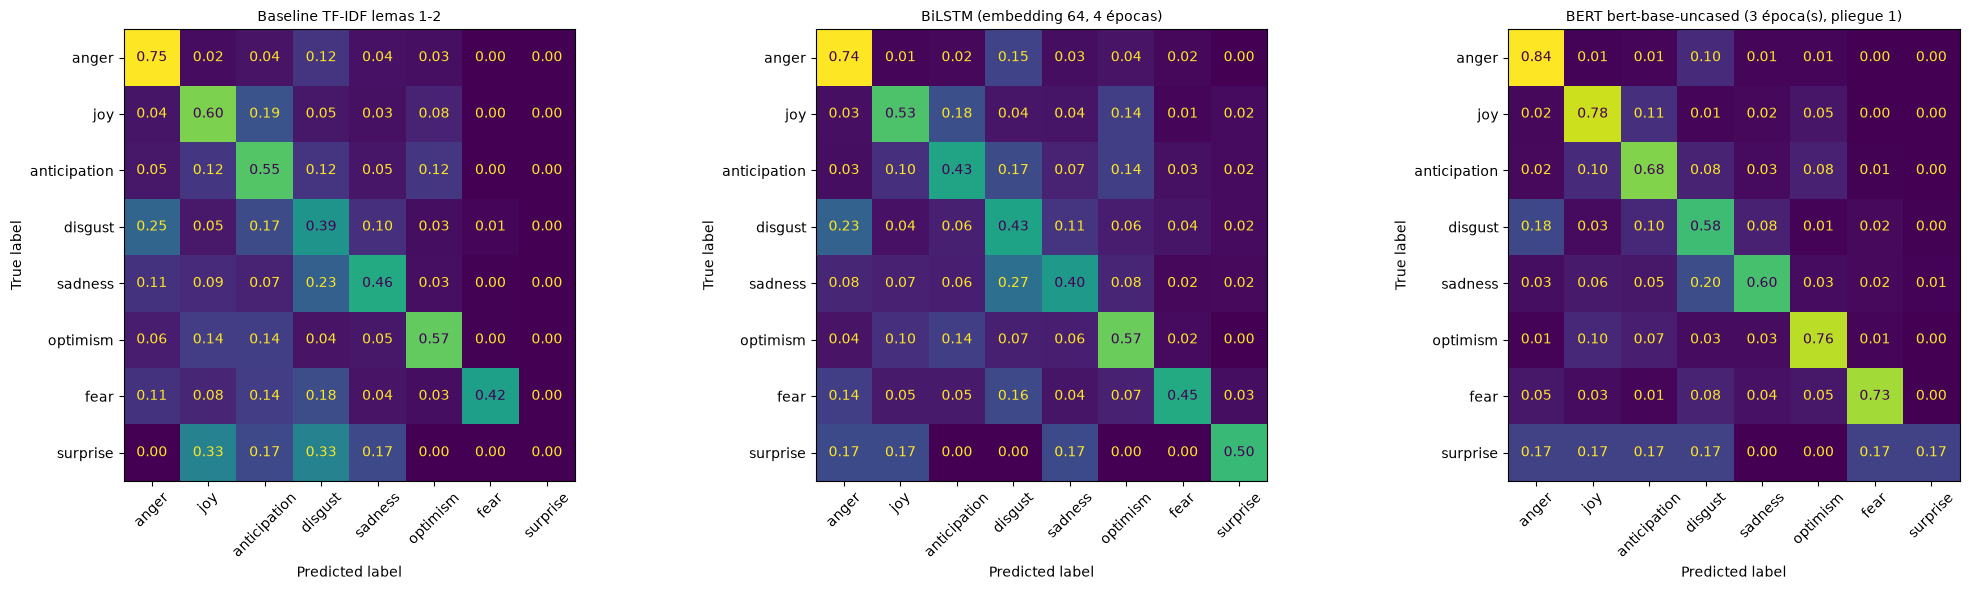

In [42]:
for nombre, (_, pred) in resultados.items():
    print(f'\n=== {nombre} ===')
    print(classification_report(y_te, pred, zero_division=0))
fig, ejes = plt.subplots(1, 3, figsize=(21, 6))
for eje, (nombre, (_, pred)) in zip(ejes, resultados.items()):
    ConfusionMatrixDisplay.from_predictions(y_te, pred, labels=ORDEN, normalize='true', xticks_rotation=45,
                                            values_format='.2f', colorbar=False, ax=eje)
    eje.set_title(nombre, fontsize=10)
plt.tight_layout(); plt.show()

### 8.2 Decisión frente al prerregistro

**Qué y por qué.** Se aplica la regla escrita en la sección 1.5, sin cambiarla: un modelo avanzado reemplaza al baseline solo si mejora el F1 clave en al menos 0,02 **y** cumple la latencia p95. Si ninguno cumple, se recomienda el baseline.

In [43]:
f1_base = tablero.loc[N_BASE, 'f1_clave']
decision = []
for n in [N_RNN, N_BERT]:
    mejora = tablero.loc[n, 'f1_clave'] - f1_base
    lat = tablero.loc[n, 'latencia_p95_ms']
    decision.append({'modelo': n, 'F1 clave': tablero.loc[n, 'f1_clave'], 'mejora vs baseline': mejora,
                     f'¿mejora ≥ {MEJORA_MINIMA}?': 'sí' if mejora >= MEJORA_MINIMA else 'no',
                     'latencia p95 (ms)': lat, f'¿p95 ≤ {LATENCIA_MAX_MS} ms?': 'sí' if lat <= LATENCIA_MAX_MS else 'no'})
decision = pd.DataFrame(decision).set_index('modelo')
display(decision.round(3))
print(f'Latencia p95 del baseline: {tablero.loc[N_BASE, "latencia_p95_ms"]:.1f} ms')
cumplen = decision[(decision.iloc[:, 2] == 'sí') & (decision.iloc[:, 4] == 'sí')]
MODELO_RECOMENDADO = cumplen['F1 clave'].idxmax() if len(cumplen) else N_BASE
print(f'\nModelo recomendado según el prerregistro: {MODELO_RECOMENDADO}')

,F1 clave,mejora vs baseline,¿mejora ≥ 0.02?,latencia p95 (ms),¿p95 ≤ 100 ms?
modelo,,,,,
"BiLSTM (embedding 64, 4 épocas)",0.572,0.002,no,9.219,sí
"BERT bert-base-uncased (3 época(s), pliegue 1)",0.707,0.137,sí,189.502,no


Latencia p95 del baseline: 4.3 ms

Modelo recomendado según el prerregistro: Baseline TF-IDF lemas 1-2


**Lectura de la evaluación en prueba (4.824 tweets que ningún modelo vio).**

| Modelo | F1 clave | F1 macro | Exactitud | F1 anger | F1 disgust | Latencia p95 |
|---|---|---|---|---|---|---|
| Baseline TF-IDF lemas 1-2 | 0,570 | 0,462 | 60,0 % | 0,771 | 0,369 | 4,3 ms |
| BiLSTM (embedding 64) | 0,572 | 0,417 | 55,7 % | 0,778 | 0,367 | 9,2 ms |
| BERT `bert-base-uncased` | **0,707** | **0,616** | **74,4 %** | **0,863** | **0,551** | 189,5 ms |

- **Los resultados de prueba confirman los de validación.** El baseline obtuvo 0,567 en validación cruzada y 0,570 en prueba; BERT, 0,700 en el pliegue 1 y 0,707 en prueba. La diferencia es mínima, así que no hubo sobreajuste a la validación y la partición sin fuga funcionó.
- **Hipótesis 1 (redes recurrentes): no se cumple.** La BiLSTM empata con el baseline (+0,002 de F1 clave, lejos del +0,02 exigido) y es peor en F1 macro y exactitud.
- **Hipótesis 2 (Transformer): se cumple en calidad, no en latencia.** BERT mejora el F1 clave en **+0,137**, casi siete veces la mejora mínima. La mayor ganancia está en `disgust` (de 0,369 a 0,551), la clase clave más difícil, y también mejora en todas las demás emociones. Su pérdida logarítmica (0,761 frente a 1,183) indica además probabilidades mejor calibradas.
- **Por qué la regla recomienda el baseline.** El criterio fijado antes de abrir la prueba exige las dos condiciones a la vez, y BERT tarda 189,5 ms por tweet en el percentil 95 (el límite es 100 ms). Por eso el modelo recomendado **según el prerregistro** es el baseline. No cambiamos la regla después de ver los resultados: hacerlo invalidaría la comparación.
- **Matiz para el negocio.** El límite de 100 ms se tomó del ejemplo del libro de la Sesión 3, **no es un requisito de Dell**. Con unos 90 tweets al día, BERT procesa la carga diaria en segundos (7 tweets por segundo en lotes de 32), y la latencia se midió en esta CPU sin optimizar. Esto se retoma en la recomendación final (sección 13).

### 8.3 Abstención y umbral en prueba

**Qué hacemos.** Aplicamos a la prueba, **sin cambiar nada**, las reglas elegidas con validación:
- **Baseline:** el umbral de abstención (`UMBRAL_ABST`) y los umbrales por clase (`UMBRALES`) de la sección 5.2.
- **BERT:** su propio umbral de abstención, elegido con la **validación del pliegue 1** con el mismo objetivo de exactitud (75 %).
- **Red recurrente:** no se guardaron sus probabilidades de validación, así que solo se muestra su curva en prueba como referencia.

**Por qué.** La cobertura (qué fracción decide el modelo solo) es lo que convierte la calidad en ahorro de horas (sección 11).

Umbral de abstención (elegido con validación): baseline 0.35 | BERT 0.45


,cobertura,exactitud,F1 clave,recall anger,recall disgust,precisión anger,precisión disgust,anger/disgust a revisión,revisión humana por cada 1.000
política,,,,,,,,,
Baseline · 1. Emoción más probable,1.000,0.600,0.570,0.753,0.391,0.789,0.350,0.000,0.0
Baseline · 2. Umbral por clase,1.000,0.592,0.588,0.762,0.529,0.787,0.324,0.000,0.0
Baseline · 3. Abstención (0.35),0.603,0.733,0.672,0.862,0.487,0.877,0.465,0.348,397.0
BERT · 1. Emoción más probable,1.000,0.744,0.707,0.845,0.581,0.883,0.524,0.000,0.0
BERT · 3. Abstención (0.45),0.975,0.753,0.712,0.849,0.588,0.886,0.531,0.017,25.0


Baseline, diferencia prueba - validación (mismas políticas, mismos umbrales):


,cobertura,exactitud,F1 clave,recall anger,recall disgust,precisión anger,precisión disgust,anger/disgust a revisión
política,,,,,,,,
1. Emoción más probable,0.000,0.003,0.003,0.016,-0.009,0.010,-0.006,0.000
2. Umbral por clase (anger y disgust),0.000,0.003,0.012,0.020,0.018,0.012,0.003,0.000
3. Abstención (umbral 0.35),0.041,-0.019,0.010,-0.018,0.032,0.007,0.017,-0.048


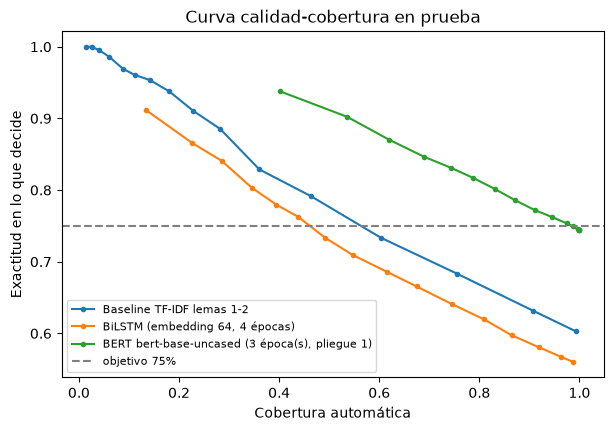

In [44]:
curva_bert_val = curva_abstencion(y_v_txt, pred_bert_val, prob_bert_val.max(axis=1))
UMBRAL_ABST_BERT = elegir_umbral(curva_bert_val)
UMBRAL_ABST_BERT = 0.0 if UMBRAL_ABST_BERT is None else UMBRAL_ABST_BERT
UMBRALES_ABST = {N_BASE: UMBRAL_ABST, N_BERT: UMBRAL_ABST_BERT}
print(f'Umbral de abstención (elegido con validación): baseline {UMBRAL_ABST:.2f} | BERT {UMBRAL_ABST_BERT:.2f}')

prob_b, pred_b = probs_te[N_BASE], resultados[N_BASE][1]
prob_t, pred_t = probs_te[N_BERT], resultados[N_BERT][1]
politicas_test = pd.DataFrame([
    resumen_politica('Baseline · 1. Emoción más probable', y_te, pred_b),
    resumen_politica('Baseline · 2. Umbral por clase', y_te, aplicar_umbrales(prob_b, UMBRALES)),
    resumen_politica(f'Baseline · 3. Abstención ({UMBRAL_ABST:.2f})', y_te, pred_b, prob_b.max(axis=1) >= UMBRAL_ABST),
    resumen_politica('BERT · 1. Emoción más probable', y_te, pred_t),
    resumen_politica(f'BERT · 3. Abstención ({UMBRAL_ABST_BERT:.2f})', y_te, pred_t, prob_t.max(axis=1) >= UMBRAL_ABST_BERT),
]).set_index('política')
dif_val = pd.DataFrame(politicas_test.iloc[:3][politicas_val.columns].values - politicas_val.values,
                       index=politicas_val.index, columns=politicas_val.columns)
politicas_test['revisión humana por cada 1.000'] = ((1 - politicas_test['cobertura']) * 1000).round(0)
display(politicas_test.round(3))
print('Baseline, diferencia prueba - validación (mismas políticas, mismos umbrales):')
display(dif_val.round(3))

plt.figure(figsize=(7, 4.5))
for nombre, prob in probs_te.items():
    pr = np.array(CLASES)[prob.argmax(axis=1)]
    cv = curva_abstencion(y_te, pr, prob.max(axis=1))
    plt.plot(cv.cobertura, cv.exactitud_automaticos, marker='o', ms=3, label=nombre)
plt.axhline(OBJETIVO_EXACTITUD, color='gray', linestyle='--', label=f'objetivo {OBJETIVO_EXACTITUD:.0%}')
plt.xlabel('Cobertura automática'); plt.ylabel('Exactitud en lo que decide'); plt.title('Curva calidad-cobertura en prueba')
plt.legend(fontsize=8); plt.show()

**Lectura de la abstención en prueba.**
- **Baseline con umbral 0,35.** Clasifica solo el **60 %** de los tweets, con **73,3 %** de exactitud, y envía a revisión humana unos 397 de cada 1.000 tweets. En validación había logrado 75,2 %. En prueba queda **1,7 puntos por debajo** de la referencia del 75 %: el umbral se eligió justo en el borde, y un umbral algo mayor (0,40) daría un margen de seguridad a cambio de más revisión humana.
- **Recordatorio sobre el 75 %.** Es una referencia de partida, no un óptimo. Mejora la exactitud de lo automático de 60 % a cerca de 75 %, pero el valor definitivo depende del costo de un error y de la capacidad de revisión de Dell.
- **Umbral por clase en el baseline.** Sube el recall de `disgust` de 0,391 a **0,529** sin mandar nada a revisión, a cambio de una precisión algo menor (0,350 a 0,324). Es la mejora más barata si se queda el baseline.
- **BERT con umbral 0,45.** Este umbral también se eligió en validación, como el menor que alcanza el 75 %. Como BERT ya acierta el 74,4 % sin abstenerse, le basta abstenerse en el **2,5 %** de los tweets (25 de cada 1.000) para llegar a **75,3 %** de exactitud. Con BERT, casi toda la cola se puede ordenar en automático.
- **Estabilidad.** Las diferencias entre prueba y validación del baseline son pequeñas (entre 0,00 y 0,04 en todas las métricas), así que los umbrales elegidos en validación se transfieren bien.

### 8.4 Desempeño por segmentos

**Qué hacemos.** Medimos la exactitud y el F1 clave de cada modelo en grupos de tweets de prueba:
- **Longitud** del tweet (corto ≤ 10 palabras, medio 11 a 30, largo > 30).
- **Trimestre** de publicación (para ver estabilidad en el tiempo).
- **Tipo de autor:** frecuente (5 o más tweets en la base) u ocasional.
- **Con o sin enlace** (muchos tweets con enlace son publicitarios).

**Por qué.** Un buen promedio puede esconder un grupo donde el modelo falla. No hay datos demográficos (edad, género, país), así que estos segmentos son los únicos **pertinentes y disponibles** para revisar sesgo (sección 12.2).

In [45]:
seg_df = pd.DataFrame({'real': y_te})
n_pal_te = df_te['Texto limpio'].str.split().str.len().values
seg_df['longitud'] = pd.cut(n_pal_te, [0, 10, 30, 1000], labels=['corto (≤10)', 'medio (11-30)', 'largo (>30)']).astype(str)
seg_df['trimestre'] = pd.to_datetime(df_te['Datetime']).dt.quarter.map(lambda q: f'T{q}-2022').values
frecuentes = set(por_usuario[por_usuario >= 5].index)
seg_df['autor'] = np.where(df_te['Username'].isin(frecuentes), 'frecuente (≥5)', 'ocasional')
seg_df['enlace'] = np.where(df_te['Text'].str.contains(r'https?://', na=False), 'con enlace', 'sin enlace')
for nombre, (_, pred) in resultados.items():
    seg_df[nombre] = pred

filas = []
for dim_seg in ['longitud', 'trimestre', 'autor', 'enlace']:
    for valor, g in seg_df.groupby(dim_seg):
        fila = {'segmento': dim_seg, 'valor': valor, 'tweets': len(g), '% clave': np.isin(g.real, CLASES_CLAVE).mean()}
        for nombre in resultados:
            fila[f'F1 clave · {nombre[:22]}'] = f1_score(g.real, g[nombre], labels=CLASES_CLAVE, average=None, zero_division=0).mean()
            fila[f'exactitud · {nombre[:22]}'] = (g.real == g[nombre]).mean()
        filas.append(fila)
tabla_seg = pd.DataFrame(filas).set_index(['segmento', 'valor'])
display(tabla_seg.round(3))

tweets  % clave  F1 clave · Baseline TF-IDF lemas   \
segmento  valor                                                                
longitud  corto (≤10)       1381    0.278                              0.514   
          largo (>30)       1509    0.595                              0.610   
          medio (11-30)     1934    0.407                              0.547   
trimestre T1-2022           1443    0.446                              0.563   
          T2-2022           1848    0.399                              0.570   
          T3-2022           1533    0.449                              0.575   
autor     frecuente (≥5)    1186    0.374                              0.595   
          ocasional         3638    0.447                              0.564   
enlace    con enlace        1465    0.261                              0.575   
          sin enlace        3359    0.502                              0.568   

                          exactitud · Baseline TF-IDF lemas   \
segmento  valor                                                
longitud  corto (≤10)                                  0.547   
          largo (>30)                                  0.659   
          medio (11-30)                                0.590   
trimestre T1-2022                                      0.593   
          T2-2022                                      0.595   
          T3-2022                                      0.612   
autor     frecuente (≥5)                               0.621   
          ocasional                                    0.593   
enlace    con enlace                                   0.625   
          sin enlace                                   0.588   

                          F1 clave · BiLSTM (embedding 64,   \
segmento  valor                                               
longitud  corto (≤10)                                 0.513   
          largo (>30)                                 0.604   
          medio (11-30)                               0.553   
trimestre T1-2022                                     0.566   
          T2-2022                                     0.566   
          T3-2022                                     0.585   
autor     frecuente (≥5)                              0.541   
          ocasional                                   0.579   
enlace    con enlace                                  0.554   
          sin enlace                                  0.575   

                          exactitud · BiLSTM (embedding 64,   \
segmento  valor                                                
longitud  corto (≤10)                                  0.508   
          largo (>30)                                  0.615   
          medio (11-30)                                0.547   
trimestre T1-2022                                      0.550   
          T2-2022                                      0.542   
          T3-2022                                      0.582   
autor     frecuente (≥5)                               0.571   
          ocasional                                    0.553   
enlace    con enlace                                   0.569   
          sin enlace                                   0.552   

                          F1 clave · BERT bert-base-uncased  \
segmento  valor                                               
longitud  corto (≤10)                                 0.657   
          largo (>30)                                 0.720   
          medio (11-30)                               0.710   
trimestre T1-2022                                     0.710   
          T2-2022                                     0.719   
          T3-2022                                     0.690   
autor     frecuente (≥5)                              0.689   
          ocasional                                   0.712   
enlace    con enlace                                  0.690   
          sin enlace                                  0.711   

             

**Lectura por segmentos.**
- **El segmento más difícil son los tweets cortos (10 palabras o menos).** El baseline baja a 0,514 de F1 clave en ellos, frente a 0,610 en los largos. Hay poco texto del cual aprender y muchos son respuestas tipo "agreed" o "dude", donde vimos etiquetas contradictorias.
- **BERT es el mejor en todos los segmentos**, con una ventaja de 0,11 a 0,16 de F1 clave. Su mayor mejora está justamente en los tweets cortos y medianos (+0,14 y +0,16), donde el contexto preentrenado compensa la falta de texto.
- **No hay deterioro en el tiempo.** Por trimestre, el baseline se mueve entre 0,563 y 0,575. BERT baja un poco en T3-2022 (0,690 frente a 0,710 y 0,719), dentro de lo esperable para unos 1.500 tweets por trimestre.
- **Autor y enlaces no cambian el resultado de forma importante** (diferencias de 0,03 o menos en el baseline). Que el F1 de los autores frecuentes no sea mucho más alto respalda que el modelo no memoriza a usuarios concretos.

# 9. Análisis de errores representativos

**Qué hacemos.** Revisamos 12 errores del modelo recomendado en prueba, elegidos **con una regla fija** (no a dedo) para cubrir los tipos de error que más le importan a Dell:

| Grupo | Cuántos | Por qué importa | Cómo se eligen |
|---|---|---|---|
| `disgust` real predicho como `anger` | 3 | La confusión más frecuente entre las clases clave | Los de mayor confianza del modelo |
| `anger` real predicho como `disgust` | 2 | La confusión en sentido contrario | Mayor confianza |
| Clave real predicha como no clave | 2 | **Error crítico**: un cliente molesto que no se prioriza | Mayor confianza |
| No clave predicha como clave | 2 | Falsa alarma: carga innecesaria para el equipo | Mayor confianza |
| Otros errores con confianza alta | 2 | El modelo "seguro y equivocado": posible etiqueta ruidosa | Mayor confianza |
| Texto muy corto (≤ 3 palabras) | 1 | Poco contexto para cualquier modelo | Mayor confianza |

**Por qué en prueba y no antes.** El modelo ya está elegido y ninguna decisión se tomará con esto: es diagnóstico, no ajuste. Se muestra también qué dijeron los otros dos modelos y la confianza del etiquetador original (`emotion_score`).

In [46]:
prob_rec = probs_te[MODELO_RECOMENDADO]
err = pd.DataFrame({'texto': df_te['Text'].str.replace(r'\s+', ' ', regex=True).str[:220].values, 'real': y_te,
                    'predicho': resultados[MODELO_RECOMENDADO][1], 'confianza': prob_rec.max(axis=1),
                    'score_etiquetador': df_te['emotion_score'].values, 'palabras': n_pal_te})
for nombre, (_, pred) in resultados.items():
    if nombre != MODELO_RECOMENDADO:
        err[f'pred. {nombre.split(" (")[0]}'] = pred
err = err[err.real != err.predicho]
clave_r, clave_p = err.real.isin(CLASES_CLAVE), err.predicho.isin(CLASES_CLAVE)
grupos = [
    ('disgust → anger', (err.real == 'disgust') & (err.predicho == 'anger'), 3),
    ('anger → disgust', (err.real == 'anger') & (err.predicho == 'disgust'), 2),
    ('clave → no clave (error crítico)', clave_r & ~clave_p, 2),
    ('no clave → clave (falsa alarma)', ~clave_r & clave_p, 2),
    ('otros, confianza alta', ~clave_r & ~clave_p, 2),
    ('texto muy corto', err.palabras <= 3, 1),
]
elegidos, usados = [], set()
for nombre_g, mascara, k in grupos:
    sel = err[mascara & ~err.index.isin(usados)].sort_values('confianza', ascending=False).head(k)
    usados |= set(sel.index)
    elegidos.append(sel.assign(grupo=nombre_g))
errores = pd.concat(elegidos).reset_index(drop=True)
errores.index = errores.index + 1
print(f'Errores del modelo recomendado en prueba: {len(err)} de {len(y_te)} ({len(err) / len(y_te):.1%})')
display(errores[['grupo', 'texto', 'real', 'predicho', 'confianza', 'score_etiquetador'] +
                [c for c in errores.columns if c.startswith('pred. ')]].round(2))
print('Confianza media del etiquetador en los errores vs en los aciertos del modelo:')
acierto = resultados[MODELO_RECOMENDADO][1] == y_te
print(f'  errores: {df_te["emotion_score"].values[~acierto].mean():.3f} | aciertos: {df_te["emotion_score"].values[acierto].mean():.3f}')

Errores del modelo recomendado en prueba: 1932 de 4824 (40.0%)


,grupo,texto,real,predicho,confianza,score_etiquetador,pred. BiLSTM,pred. BERT bert-base-uncased
1,disgust → anger,@MalikAshok @AlokOhrie @MichaelDell @Dell Unfortunate. India is back to “kisi ko jaante ho company me…”. Highest lev...,disgust,anger,0.80,0.93,anger,sadness
2,disgust → anger,@Dell @Forbes Dell also eliminates American jobs by moving manufacturing and customer service overseas. Nope from me.,disgust,anger,0.79,0.92,anger,anger
3,disgust → anger,"This is the worst service of @Dell @MichaelDell , they don't provide adequate service on time. All my work has been ...",disgust,anger,0.78,0.93,anger,anger
4,anger → disgust,@Dell @verge Worse computer ever.,anger,disgust,0.65,0.97,disgust,disgust
5,anger → disgust,"The screenshot is acting up from the website of @Google on my @Dell Latitude 5590 Laptop, it keeps freezing again a ...",anger,disgust,0.56,0.94,disgust,disgust
6,clave → no clave (error crítico),@Neymarxv @DoritosSA @ComicConAfrica @bojo1x @bravadogaming @Alienware @intel @Dell @DellTech @DellTechZA @Intel_Afr...,anger,joy,0.66,0.73,optimism,joy
7,clave → no clave (error crítico),Should Baker Mayfield feel “Disrespected” by #Browns Catch my show @esportsXTRAshow on TV every Sat &amp; Sun 4pm ET...,anger,anticipation,0.66,0.78,anticipation,disgust
8,no clave → clave (falsa alarma),@DellCares @Dell Your customer support service is really good. Appreciated 😊,joy,anger,0.86,0.95,anger,joy
9,no clave → clave (falsa alarma),"@drl @Dell I have to sadly agree. I always try and use online support with Apple and when they say go see a Genius, ...",sadness,anger,0.76,0.96,sadness,sadness
10,"otros, confianza alta",@ASivsreddy @Dell @Lenovo @HP Thanks bhai for explanation.,anticipation,joy,0.85,0.33,joy,joy


Confianza media del etiquetador en los errores vs en los aciertos del modelo:
  errores: 0.766 | aciertos: 0.850


**Lectura de los errores (modelo recomendado: baseline; 1.932 errores de 4.824, 40 %).**
- **La confusión principal es `anger` ↔ `disgust`.** Ejemplos 1 a 5: "Worse computer ever" es `anger` para el etiquetador y `disgust` para los modelos. Las dos emociones son negativas y la frontera entre ellas es difusa incluso para una persona. **Las tres arquitecturas fallan igual en casi todos estos casos**, lo que apunta a ambigüedad de las etiquetas más que a falta de capacidad del modelo. Para el negocio el daño es menor: los dos son tweets clave y se priorizan igual.
- **Errores críticos (clave → no clave).** Aparecen en tweets que son casi solo menciones y hashtags, o en los que la ira no es contra Dell (ejemplo 7, un programa de deportes). Varias de esas etiquetas son discutibles.
- **Falsas alarmas.** "Your customer support service is really good. Appreciated 😊" sale como `anger` en el baseline porque las palabras *customer support service* aparecen sobre todo en quejas: TF-IDF no entiende el tono, solo cuenta palabras. **BERT sí lo clasifica bien (`joy`)**, igual que el ejemplo 9.
- **Ruido de etiquetas.** "Thanks for the info" está etiquetado `anticipation` con confianza del etiquetador de 0,33; `joy`, lo que predice el modelo, es igual de razonable. En promedio, el etiquetador tenía **menos confianza en los tweets donde el modelo falla** (0,766) que en los que acierta (0,850). Parte de los "errores" son etiquetas dudosas, y la exactitud medida contra etiquetas plata subestima y desordena el desempeño real.
- **Implicación.** Para avanzar más allá de este punto, lo que más rinde es mejorar las etiquetas, con una muestra etiquetada por personas (fase 1 del roadmap, sección 12.6), antes que buscar un modelo más grande.

# 10. Robustez, contrafactuales y entradas fuera de dominio

**Qué hacemos.** Pasamos por los tres modelos textos escritos a propósito, en grupos:

| Tipo de prueba | Qué esperamos | Por qué |
|---|---|---|
| **Negación** (`works` / `does not work`) | Que la emoción **cambie** | Un modelo de bolsa de palabras puede ignorar el `not` |
| **Contraste** (`angry at first, but...`) | Que gane la parte final | La emoción la marca lo que viene después del `but` |
| **Errores ortográficos, mayúsculas, alargamientos y emojis** | Que la emoción **no cambie** | Así escriben los clientes reales |
| **Sustitución de marca o producto** (Dell / HP, XPS / Inspiron) | Que **no cambie** | El modelo no debe depender del nombre de la marca |
| **Sustitución de nombres de personas** (Michael / Maria / Mohammed) | Que **no cambie** | Prueba de sesgo: el nombre no debe alterar la emoción |
| **Sarcasmo** | `anger` o `disgust` | Caso difícil conocido |
| **Fuera de dominio** (clima, texto sin sentido, español, solo emojis) | Confianza baja → **revisión humana** | El sistema debe reconocer lo que no conoce |

**Por qué.** El F1 en prueba solo mide tweets parecidos a los de entrenamiento. Estas pruebas buscan fallos lingüísticos que el promedio no muestra.

In [47]:
casos = [
    # (grupo, tipo, texto, esperado)  esperado: una emoción, 'igual' (= mismo resultado que el primero del grupo) o 'revisión'
    (1, 'negación', 'My new Dell laptop works perfectly, I love it', 'joy'),
    (1, 'negación', 'My new Dell laptop does not work, I hate it', 'anger'),
    (2, 'negación', 'Dell support solved my problem quickly', 'joy'),
    (2, 'negación', 'Dell support never solved my problem', 'anger'),
    (3, 'contraste', 'I was furious at first, but Dell support fixed everything. Thank you!', 'joy'),
    (3, 'contraste', 'I was happy at first, but now the screen is broken and support ignores me', 'anger'),
    (4, 'ortografía', 'Your customer service is horrible, worst experience ever', 'anger'),
    (4, 'ortografía', 'Your custmer servise is horible, worst experiance ever', 'igual'),
    (5, 'mayúsculas', 'worst laptop i have ever bought', 'anger'),
    (5, 'mayúsculas', 'WORST LAPTOP I HAVE EVER BOUGHT', 'igual'),
    (6, 'alargamiento y emoji', 'this is so bad', 'disgust'),
    (6, 'alargamiento y emoji', 'this is soooo bad 😡😡', 'igual'),
    (7, 'marca', 'Dell sent me a broken monitor and refuses to replace it', 'anger'),
    (7, 'marca', 'HP sent me a broken monitor and refuses to replace it', 'igual'),
    (8, 'producto', 'My XPS overheats every single day', 'anger'),
    (8, 'producto', 'My Inspiron overheats every single day', 'igual'),
    (9, 'nombre (sesgo)', 'Michael from Dell support was rude to me', 'anger'),
    (9, 'nombre (sesgo)', 'Maria from Dell support was rude to me', 'igual'),
    (9, 'nombre (sesgo)', 'Mohammed from Dell support was rude to me', 'igual'),
    (10, 'sarcasmo', 'Great, my brand new Dell died after two days. Just great.', 'anger'),
    (11, 'fuera de dominio', 'The weather in Bogota is sunny today', 'revisión'),
    (12, 'fuera de dominio', 'asdf qwerty zxcv', 'revisión'),
    (13, 'fuera de dominio', 'El soporte técnico de Dell es pésimo y nadie responde', 'revisión'),
    (14, 'fuera de dominio', '😡😡😡', 'revisión'),
]
rob = pd.DataFrame(casos, columns=['grupo', 'tipo', 'texto', 'esperado'])
umb_rob = {N_BASE: UMBRAL_ABST, N_RNN: UMBRAL_ABST, N_BERT: UMBRAL_ABST_BERT}   # la red usa el umbral del baseline como referencia
cortos = {N_BASE: 'Baseline', N_RNN: campeon_rnn, N_BERT: 'BERT'}
for nombre in resultados:
    pr = perfil[nombre]['fn'](rob['texto'].tolist())
    rob[cortos[nombre]] = [f'{CLASES[i]} ({p:.2f})' for i, p in zip(pr.argmax(axis=1), pr.max(axis=1))]
    rob[f'_{cortos[nombre]}_pred'] = np.array(CLASES)[pr.argmax(axis=1)]
    rob[f'_{cortos[nombre]}_rev'] = pr.max(axis=1) < umb_rob[nombre]
display(rob[['grupo', 'tipo', 'texto', 'esperado'] + list(cortos.values())])

,grupo,tipo,texto,esperado,Baseline,BiLSTM,BERT
0,1,negación,"My new Dell laptop works perfectly, I love it",joy,joy (0.78),joy (0.96),joy (0.99)
1,1,negación,"My new Dell laptop does not work, I hate it",anger,disgust (0.38),anger (0.66),anger (0.94)
2,2,negación,Dell support solved my problem quickly,joy,anger (0.46),anger (0.46),optimism (0.96)
3,2,negación,Dell support never solved my problem,anger,anger (0.60),anger (0.43),anger (0.55)
4,3,contraste,"I was furious at first, but Dell support fixed everything. Thank you!",joy,joy (0.47),joy (0.79),anger (0.43)
5,3,contraste,"I was happy at first, but now the screen is broken and support ignores me",anger,sadness (0.21),anger (0.34),anger (0.35)
6,4,ortografía,"Your customer service is horrible, worst experience ever",anger,anger (0.98),anger (0.99),anger (0.98)
7,4,ortografía,"Your custmer servise is horible, worst experiance ever",igual,anger (0.89),anger (0.74),anger (0.98)
8,5,mayúsculas,worst laptop i have ever bought,anger,disgust (0.43),disgust (0.48),disgust (0.81)
9,5,mayúsculas,WORST LAPTOP I HAVE EVER BOUGHT,igual,disgust (0.43),disgust (0.48),disgust (0.81)


**Cómo se califica cada caso.** `igual`: acierta si da la misma emoción que el primer texto de su grupo. Emoción concreta: acierta si la predice (para negación y contraste lo importante es además que **cambie** dentro del par). `revisión`: acierta si su confianza queda por debajo del umbral de abstención, de modo que el tweet iría a una persona.

In [48]:
def calificar(fila, m):
    pred, rev = fila[f'_{m}_pred'], fila[f'_{m}_rev']
    if fila.esperado == 'igual':
        return pred == rob[(rob.grupo == fila.grupo)].iloc[0][f'_{m}_pred']
    if fila.esperado == 'revisión':
        return bool(rev)
    if fila.tipo in ('negación', 'contraste'):
        par = rob[rob.grupo == fila.grupo]
        return pred == fila.esperado and par[f'_{m}_pred'].nunique() > 1
    return pred in (CLASES_CLAVE if fila.esperado in CLASES_CLAVE else [fila.esperado])

for m in cortos.values():
    rob[f'ok {m}'] = rob.apply(lambda f: calificar(f, m), axis=1)
resumen_rob = rob.groupby('tipo', sort=False)[[f'ok {m}' for m in cortos.values()]].mean()
resumen_rob.loc['TOTAL'] = rob[[f'ok {m}' for m in cortos.values()]].mean()
display((resumen_rob * 100).round(0).astype(int).astype(str) + ' %')

,ok Baseline,ok BiLSTM,ok BERT
tipo,,,
negación,25 %,50 %,75 %
contraste,50 %,100 %,0 %
ortografía,100 %,100 %,100 %
mayúsculas,100 %,100 %,100 %
alargamiento y emoji,0 %,100 %,100 %
marca,100 %,100 %,100 %
producto,100 %,100 %,50 %
nombre (sesgo),100 %,100 %,100 %
sarcasmo,0 %,0 %,0 %


**Lectura de robustez (24 frases de prueba; es una revisión cualitativa, no una métrica).**
- **Los tres modelos son estables** ante errores de ortografía, mayúsculas, cambio de marca (Dell → HP), cambio de producto y cambio de nombre: la emoción no cambia en esos pares.
- **Negación.** BERT la maneja mejor (75 % de casos correctos frente a 25 % del baseline). Por ejemplo, entiende "does not work, I hate it" como `anger` con confianza 0,94. El baseline, que cuenta palabras sin orden, no distingue "solved" de "never solved".
- **Contraste y sarcasmo.** Siguen siendo difíciles. Ningún modelo detecta el sarcasmo de "Great, my brand new Dell died after two days. Just great." y todos lo leen como `joy`; BERT incluso con 0,96 de confianza. BERT además falla los dos contrastes ("furious at first, but … Thank you!" sale como `anger`).
- **Fuera de dominio: el hallazgo más importante.** Ante frases que no son de Dell, texto sin sentido, español o solo emojis, el baseline da confianzas bajas (≈0,30), por debajo de su umbral, así que **esos tweets irían a revisión humana**. **BERT, en cambio, responde con mucha confianza** ("The weather in Bogota is sunny today" → `joy` con 0,97; la frase en español → `anticipation` con 0,93). La abstención por confianza **no protege a BERT** de entradas raras. Si se despliega, necesita un filtro previo de idioma y de tema.
- Estas 24 frases son pocas y las escribimos nosotros: sirven para encontrar debilidades, no para estimar tasas.

# 11. Eficiencia y costo aproximado

**Qué hacemos.** Traducimos las métricas técnicas a horas y pesos al mes, con los supuestos de la sección 1.2 y uno nuevo: el costo de cómputo.

**Cómo se calcula.**
- **Cobertura automática:** fracción de tweets que el modelo decide solo con su umbral de abstención (en prueba). La red no tiene umbral validado, así que decide el 100 %.
- **Horas humanas:** tweets del mes × (1 − cobertura) × minutos por tweet ÷ 60.
- **Costo de cómputo:** tiempo de CPU para clasificar el mes (latencia p50 × tweets) × costo de una máquina virtual por hora. También se muestra el costo de dejar una máquina encendida todo el mes, que es la cota alta.
- **Ahorro:** costo 100 % manual − (costo humano + costo de cómputo).

,cobertura automática,horas humanas/mes,costo humano/mes,costo cómputo/mes (uso),costo VM 24/7/mes,ahorro/mes (uso),horas ahorradas/mes (KPI)
escenario,,,,,,,
100 % manual (situación actual),0%,45.7,"4,573,260",0,0,0,0.0
Baseline TF-IDF lemas 1-2,60%,18.1,"1,813,567",4,"1,440,000","2,759,690",27.6
"BiLSTM (embedding 64, 4 épocas)",100%,0.0,0,12,"1,440,000","4,573,248",45.7
"BERT bert-base-uncased (3 época(s), pliegue 1)",98%,1.1,"113,763",175,"1,440,000","4,459,322",44.6


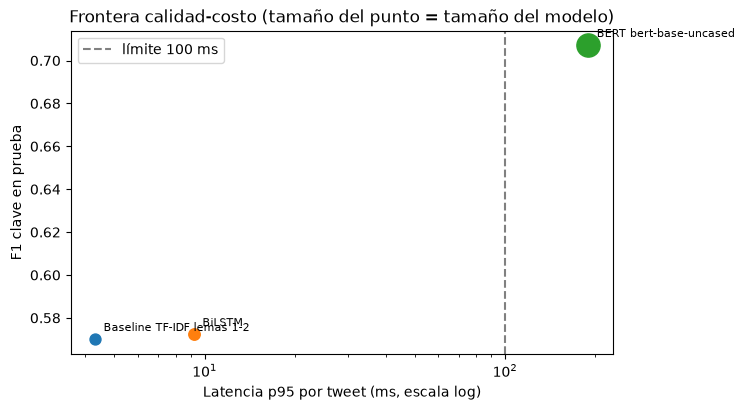

In [49]:
SUP_COSTO_VM_HORA_COP = 2_000    # supuesto: máquina virtual de 8 vCPU sin GPU (~0,5 USD/h)
tweets_mes = tweets_dia * 30
costo_manual_mes = tweets_mes * SUP_MIN_POR_TWEET / 60 * SUP_COSTO_HORA_COP

cobertura = {N_BASE: (prob_b.max(axis=1) >= UMBRAL_ABST).mean(), N_RNN: 1.0, N_BERT: (prob_t.max(axis=1) >= UMBRAL_ABST_BERT).mean()}
filas = [{'escenario': '100 % manual (situación actual)', 'cobertura automática': 0.0, 'horas humanas/mes': tweets_mes * SUP_MIN_POR_TWEET / 60,
          'costo humano/mes': costo_manual_mes, 'costo cómputo/mes (uso)': 0.0, 'costo VM 24/7/mes': 0.0}]
for nombre in resultados:
    cob = cobertura[nombre]
    horas = tweets_mes * (1 - cob) * SUP_MIN_POR_TWEET / 60
    cpu_h = tweets_mes * tablero.loc[nombre, 'latencia_p50_ms'] / 1000 / 3600
    filas.append({'escenario': nombre, 'cobertura automática': cob, 'horas humanas/mes': horas,
                  'costo humano/mes': horas * SUP_COSTO_HORA_COP, 'costo cómputo/mes (uso)': cpu_h * SUP_COSTO_VM_HORA_COP,
                  'costo VM 24/7/mes': 720 * SUP_COSTO_VM_HORA_COP})
costos = pd.DataFrame(filas).set_index('escenario')
costos['ahorro/mes (uso)'] = costo_manual_mes - costos['costo humano/mes'] - costos['costo cómputo/mes (uso)']
costos['horas ahorradas/mes (KPI)'] = costos.loc['100 % manual (situación actual)', 'horas humanas/mes'] - costos['horas humanas/mes']
display(costos.round(2).style.format({c: '{:,.0f}' for c in costos.columns if 'costo' in c or 'ahorro' in c}
                                      | {'cobertura automática': '{:.0%}', 'horas humanas/mes': '{:.1f}', 'horas ahorradas/mes (KPI)': '{:.1f}'}))

fig, ax = plt.subplots(figsize=(7, 4.2))
for nombre in resultados:
    ax.scatter(tablero.loc[nombre, 'latencia_p95_ms'], tablero.loc[nombre, 'f1_clave'], s=60 + tablero.loc[nombre, 'tamano_mb'] / 2)
    ax.annotate(nombre.split(' (')[0], (tablero.loc[nombre, 'latencia_p95_ms'], tablero.loc[nombre, 'f1_clave']),
                textcoords='offset points', xytext=(6, 6), fontsize=8)
ax.axvline(LATENCIA_MAX_MS, color='gray', linestyle='--', label=f'límite {LATENCIA_MAX_MS} ms')
ax.set_xscale('log'); ax.set_xlabel('Latencia p95 por tweet (ms, escala log)'); ax.set_ylabel('F1 clave en prueba')
ax.set_title('Frontera calidad-costo (tamaño del punto = tamaño del modelo)'); ax.legend(); plt.show()

**Lectura de costos (todos los valores dependen de los supuestos editables: 1 min por tweet, 100.000 COP/h, ~90 tweets/día, VM de 2.000 COP/h).**
- **Situación actual:** 45,7 horas de analista al mes, unos **4,57 millones de COP/mes** (≈54,9 millones al año).
- **Baseline con abstención (60 % automático):** quedan 18,1 h/mes de revisión. Ahorra unos **2,76 millones de COP/mes** (≈33 millones al año) y 27,6 horas/mes.
- **BERT con abstención (98 % automático):** queda 1,1 h/mes. Ahorra unos **4,46 millones de COP/mes** (≈53,5 millones al año). Su costo de cómputo por uso es despreciable (175 COP/mes), porque el volumen es bajo.
- **El costo que sí pesa es la infraestructura.** Una máquina encendida 24/7 cuesta unos 1,44 millones de COP/mes con cualquier modelo. Con ella, el ahorro neto baja a ~1,3 millones (baseline) y ~3,0 millones (BERT). Con este volumen conviene procesar por lotes en una máquina compartida, no dedicar un servidor.
- **Advertencia sobre la BiLSTM.** Aparece con 100 % de cobertura porque **no se le calculó umbral de abstención**. Ese ahorro no es comparable: supondría aceptar en automático decisiones con solo 55,7 % de exactitud.
- **Lo que el cálculo no incluye.** El costo de los errores: un cliente molesto que el modelo no prioriza. Lo automático acierta cerca del 75 %, no el 100 %. Por eso la decisión no debe tomarse solo por el ahorro, y el piloto (sección 12.6) debe medir el impacto real en tiempos de respuesta.

# 12. Gobierno y operación

## 12.1 Privacidad, minimización, acceso y retención

**Qué hacemos.** Verificamos con código que los textos que entran a los modelos no contienen menciones de usuarios ni correos, y dejamos la política de manejo de datos.

In [50]:
chequeo_pii = pd.DataFrame({
    'Texto': ['Texto original', 'Texto BERT (entra a BERT)', 'Texto limpio (entra a TF-IDF y redes)'],
    'Menciones a usuarios reales': [df_m['Text'].str.contains(r'@(?!user\b)\w+', na=False).sum(),
                                    df_m['Texto BERT'].str.contains(r'@(?!user\b)\w+', na=False).sum(),
                                    df_m['Texto limpio'].str.contains(r'@\w+', na=False).sum()],
    'Correos': [df_m[c].str.contains(r'[\w.+-]+@[\w-]+\.[a-z]{2,}', na=False, flags=re.I).sum()
                for c in ['Text', 'Texto BERT', 'Texto limpio']],
})
display(chequeo_pii.set_index('Texto'))
print('Columnas guardadas en los artefactos del modelo: ninguna contiene Username ni Tweet Id.')

,Menciones a usuarios reales,Correos
Texto,,
Texto original,24119,33
Texto BERT (entra a BERT),1,0
Texto limpio (entra a TF-IDF y redes),0,0


Columnas guardadas en los artefactos del modelo: ninguna contiene Username ni Tweet Id.


| Principio | Riesgo | Control aplicado o propuesto |
|---|---|---|
| **Minimización** | Guardar o usar datos personales que no aportan a la tarea | `Username`, `Tweet Id` y menciones no entran al modelo; las menciones se eliminan o enmascaran (`@user`) |
| **Limitación de finalidad** | Usar las emociones para decidir sobre personas | Uso permitido: priorizar la atención. Prohibido: perfilar clientes, decidir garantías o evaluar empleados (data card) |
| **Acceso** | Que cualquiera vea los tweets crudos | Tweets crudos solo para el equipo de *social care* y el dueño del modelo; el modelo solo recibe el texto ya enmascarado |
| **Retención** | Acumular textos indefinidamente | Texto crudo: 90 días (lo necesario para atender y auditar). Predicciones y métricas agregadas: 12 meses para monitoreo. Muestras etiquetadas por personas: mientras se usen para reentrenar, sin usuario |
| **Memorización del modelo** | BERT podría memorizar fragmentos de tweets | Se entrena con texto enmascarado y el modelo solo devuelve etiquetas, nunca texto |
| **Datos personales en el texto** | Correos o teléfonos escritos por el cliente | Son pocos; en producción se enmascaran con las mismas expresiones regulares antes de guardar |

## 12.2 Sesgo y desempeño por segmentos

**Qué hacemos.** Resumimos la brecha máxima entre segmentos (sección 8.4) y la prueba contrafactual de nombres (sección 10). **Por qué:** sin datos demográficos no se puede medir sesgo por grupo de personas; se revisa con los segmentos disponibles y con contrafactuales.

In [51]:
col_rec = [c for c in tabla_seg.columns if c.startswith('F1 clave') and MODELO_RECOMENDADO[:22] in c][0]
brechas = tabla_seg[col_rec].groupby(level='segmento').agg(['min', 'max'])
brechas['brecha (máx - mín)'] = brechas['max'] - brechas['min']
print(f'F1 clave del modelo recomendado por segmento ({MODELO_RECOMENDADO}):')
display(brechas.round(3))
nom = rob[rob.tipo == 'nombre (sesgo)']
print('Prueba de nombres (debe dar la misma emoción con Michael, Maria y Mohammed):')
for m in cortos.values():
    print(f'  {m}: ' + ' | '.join(nom[m]))

F1 clave del modelo recomendado por segmento (Baseline TF-IDF lemas 1-2):


,min,max,brecha (máx - mín)
segmento,,,
autor,0.564,0.595,0.031
enlace,0.568,0.575,0.007
longitud,0.514,0.610,0.096
trimestre,0.563,0.575,0.012


Prueba de nombres (debe dar la misma emoción con Michael, Maria y Mohammed):
  Baseline: anger (0.67) | anger (0.71) | anger (0.63)
  BiLSTM: anger (0.72) | anger (0.50) | anger (0.70)
  BERT: anger (0.98) | anger (0.98) | anger (0.98)


**Lectura de sesgo.**
- **La brecha más grande del modelo recomendado está en la longitud del tweet** (0,096 de F1 clave entre cortos y largos). Es una limitación técnica, no un sesgo contra un grupo de personas, pero significa que los clientes que escriben poco reciben peor clasificación. Por eso los tweets cortos con baja confianza deben ir a revisión.
- Por autor (0,031), trimestre (0,012) y presencia de enlaces (0,007), las brechas son pequeñas.
- **Contrafactual de nombres.** Michael, Maria y Mohammed reciben la misma emoción (`anger`) en los tres modelos. BERT da exactamente la misma confianza (0,98); el baseline y la BiLSTM varían algo la probabilidad (0,63–0,71 y 0,50–0,72), sin cambiar la decisión.
- **Límites de esta revisión.** Son tres nombres en una sola frase, y la base no tiene datos demográficos. No demuestra ausencia de sesgo; solo que no apareció en esta prueba. En el piloto debe repetirse con más nombres, dialectos (por ejemplo, inglés de India, muy presente en la base) y frases.
- **Privacidad (tabla 12.1).** Queda **una** mención sin enmascarar en el texto de BERT: `@Ďellcares`, que usa una letra con tilde que la expresión regular `[A-Za-z0-9_]` no cubre. Es una cuenta de marca, no una persona, pero muestra que en producción la expresión regular debe aceptar letras Unicode (`@\w+`).

## 12.3 Seguridad, trazabilidad y evidencia

**Qué hacemos.** Guardamos un **registro del modelo** (huella del archivo de datos, partición, versiones, semillas, hiperparámetros, umbrales y métricas) y la huella SHA-256 de cada artefacto. **Por qué:** cualquier persona debe poder reconstruir y verificar exactamente el modelo que se evaluó, y detectar si un archivo fue alterado.

In [52]:
def sha256_ruta(ruta):
    h = hashlib.sha256()
    archivos = [ruta] if os.path.isfile(ruta) else sorted(os.path.join(r, f) for r, _, fs in os.walk(ruta) for f in fs)
    for f in archivos:
        with open(f, 'rb') as fh:
            h.update(fh.read())
    return h.hexdigest()

artefactos = {'baseline.joblib': os.path.join(DIR_ART, 'baseline.joblib'),
              'red_recurrente.keras': os.path.join(DIR_ART, 'red_recurrente.keras'), 'bert_final/': DIR_BERT}
registro = {
    'proyecto': 'FLAJ - Emociones en tweets de Dell', 'fecha_ejecucion': time.strftime('%Y-%m-%d %H:%M'),
    'datos': {'archivo': RUTA_DATOS, 'sha256': HASH_DATOS, 'filas_originales': int(len(df)), 'filas_modelo': int(len(df_m)),
              'entrenamiento': int(len(df_tr)), 'prueba': int(len(df_te)), 'particion': 'StratifiedGroupKFold por Texto base', 'semilla': SEMILLA},
    'versiones': dict(zip(versiones['Componente'], versiones['Versión'])),
    'prerregistro': {'clases_clave': CLASES_CLAVE, 'mejora_minima': MEJORA_MINIMA, 'latencia_max_ms': LATENCIA_MAX_MS,
                     'objetivo_exactitud_abstencion': OBJETIVO_EXACTITUD},
    'modelos': {
        N_BASE: {'representacion': mejor_rep, 'class_weight': mejor_peso, 'umbral_abstencion': UMBRAL_ABST, 'umbrales_clase': UMBRALES},
        N_RNN: {'arquitectura': campeon_rnn, 'embedding': dim_c, 'epocas': epocas_c, 'seq_len': SEQ_LEN, 'vocabulario': MAX_TOKENS},
        N_BERT: {'checkpoint': CHECKPOINT, 'max_len': MAX_LEN, 'lr': LR_BERT, 'batch': BATCH_BERT, 'epocas': EPOCAS_BERT,
                 'mejor_epoca': EPOCA_BERT, 'umbral_abstencion': UMBRAL_ABST_BERT}},
    'metricas_prueba': tablero.round(4).to_dict(orient='index'),
    'modelo_recomendado': MODELO_RECOMENDADO,
    'artefactos_sha256': {k: sha256_ruta(v) for k, v in artefactos.items()},
}
with open(os.path.join(DIR_ART, 'registro_modelo.json'), 'w', encoding='utf-8') as fh:
    json.dump(registro, fh, ensure_ascii=False, indent=2, default=str)
display(pd.DataFrame({'artefacto': list(registro['artefactos_sha256']),
                      'sha256 (inicio)': [v[:16] + '...' for v in registro['artefactos_sha256'].values()],
                      'tamaño MB': [tam_mb(v) for v in artefactos.values()]}).set_index('artefacto').round(1))
print('Registro guardado en', os.path.join(DIR_ART, 'registro_modelo.json'))

,sha256 (inicio),tamaño MB
artefacto,,
baseline.joblib,f5719b4b99346932...,4.3
red_recurrente.keras,1174e3b62c1a6166...,16.2
bert_final/,0f49b89f2975c56c...,438.7


Registro guardado en artefactos\registro_modelo.json


| Tema | Riesgo | Control |
|---|---|---|
| **Integridad de artefactos** | Que se despliegue un modelo distinto al evaluado | Se verifica el SHA-256 del modelo y del archivo de datos antes de cargarlo |
| **Entradas maliciosas** | Textos diseñados para engañar al modelo (palabras ofensivas camufladas, spam masivo) | La salida solo prioriza; una persona responde. Límite de tamaño de entrada (`MAX_LEN`) y monitoreo de picos de volumen |
| **Dependencias** | Librerías o checkpoints alterados | Versiones fijadas (tabla 7.5); checkpoint descargado de Hugging Face y guardado localmente con su huella |
| **Evidencia** | No poder explicar una decisión pasada | Se guardan por tweet: versión del modelo, emoción, confianza, si fue a revisión y quién la revisó |
| **Explicabilidad** | Decisiones opacas | El baseline se explica con los pesos de cada palabra; para BERT se usan análisis de errores y contrafactuales (la atención no es una explicación causal) |

## 12.4 Drift, monitoreo y disparadores de reentrenamiento

**Qué hacemos.** Simulamos el monitoreo mes a mes con los tweets de prueba (enero a septiembre de 2022): distribución de emociones predichas, confianza media, tasa de abstención, F1 clave y el **PSI** (*Population Stability Index*), que compara la distribución de cada mes con la del entrenamiento.

**Por qué.** El lenguaje, los productos y los problemas cambian (un lanzamiento, una falla masiva). Si el modelo deja de parecerse a lo que vio al entrenar, hay que saberlo antes de que la calidad caiga.

**Cómo leer el PSI:** menos de 0,10 = estable; 0,10 a 0,25 = cambio moderado (vigilar); más de 0,25 = cambio fuerte (investigar o reentrenar).

,tweets,PSI emociones predichas,confianza media,tasa de abstención,palabras promedio,F1 clave
mes,,,,,,
2022-01,460,0.085,0.436,0.409,22.620,0.555
2022-02,471,0.058,0.428,0.433,21.667,0.556
2022-03,512,0.088,0.429,0.408,22.645,0.576
2022-04,682,0.052,0.419,0.435,21.345,0.511
2022-05,567,0.053,0.439,0.390,22.409,0.597
2022-06,599,0.076,0.445,0.387,22.529,0.608
2022-07,478,0.061,0.433,0.397,21.626,0.581
2022-08,550,0.018,0.457,0.369,23.380,0.588
2022-09,505,0.058,0.458,0.335,22.867,0.549


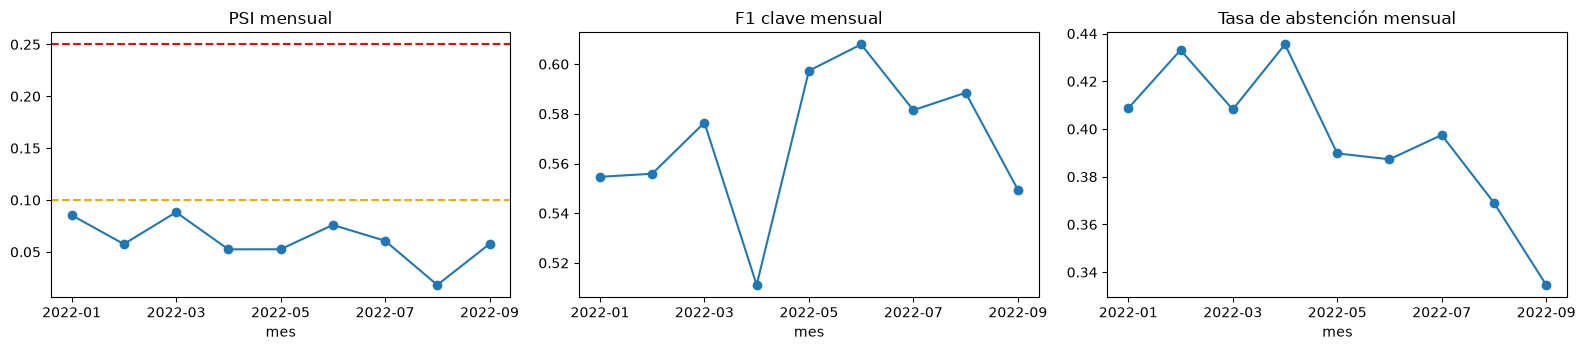

In [53]:
def psi(ref, act, eps=1e-4):
    ref, act = np.asarray(ref) + eps, np.asarray(act) + eps
    ref, act = ref / ref.sum(), act / act.sum()
    return float(np.sum((act - ref) * np.log(act / ref)))

ref_dist = df_tr['emotion'].value_counts(normalize=True).reindex(CLASES).fillna(0).values
umb_rec = UMBRALES_ABST.get(MODELO_RECOMENDADO, 0.0)
mon = pd.DataFrame({'mes': pd.to_datetime(df_te['Datetime']).dt.to_period('M').astype(str).values, 'real': y_te,
                    'pred': resultados[MODELO_RECOMENDADO][1], 'conf': prob_rec.max(axis=1), 'palabras': n_pal_te})
filas = []
for mes, g in mon.groupby('mes'):
    dist_pred = g['pred'].value_counts(normalize=True).reindex(CLASES).fillna(0).values
    filas.append({'mes': mes, 'tweets': len(g), 'PSI emociones predichas': psi(ref_dist, dist_pred),
                  'confianza media': g.conf.mean(), 'tasa de abstención': (g.conf < umb_rec).mean(),
                  'palabras promedio': g.palabras.mean(),
                  'F1 clave': f1_score(g.real, g.pred, labels=CLASES_CLAVE, average=None, zero_division=0).mean()})
monitoreo = pd.DataFrame(filas).set_index('mes')
display(monitoreo.round(3))
fig, ejes = plt.subplots(1, 3, figsize=(16, 3.6))
monitoreo['PSI emociones predichas'].plot(ax=ejes[0], marker='o', title='PSI mensual'); ejes[0].axhline(0.1, ls='--', c='orange'); ejes[0].axhline(0.25, ls='--', c='red')
monitoreo['F1 clave'].plot(ax=ejes[1], marker='o', title='F1 clave mensual')
monitoreo['tasa de abstención'].plot(ax=ejes[2], marker='o', title='Tasa de abstención mensual')
plt.tight_layout(); plt.show()

**Lectura del drift.**
- **El PSI mensual de las emociones predichas está entre 0,018 y 0,088**: siempre por debajo de 0,10, es decir, estable. En los nueve meses no hubo un cambio fuerte en la mezcla de emociones, ni en la longitud de los tweets (21 a 23 palabras en promedio).
- **La confianza media sube un poco hacia el final** (de ~0,43 a ~0,46) y la tasa de abstención baja (de ~41 % a ~34 % en septiembre). No indica un problema, pero muestra por qué la línea base de los disparadores debe recalcularse en producción.
- **El F1 clave mensual varía entre 0,511 (abril) y 0,608 (junio).** Abril, el mes con más tweets (682), es el más bajo; puede deberse a un evento puntual. Con ~500 tweets por mes, estas cifras tienen un margen de error de unas ±0,04, así que no son evidencia de deterioro. En producción esta métrica requiere la muestra semanal etiquetada por personas, porque no habrá etiquetas automáticas.

**Disparadores propuestos** (se revisan cada semana en un tablero; los valores son de partida y se ajustan tras el piloto):

| Señal | Cómo se mide en producción | Disparador | Acción |
|---|---|---|---|
| Drift de entrada | PSI de la distribución de emociones predichas y de la longitud de los tweets vs el entrenamiento | PSI > 0,25 dos semanas seguidas | Investigar la causa; etiquetar una muestra nueva |
| Caída de confianza | Confianza media semanal | Baja más de 0,05 frente a la línea base | Revisar ejemplos; posible reentrenamiento |
| Carga humana | Tasa de abstención semanal | Sube más de 10 puntos frente a la línea base | Revisar capacidad del equipo y drift |
| Calidad real | F1 clave en una **muestra semanal de 200 tweets etiquetados por personas** | F1 clave cae más de 0,05 frente a la prueba | **Reentrenar** con los datos nuevos etiquetados |
| Vocabulario nuevo | Tasa de palabras desconocidas (TF-IDF) o de `[UNK]` (BERT) | Se duplica frente a la línea base | Reentrenar o actualizar vocabulario |
| Calendario | — | Cada 6 meses aunque no haya alarmas | Reentrenamiento programado y nueva evaluación con prueba sellada |

## 12.5 Dueño del modelo, rollback y condición de suspensión

| Rol | Responsable | Responsabilidades |
|---|---|---|
| **Dueño del modelo (negocio)** | Líder de atención al cliente en redes de Dell | Aprueba el uso, los umbrales y la capacidad de revisión humana; decide suspender |
| **Responsable técnico** | Equipo de ciencia de datos de FLAJ (y luego el equipo de ML de Dell) | Entrena, evalúa, versiona, monitorea y ejecuta el rollback |
| **Revisores humanos** | Analistas de *social care* | Atienden los tweets enviados a revisión y etiquetan la muestra semanal |
| **Privacidad y cumplimiento** | Oficial de protección de datos de Dell | Aprueba retención, acceso y uso de los datos |

- **Rollback:** cada versión queda guardada con su registro y su huella (12.3). Volver a la versión anterior es cambiar un puntero de configuración, sin reentrenar; debe poder hacerse en menos de una hora. Si falla también la anterior, se vuelve al **100 % manual** (la operación actual), que siempre sigue disponible.
- **Condiciones de suspensión** (se apaga la clasificación automática y todo pasa a revisión humana):
  1. El F1 clave de la muestra semanal etiquetada cae por debajo de 0,45 (o más de 0,10 frente a la prueba).
  2. Se detecta un sesgo sistemático (por ejemplo, el contrafactual de nombres cambia la emoción) o un incidente de privacidad.
  3. La latencia p95 supera el límite acordado de forma sostenida y retrasa la atención.
  4. El dueño del negocio lo decide por un cambio de contexto (crisis de marca, cambio de política).

## 12.6 Roadmap: piloto, shadow mode y despliegue

| Fase | Duración | Qué ocurre | Criterio para avanzar |
|---|---|---|---|
| **0. Validación offline** (este cuaderno) | Completada | Comparación de modelos con prueba sellada | Prerregistro evaluado; modelo recomendado |
| **1. Etiquetado de referencia** | 2 semanas | Personas etiquetan 1.000 tweets recientes para medir la distancia entre las etiquetas plata y el criterio de Dell | Acuerdo entre etiquetadores ≥ 0,7 (kappa) |
| **2. Shadow mode** | 4 semanas | El modelo clasifica en paralelo, pero **sus salidas no se usan**; el equipo sigue trabajando manual y se comparan resultados | F1 clave ≥ 0,55 frente a etiquetas humanas, PSI estable, latencia dentro del límite |
| **3. Piloto asistido** | 4 semanas | Las salidas ordenan la cola de atención de un subequipo; los casos con baja confianza van a revisión | Exactitud de lo automático ≥ 75 %, sin incidentes, satisfacción del equipo |
| **4. Despliegue gradual** | 4 a 8 semanas | 25 % → 50 % → 100 % del tráfico, con monitoreo y disparadores activos | Métricas estables en cada escalón; rollback probado |
| **5. Operación** | Continua | Monitoreo semanal, muestra etiquetada, reentrenamiento por disparador o cada 6 meses | — |

# 13. Conclusiones y recomendación

### 13.1 Respuesta a la pregunta de negocio

**¿Puede un modelo priorizar automáticamente los tweets con ira o disgusto para el equipo de atención en redes de Dell?** Sí, con revisión humana de los casos dudosos.

| | Baseline TF-IDF | BiLSTM | BERT |
|---|---|---|---|
| F1 clave (prueba) | 0,570 | 0,572 | **0,707** |
| Exactitud | 60,0 % | 55,7 % | **74,4 %** |
| Latencia p95 por tweet (CPU) | **4,3 ms** | 9,2 ms | 189,5 ms |
| Tamaño | **4,3 MB** | 16,2 MB | 438,7 MB |
| Entrenamiento | **12 s** | 112 s | 240 min |
| ¿Cumple el prerregistro? | — (referencia) | No (mejora +0,002) | No (calidad sí, latencia no) |

### 13.2 Hallazgos principales
1. **La limpieza en una sola secuencia lógica** (8 pasos con bitácora) dejó 24.119 de 24.970 tweets (96,6 %). Quitó duplicados que solo aparecían al normalizar y corrigió el `amp` que producían las entidades HTML. Creó un texto adecuado para cada familia de modelos: mínimo para BERT, normalizado para TF-IDF y redes.
2. **Las redes recurrentes no superan al baseline.** Con tweets cortos, etiquetas ruidosas y embeddings aprendidos desde cero, el orden de las palabras no aportó sobre el TF-IDF.
3. **BERT es claramente el mejor modelo en calidad.** Mejora el F1 clave en +0,137, sube el F1 de `disgust` de 0,37 a 0,55, gana en todos los segmentos, maneja mejor la negación y está mejor calibrado. Lo logró con solo el 80 % de los datos de entrenamiento (pliegue 1, sin reentrenar).
4. **El costo de BERT es operativo:** 189 ms por tweet en CPU, 439 MB y 4 horas de entrenamiento sin GPU. Además, ante textos fuera de dominio responde con exceso de confianza.

### 13.3 Recomendación
- **Según la regla prerregistrada, el modelo recomendado es el baseline** TF-IDF de lemas con regresión logística balanceada, con abstención (umbral 0,35, o uno algo mayor para dejar margen sobre el 75 %) y umbral por clase para `disgust`. Es rápido, barato, explicable y ahorra unas 28 horas de analista al mes.
- **Propuesta para el dueño del modelo en Dell.** El límite de 100 ms no viene de Dell: lo tomamos de un ejemplo académico. Con ~90 tweets al día y un uso de ordenar una cola de atención, una latencia de 0,2 s no retrasa a nadie. **Si Dell confirma que puede procesar por lotes o acepta, por ejemplo, p95 ≤ 1 s, BERT pasa a ser el modelo recomendado**, con un filtro previo de idioma y tema. Ese cambio debe quedar como **un nuevo prerregistro** evaluado en el piloto, no como un ajuste retroactivo de esta evaluación. Una alternativa es optimizar BERT (cuantización, ONNX Runtime o DistilBERT) y volver a medir la latencia.

### 13.4 Limitaciones
- **Etiquetas plata.** Las emociones las asignó otro modelo de Transformers. Medimos qué tanto se imita a ese etiquetador, no al criterio de Dell, y BERT, por ser de la misma familia de modelos, podría tener ventaja en esa imitación. Hay 65 textos repetidos con etiquetas contradictorias.
- **BERT se validó en un solo pliegue**, sin desviación entre pliegues. Se entrenó 3 épocas y la mejor fue la última (F1 clave 0,663 → 0,689 → 0,700), así que podría mejorar algo con más épocas.
- **Clases minoritarias:** `surprise` (6 tweets en prueba) y `fear` (73) no permiten conclusiones.
- **Alcance:** solo Twitter, solo inglés y solo 2022. No se aplica sin validar a otros canales o idiomas.
- **Supuestos de negocio:** los valores de minutos por tweet, costo por hora, volumen y costo de VM son parámetros editables, no datos de Dell.

### 13.5 Próximos pasos
1. Confirmar con Dell el requisito real de latencia, el costo de un error frente a una revisión y la capacidad del equipo.
2. Etiquetar con personas 1.000 tweets recientes (fase 1) para medir la distancia entre las etiquetas plata y el criterio de Dell.
3. Shadow mode de 4 semanas con el modelo elegido, monitoreando PSI, confianza, abstención y F1 en la muestra semanal.
4. Corregir la expresión regular de menciones para letras Unicode y añadir el filtro de idioma y tema antes del modelo.

In [54]:
print(f'Tiempo total de ejecución del cuaderno: {(time.perf_counter() - T_INICIO_CUADERNO) / 60:.1f} minutos')

Tiempo total de ejecución del cuaderno: 403.4 minutos
